# Tahap 2 — Descriptive Analytics Portofolio Pinjaman Bondora

Notebook ini menyajikan analisis deskriptif menyeluruh (**"apa yang terjadi?"**) pada dataset bersih `data/processed/bondora_clean.parquet` (`179.235` baris × `126` kolom) mengacu pada `data/processed/schema.json`.

### Aturan Metodologis Utama
1. **Pemisahan Dua Populasi Secara Ketat:**
   - **Statistik Portofolio** (jumlah pinjaman, nominal pencairan, suku bunga, tenor, profil peminjam, tren waktu): menggunakan **seluruh portofolio (`n = 179.235` baris)**.
   - **Statistik Hasil Akhir Default & Pengembalian (`default`, `return_ratio`)**: menggunakan **hanya pinjaman yang sudah selesai/resolved (`is_resolved == True`, `n = 113.560` baris)**. Pinjaman yang masih berjalan (`is_resolved == False`, `n = 65.675` baris) memiliki nilai `default = <NA>` (*right-censored*) dan **bukan** berarti tidak default.
2. **Tanpa Klaim Sebab-Akibat:** Seluruh narasi pada tahap ini bersifat observasional (menggunakan istilah *tercatat*, *tampak*, *lebih tinggi/rendah*). Analisis penyebab dan uji hipotesis dikerjakan di Tahap 3 (Diagnostic Analytics).
3. **Kejujuran Label Kategorikal:** Variabel berkode angka (`Education`, `MaritalStatus`, `UseOfLoan`, dll.) ditampilkan apa adanya sesuai kode sumber dengan kode `-1` dipisahkan sebagai `-1 (Not set)` (`TODO: label resmi menunggu pengguna`).

In [1]:
# Preflight & Setup Pustaka
from __future__ import annotations

import json
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import DATA_PROCESSED, FIGURES_DIR, REPORT_DATE, TABLES_DIR
from src.utils.plotting import OUTCOME_PALETTE, fmt_id, save_fig, set_style
from src.analysis.descriptive import (
    OUTCOME_CATEGORIES,
    default_rate_by,
    freq_table,
    make_outcome_group,
    numeric_summary,
    outcome_mix_by,
    weighted_return_ratio,
    wilson_ci,
)

set_style()
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(DATA_PROCESSED / 'bondora_clean.parquet')
with open(DATA_PROCESSED / 'schema.json', 'r', encoding='utf-8') as f:
    schema_data = json.load(f)

# Verifikasi 6 Angka Acuan Preflight dari Tahap 1
preflight_checks = {
    'Dimensi (baris, kolom)': df.shape,
    'default.notna().sum()': int(df['default'].notna().sum()),
    'default.sum()': int(df['default'].sum()),
    'default.isna().sum()': int(df['default'].isna().sum()),
    'UserName unik': int(df['UserName'].nunique(dropna=True)),
    'Mean return_ratio (is_resolved == True)': round(float(df.loc[df['is_resolved'] == True, 'return_ratio'].mean()), 4),
}
for k, v in preflight_checks.items():
    print(f'{k:42s}: {v}')

assert df.shape == (179235, 126), f'Dimensi tidak sesuai: {df.shape}'
assert int(df['default'].notna().sum()) == 113560
assert int(df['default'].sum()) == 71864
assert int(df['default'].isna().sum()) == 65675
assert int(df['UserName'].nunique(dropna=True)) == 85087
assert abs(float(df.loc[df['is_resolved'] == True, 'return_ratio'].mean()) - 0.7562) < 1e-4
print('\n[OK] Seluruh pemeriksaan Preflight Tahap 1 terbukti sesuai acuan.')

Dimensi (baris, kolom)                    : (179235, 126)
default.notna().sum()                     : 113560
default.sum()                             : 71864
default.isna().sum()                      : 65675
UserName unik                             : 85087
Mean return_ratio (is_resolved == True)   : 0.7562

[OK] Seluruh pemeriksaan Preflight Tahap 1 terbukti sesuai acuan.


## Bagian A — KPI Portofolio (`02_kpi_portofolio.csv`)

Bagian ini merangkum indikator kinerja utama (KPI) portofolio secara keseluruhan (`n = 179.235`) dan metrik hasil akhir pada subset pinjaman yang telah selesai (`is_resolved == True`, `n = 113.560`). Setiap indikator disertai **pembilang**, **penyebut**, dan **jumlah observasi (`n`)**.

In [2]:
# Tambahkan kolom kelompok hasil 4 kategori di memori
df = df.assign(outcome_group=make_outcome_group(df))

n_total = len(df)
n_unique_users = int(df['UserName'].nunique(dropna=True))
n_prev_loan_rows = int((df['NoOfPreviousLoansBeforeLoan'].fillna(0) > 0).sum())
pct_prev_loan_rows = n_prev_loan_rows / n_total * 100.0

n_new_credit_true = int((df['NewCreditCustomer'] == True).sum())
n_new_credit_false = int((df['NewCreditCustomer'] == False).sum())
pct_new_credit_true = n_new_credit_true / n_total * 100.0
pct_new_credit_false = n_new_credit_false / n_total * 100.0

total_amount_eur = float(df['Amount'].sum())
mean_amount_eur = float(df['Amount'].mean())
median_amount_eur = float(df['Amount'].median())

mean_interest_simple = float(df['Interest'].mean())
median_interest = float(df['Interest'].median())
interest_x_amount_sum = float((df['Interest'] * df['Amount']).sum())
mean_interest_weighted = interest_x_amount_sum / total_amount_eur

mean_duration = float(df['LoanDuration'].mean())
median_duration = float(df['LoanDuration'].median())

og_counts = df['outcome_group'].value_counts()
n_res = int((df['is_resolved'] == True).sum())
pct_res = n_res / n_total * 100.0

df_res = df.loc[df['is_resolved'] == True]
n_def_res = int((df_res['default'] == 1).sum())
def_rate_res = n_def_res / n_res * 100.0

amt_res_total = float(df_res['Amount'].sum())
amt_res_def = float(df_res.loc[df_res['default'] == 1, 'Amount'].sum())
def_rate_res_weighted = amt_res_def / amt_res_total * 100.0

rr_stats = weighted_return_ratio(df)

kpi_rows = [
    {'kategori': 'Skala Portofolio', 'metrik': 'Total pinjaman (baris)', 'populasi': 'Seluruh portofolio', 'pembilang': n_total, 'penyebut': n_total, 'n': n_total, 'nilai': n_total, 'satuan': 'pinjaman'},
    {'kategori': 'Skala Portofolio', 'metrik': 'Peminjam unik (UserName)', 'populasi': 'Seluruh portofolio', 'pembilang': n_unique_users, 'penyebut': n_total, 'n': n_total, 'nilai': n_unique_users, 'satuan': 'peminjam'},
    {'kategori': 'Skala Portofolio', 'metrik': 'Pinjaman dari peminjam dengan riwayat pinjaman sebelumnya (NoOfPreviousLoansBeforeLoan > 0)', 'populasi': 'Seluruh portofolio', 'pembilang': n_prev_loan_rows, 'penyebut': n_total, 'n': n_total, 'nilai': round(pct_prev_loan_rows, 4), 'satuan': '%'},
    {'kategori': 'Pelanggan Kredit', 'metrik': 'Proporsi NewCreditCustomer == True (pelanggan baru Bondora)', 'populasi': 'Seluruh portofolio', 'pembilang': n_new_credit_true, 'penyebut': n_total, 'n': n_total, 'nilai': round(pct_new_credit_true, 4), 'satuan': '%'},
    {'kategori': 'Pelanggan Kredit', 'metrik': 'Proporsi NewCreditCustomer == False (existing customer >=3 bulan)', 'populasi': 'Seluruh portofolio', 'pembilang': n_new_credit_false, 'penyebut': n_total, 'n': n_total, 'nilai': round(pct_new_credit_false, 4), 'satuan': '%'},
    {'kategori': 'Nominal & Harga', 'metrik': 'Total nominal Amount dicairkan', 'populasi': 'Seluruh portofolio', 'pembilang': round(total_amount_eur, 2), 'penyebut': n_total, 'n': n_total, 'nilai': round(total_amount_eur, 2), 'satuan': 'EUR'},
    {'kategori': 'Nominal & Harga', 'metrik': 'Rata-rata Amount dicairkan', 'populasi': 'Seluruh portofolio', 'pembilang': round(total_amount_eur, 2), 'penyebut': n_total, 'n': n_total, 'nilai': round(mean_amount_eur, 4), 'satuan': 'EUR'},
    {'kategori': 'Nominal & Harga', 'metrik': 'Median Amount dicairkan', 'populasi': 'Seluruh portofolio', 'pembilang': np.nan, 'penyebut': n_total, 'n': n_total, 'nilai': round(median_amount_eur, 4), 'satuan': 'EUR'},
    {'kategori': 'Nominal & Harga', 'metrik': 'Rata-rata suku bunga Interest (sederhana)', 'populasi': 'Seluruh portofolio', 'pembilang': round(float(df["Interest"].sum()), 2), 'penyebut': n_total, 'n': n_total, 'nilai': round(mean_interest_simple, 4), 'satuan': '%'},
    {'kategori': 'Nominal & Harga', 'metrik': 'Rata-rata suku bunga Interest (berbobot Amount)', 'populasi': 'Seluruh portofolio', 'pembilang': round(interest_x_amount_sum, 2), 'penyebut': round(total_amount_eur, 2), 'n': n_total, 'nilai': round(mean_interest_weighted, 4), 'satuan': '%'},
    {'kategori': 'Nominal & Harga', 'metrik': 'Median suku bunga Interest', 'populasi': 'Seluruh portofolio', 'pembilang': np.nan, 'penyebut': n_total, 'n': n_total, 'nilai': round(median_interest, 4), 'satuan': '%'},
    {'kategori': 'Nominal & Harga', 'metrik': 'Rata-rata tenor LoanDuration', 'populasi': 'Seluruh portofolio', 'pembilang': int(df["LoanDuration"].sum()), 'penyebut': n_total, 'n': n_total, 'nilai': round(mean_duration, 4), 'satuan': 'bulan'},
    {'kategori': 'Nominal & Harga', 'metrik': 'Median tenor LoanDuration', 'populasi': 'Seluruh portofolio', 'pembilang': np.nan, 'penyebut': n_total, 'n': n_total, 'nilai': round(median_duration, 4), 'satuan': 'bulan'},
]

for cat in OUTCOME_CATEGORIES:
    cnt = int(og_counts[cat])
    kpi_rows.append({'kategori': 'Komposisi 4 Kelompok Hasil', 'metrik': f'Kelompok: {cat}', 'populasi': 'Seluruh portofolio', 'pembilang': cnt, 'penyebut': n_total, 'n': n_total, 'nilai': round(cnt / n_total * 100.0, 4), 'satuan': '%'})

kpi_rows.extend([
    {'kategori': 'Resolusi & Risiko Default', 'metrik': 'Proporsi pinjaman selesai/resolved (is_resolved == True)', 'populasi': 'Seluruh portofolio', 'pembilang': n_res, 'penyebut': n_total, 'n': n_total, 'nilai': round(pct_res, 4), 'satuan': '%'},
    {'kategori': 'Resolusi & Risiko Default', 'metrik': 'Default rate (sederhana, jumlah ÷ n resolved)', 'populasi': 'is_resolved == True', 'pembilang': n_def_res, 'penyebut': n_res, 'n': n_res, 'nilai': round(def_rate_res, 4), 'satuan': '%'},
    {'kategori': 'Resolusi & Risiko Default', 'metrik': 'Default rate berbobot Amount (EUR default ÷ EUR resolved)', 'populasi': 'is_resolved == True', 'pembilang': round(amt_res_def, 2), 'penyebut': round(amt_res_total, 2), 'n': n_res, 'nilai': round(def_rate_res_weighted, 4), 'satuan': '%'},
    {'kategori': 'Pengembalian (Return Ratio)', 'metrik': 'Return ratio rata-rata sederhana (is_resolved == True)', 'populasi': 'is_resolved == True', 'pembilang': round(float(df_res["return_ratio"].sum()), 4), 'penyebut': n_res, 'n': n_res, 'nilai': round(float(rr_stats["simple_mean_return_ratio"]), 4), 'satuan': 'rasio'},
    {'kategori': 'Pengembalian (Return Ratio)', 'metrik': 'Return ratio median (is_resolved == True)', 'populasi': 'is_resolved == True', 'pembilang': np.nan, 'penyebut': n_res, 'n': n_res, 'nilai': round(float(rr_stats["median_return_ratio"]), 4), 'satuan': 'rasio'},
    {'kategori': 'Pengembalian (Return Ratio)', 'metrik': 'Return ratio berbobot Amount (total pembayaran ÷ total Amount resolved)', 'populasi': 'is_resolved == True', 'pembilang': round(float(rr_stats["numerator_total_payments"]), 2), 'penyebut': round(float(rr_stats["denominator_total_amount"]), 2), 'n': n_res, 'nilai': round(float(rr_stats["weighted_return_ratio"]), 4), 'satuan': 'rasio'},
])

for st_val, st_cnt in df['Status'].value_counts().items():
    kpi_rows.append({'kategori': 'Distribusi Status Mentah', 'metrik': f'Status: {st_val}', 'populasi': 'Seluruh portofolio', 'pembilang': int(st_cnt), 'penyebut': n_total, 'n': n_total, 'nilai': round(int(st_cnt) / n_total * 100.0, 4), 'satuan': '%'})

for c_val, c_cnt in df['Country'].value_counts().items():
    kpi_rows.append({'kategori': 'Distribusi Negara (Country)', 'metrik': f'Country: {c_val}', 'populasi': 'Seluruh portofolio', 'pembilang': int(c_cnt), 'penyebut': n_total, 'n': n_total, 'nilai': round(int(c_cnt) / n_total * 100.0, 4), 'satuan': '%'})

kpi_df = pd.DataFrame(kpi_rows)
kpi_df.to_csv(TABLES_DIR / '02_kpi_portofolio.csv', index=False)
display(kpi_df)

,kategori,metrik,populasi,pembilang,penyebut,n,nilai,satuan
0,Skala Portofolio,Total pinjaman (baris),Seluruh portofolio,1.792350e+05,1.792350e+05,179235,1.792350e+05,pinjaman
1,Skala Portofolio,Peminjam unik (UserName),Seluruh portofolio,8.508700e+04,1.792350e+05,179235,8.508700e+04,peminjam
2,Skala Portofolio,Pinjaman dari peminjam dengan riwayat pinjaman sebelumnya (NoOfPreviousLoansBeforeLoan > 0),Seluruh portofolio,9.419400e+04,1.792350e+05,179235,5.255340e+01,%
3,Pelanggan Kredit,Proporsi NewCreditCustomer == True (pelanggan baru Bondora),Seluruh portofolio,1.004020e+05,1.792350e+05,179235,5.601700e+01,%
4,Pelanggan Kredit,Proporsi NewCreditCustomer == False (existing customer >=3 bulan),Seluruh portofolio,7.883300e+04,1.792350e+05,179235,4.398300e+01,%
5,Nominal & Harga,Total nominal Amount dicairkan,Seluruh portofolio,4.558794e+08,1.792350e+05,179235,4.558794e+08,EUR
6,Nominal & Harga,Rata-rata Amount dicairkan,Seluruh portofolio,4.558794e+08,1.792350e+05,179235,2.543473e+03,EUR
7,Nominal & Harga,Median Amount dicairkan,Seluruh portofolio,NaN,1.792350e+05,179235,2.125000e+03,EUR
8,Nominal & Harga,Rata-rata suku bunga Interest (sederhana),Seluruh portofolio,6.155985e+06,1.792350e+05,179235,3.434590e+01,%
9,Nominal & Harga,Rata-rata suku bunga Interest (berbobot Amount),Seluruh portofolio,1.510445e+10,4.558794e+08,179235,3.313250e+01,%


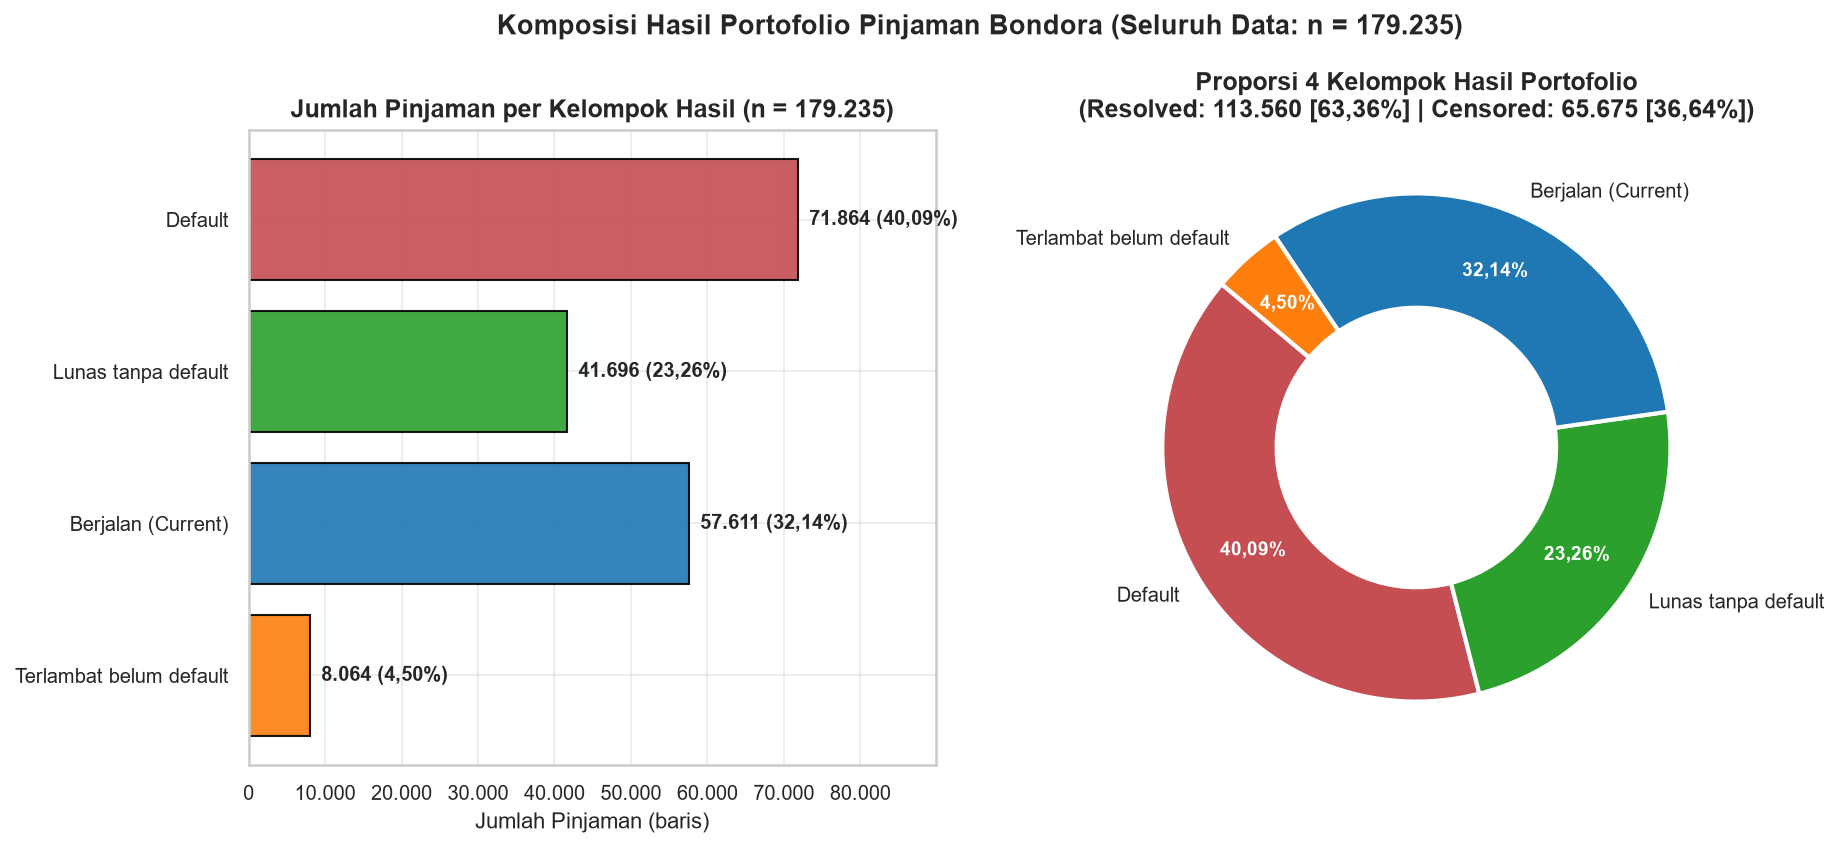

In [3]:
# Visualisasi Komposisi 4 Kelompok Hasil -> reports/figures/02_outcome_composition.png
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
cats = OUTCOME_CATEGORIES
vals = [int(og_counts[c]) for c in cats]
pcts = [v / n_total * 100.0 for v in vals]
colors = [OUTCOME_PALETTE[c] for c in cats]

bars = axes[0].barh(cats[::-1], vals[::-1], color=colors[::-1], edgecolor='black', alpha=0.9)
axes[0].set_title(f'Jumlah Pinjaman per Kelompok Hasil (n = {fmt_id(n_total, is_int=True)})')
axes[0].set_xlabel('Jumlah Pinjaman (baris)')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: fmt_id(x, is_int=True)))
axes[0].set_xlim(0, max(vals) * 1.25)
for bar, v, p in zip(bars, vals[::-1], pcts[::-1]):
    axes[0].text(bar.get_width() + max(vals) * 0.02, bar.get_y() + bar.get_height() / 2, f'{fmt_id(v, is_int=True)} ({fmt_id(p, 2)}%)', va='center', fontsize=9.5, fontweight='bold')

wedges, texts, autotexts = axes[1].pie(
    vals, labels=cats, autopct=lambda p: f'{fmt_id(p, 2)}%', startangle=140, colors=colors,
    pctdistance=0.76, wedgeprops={'width': 0.45, 'edgecolor': 'white', 'linewidth': 2}
)
for at in autotexts:
    at.set_fontsize(9)
    at.set_fontweight('bold')
    at.set_color('white')
axes[1].set_title(f'Proporsi 4 Kelompok Hasil Portofolio\n(Resolved: {fmt_id(n_res, is_int=True)} [{fmt_id(pct_res, 2)}%] | Censored: {fmt_id(n_total - n_res, is_int=True)} [{fmt_id(100 - pct_res, 2)}%])')
fig.suptitle('Komposisi Hasil Portofolio Pinjaman Bondora (Seluruh Data: n = 179.235)', fontsize=13, fontweight='bold', y=1.02)
save_fig(fig, '02_outcome_composition.png', close=False)
plt.show()
plt.close(fig)

### Ringkasan Observasi Bagian A (KPI Portofolio)
- **Skala & Peminjam Berulang:** Portofolio terdiri atas **179.235** pinjaman dari **85.087** peminjam unik (`UserName`). Sebanyak **94.194** pinjaman (**52,55%**) berasal dari peminjam yang memiliki riwayat pinjaman sebelumnya di Bondora (`NoOfPreviousLoansBeforeLoan > 0`), sementara berdasarkan kolom `NewCreditCustomer`, tercatat **100.402** pinjaman (**56,02%**) bernilai `True` dan **78.833** (**43,98%**) bernilai `False`. *(Catatan definisi: `NewCreditCustomer = True` berarti peminjam belum memiliki riwayat kredit >= 3 bulan di Bondora, sehingga berbeda dari `NoOfPreviousLoansBeforeLoan > 0`; definisi bersumber dari dokumentasi API pihak ketiga — **belum terverifikasi dengan sumber resmi**.)*
- **Nominal, Bunga, dan Tenor:** Total dana yang dicairkan (`Amount`) mencapai **455.879.387,31 EUR** (sekitar **455,88 juta EUR**), dengan rata-rata **2.543,47 EUR** dan median **2.125,00 EUR**. Rata-rata suku bunga (`Interest`) sederhana tercatat **34,35%** (median **30,00%**), sedikit lebih tinggi dibandingkan rata-rata berbobot `Amount` sebesar **33,13%**. Rata-rata tenor (`LoanDuration`) adalah **47,32 bulan** dengan median tepat di **60,00 bulan**.
- **Komposisi Hasil & Risiko Default:** Dari seluruh portofolio, **113.560** pinjaman (**63,36%**) telah selesai (*resolved*), terdiri atas **71.864** pinjaman `Default` (**40,09%** dari total portofolio) dan **41.696** pinjaman `Lunas tanpa default` (**23,26%**). Sisanya sebanyak **65.675** pinjaman (**36,64%**) masih belum selesai (*right-censored*), yakni **57.611** `Berjalan (Current)` (**32,14%**) dan **8.064** `Terlambat belum default` (**4,50%**). Pada subset *resolved* (`n = 113.560`), proporsi default sederhana tercatat **63,28%** (`71.864 / 113.560`), sedangkan proporsi default berbobot `Amount` lebih tinggi yakni **66,94%** (`190.582.273,77 EUR / 284.724.887,44 EUR`).
- **Rasio Pengembalian (`return_ratio`):** Pada pinjaman *resolved* (`n = 113.560`), rata-rata sederhana `return_ratio` adalah **0,7562** (median **0,7974**), sedangkan `return_ratio` berbobot `Amount` adalah **0,7126** (`202.884.157,38 EUR` total pembayaran pokok + bunga/denda dibagi `284.724.887,44 EUR` total pokok dicairkan).

## Bagian B — Distribusi Variabel Numerik (`02_numeric_summary.csv`)

Bagian ini merangkum statistik deskriptif (n, missing, mean, std, min, persentil 1/5/25/50/75/95/99, max, skewness, kurtosis) untuk seluruh fitur numerik di `schema.json` beserta `Amount`, `Interest`, dan `return_ratio` (khusus `is_resolved == True`).

Sesuai aturan kualitas data dari Tahap 1:
- Baris dengan `flag_umur_tidak_wajar == True` (**53 baris**, nilai `Age < 18`) dikecualikan dari visualisasi distribusi `Age`.
- Baris dengan `flag_pendapatan_nol == True` (**64 baris**, nilai `IncomeTotal <= 0`) dikecualikan dari visualisasi distribusi `IncomeTotal` dan rasio berbasis pendapatan (`DebtToIncome`, `FreeCash`, `loan_to_income_ratio`).

In [4]:
# Pilih kolom numerik dari schema.json (peran fitur / fitur_turunan) + Amount, Interest, return_ratio
cols_meta = schema_data['columns']
numeric_feature_cols = []
for meta in cols_meta:
    c_name = meta.get('nama_kolom')
    if meta.get('peran') in {'fitur', 'fitur_turunan'} and c_name in df.columns:
        if pd.api.types.is_numeric_dtype(df[c_name]) and not pd.api.types.is_bool_dtype(df[c_name]):
            numeric_feature_cols.append(c_name)

for extra_col in ['Amount', 'Interest', 'return_ratio']:
    if extra_col not in numeric_feature_cols and extra_col in df.columns:
        numeric_feature_cols.append(extra_col)

num_sum_df = numeric_summary(df, numeric_feature_cols, resolved_only_cols=('return_ratio',))
num_sum_df.to_csv(TABLES_DIR / '02_numeric_summary.csv', index=False)

n_bad_age = int((df['flag_umur_tidak_wajar'] == True).sum())
n_zero_inc = int((df['flag_pendapatan_nol'] == True).sum())
print(f'Jumlah kolom dirangkum di 02_numeric_summary.csv : {len(num_sum_df)}')
print(f'Baris dikecualikan pada grafik Age (flag_umur_tidak_wajar)     : {n_bad_age} baris (tersisa n = {len(df) - n_bad_age})')
print(f'Baris dikecualikan pada grafik pendapatan (flag_pendapatan_nol): {n_zero_inc} baris (tersisa n = {len(df) - n_zero_inc})')
display(num_sum_df)

Jumlah kolom dirangkum di 02_numeric_summary.csv : 33
Baris dikecualikan pada grafik Age (flag_umur_tidak_wajar)     : 53 baris (tersisa n = 179182)
Baris dikecualikan pada grafik pendapatan (flag_pendapatan_nol): 64 baris (tersisa n = 179171)


,nama_kolom,populasi,n,missing,pct_missing,mean,std,min,p01,p05,p25,p50,p75,p95,p99,max,skewness,kurtosis
0,ApplicationSignedHour,seluruh_portofolio,179235,0,0.0000,13.3253,4.9953,0.0000,0.0000,5.0000,10.0000,13.0000,17.0000,21.0000,23.0000,2.300000e+01,-0.3617,0.1014
1,ApplicationSignedWeekday,seluruh_portofolio,179235,0,0.0000,3.9179,1.7523,1.0000,1.0000,1.0000,2.0000,4.0000,5.0000,7.0000,7.0000,7.000000e+00,0.0805,-1.0428
2,Age,seluruh_portofolio,179235,0,0.0000,40.3891,12.3595,0.0000,19.0000,22.0000,31.0000,39.0000,49.0000,63.0000,68.0000,7.700000e+01,0.3516,-0.6774
3,AppliedAmount,seluruh_portofolio,179235,0,0.0000,2699.1280,2342.7582,10.0000,400.0000,530.0000,740.0000,2125.0000,4150.0000,7442.0000,10630.0000,1.063200e+04,1.4564,2.0178
4,Amount,seluruh_portofolio,179235,0,0.0000,2543.4730,2182.0642,6.3900,319.5581,530.0000,740.0000,2125.0000,3825.0000,6911.0000,10630.0000,1.063200e+04,1.5126,2.4485
5,LoanDuration,seluruh_portofolio,179235,0,0.0000,47.3247,15.3703,1.0000,6.0000,12.0000,36.0000,60.0000,60.0000,60.0000,60.0000,6.000000e+01,-0.8781,-0.2311
6,MonthlyPayment,seluruh_portofolio,172545,6690,3.7325,112.8992,107.5508,0.0000,0.0000,16.1700,32.8500,90.8900,151.7700,309.0800,515.5756,2.368540e+03,2.8038,18.0332
7,IncomeFromPrincipalEmployer,seluruh_portofolio,179235,0,0.0000,328.1081,1559.3188,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1664.0000,4341.0000,2.284000e+05,42.3099,4479.5259
8,IncomeFromPension,seluruh_portofolio,179235,0,0.0000,14.1128,130.9423,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,360.0000,5.038000e+03,12.8221,196.7849
9,IncomeFromFamilyAllowance,seluruh_portofolio,179235,0,0.0000,4.2654,33.3466,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,138.0000,2.006000e+03,14.4532,341.2540


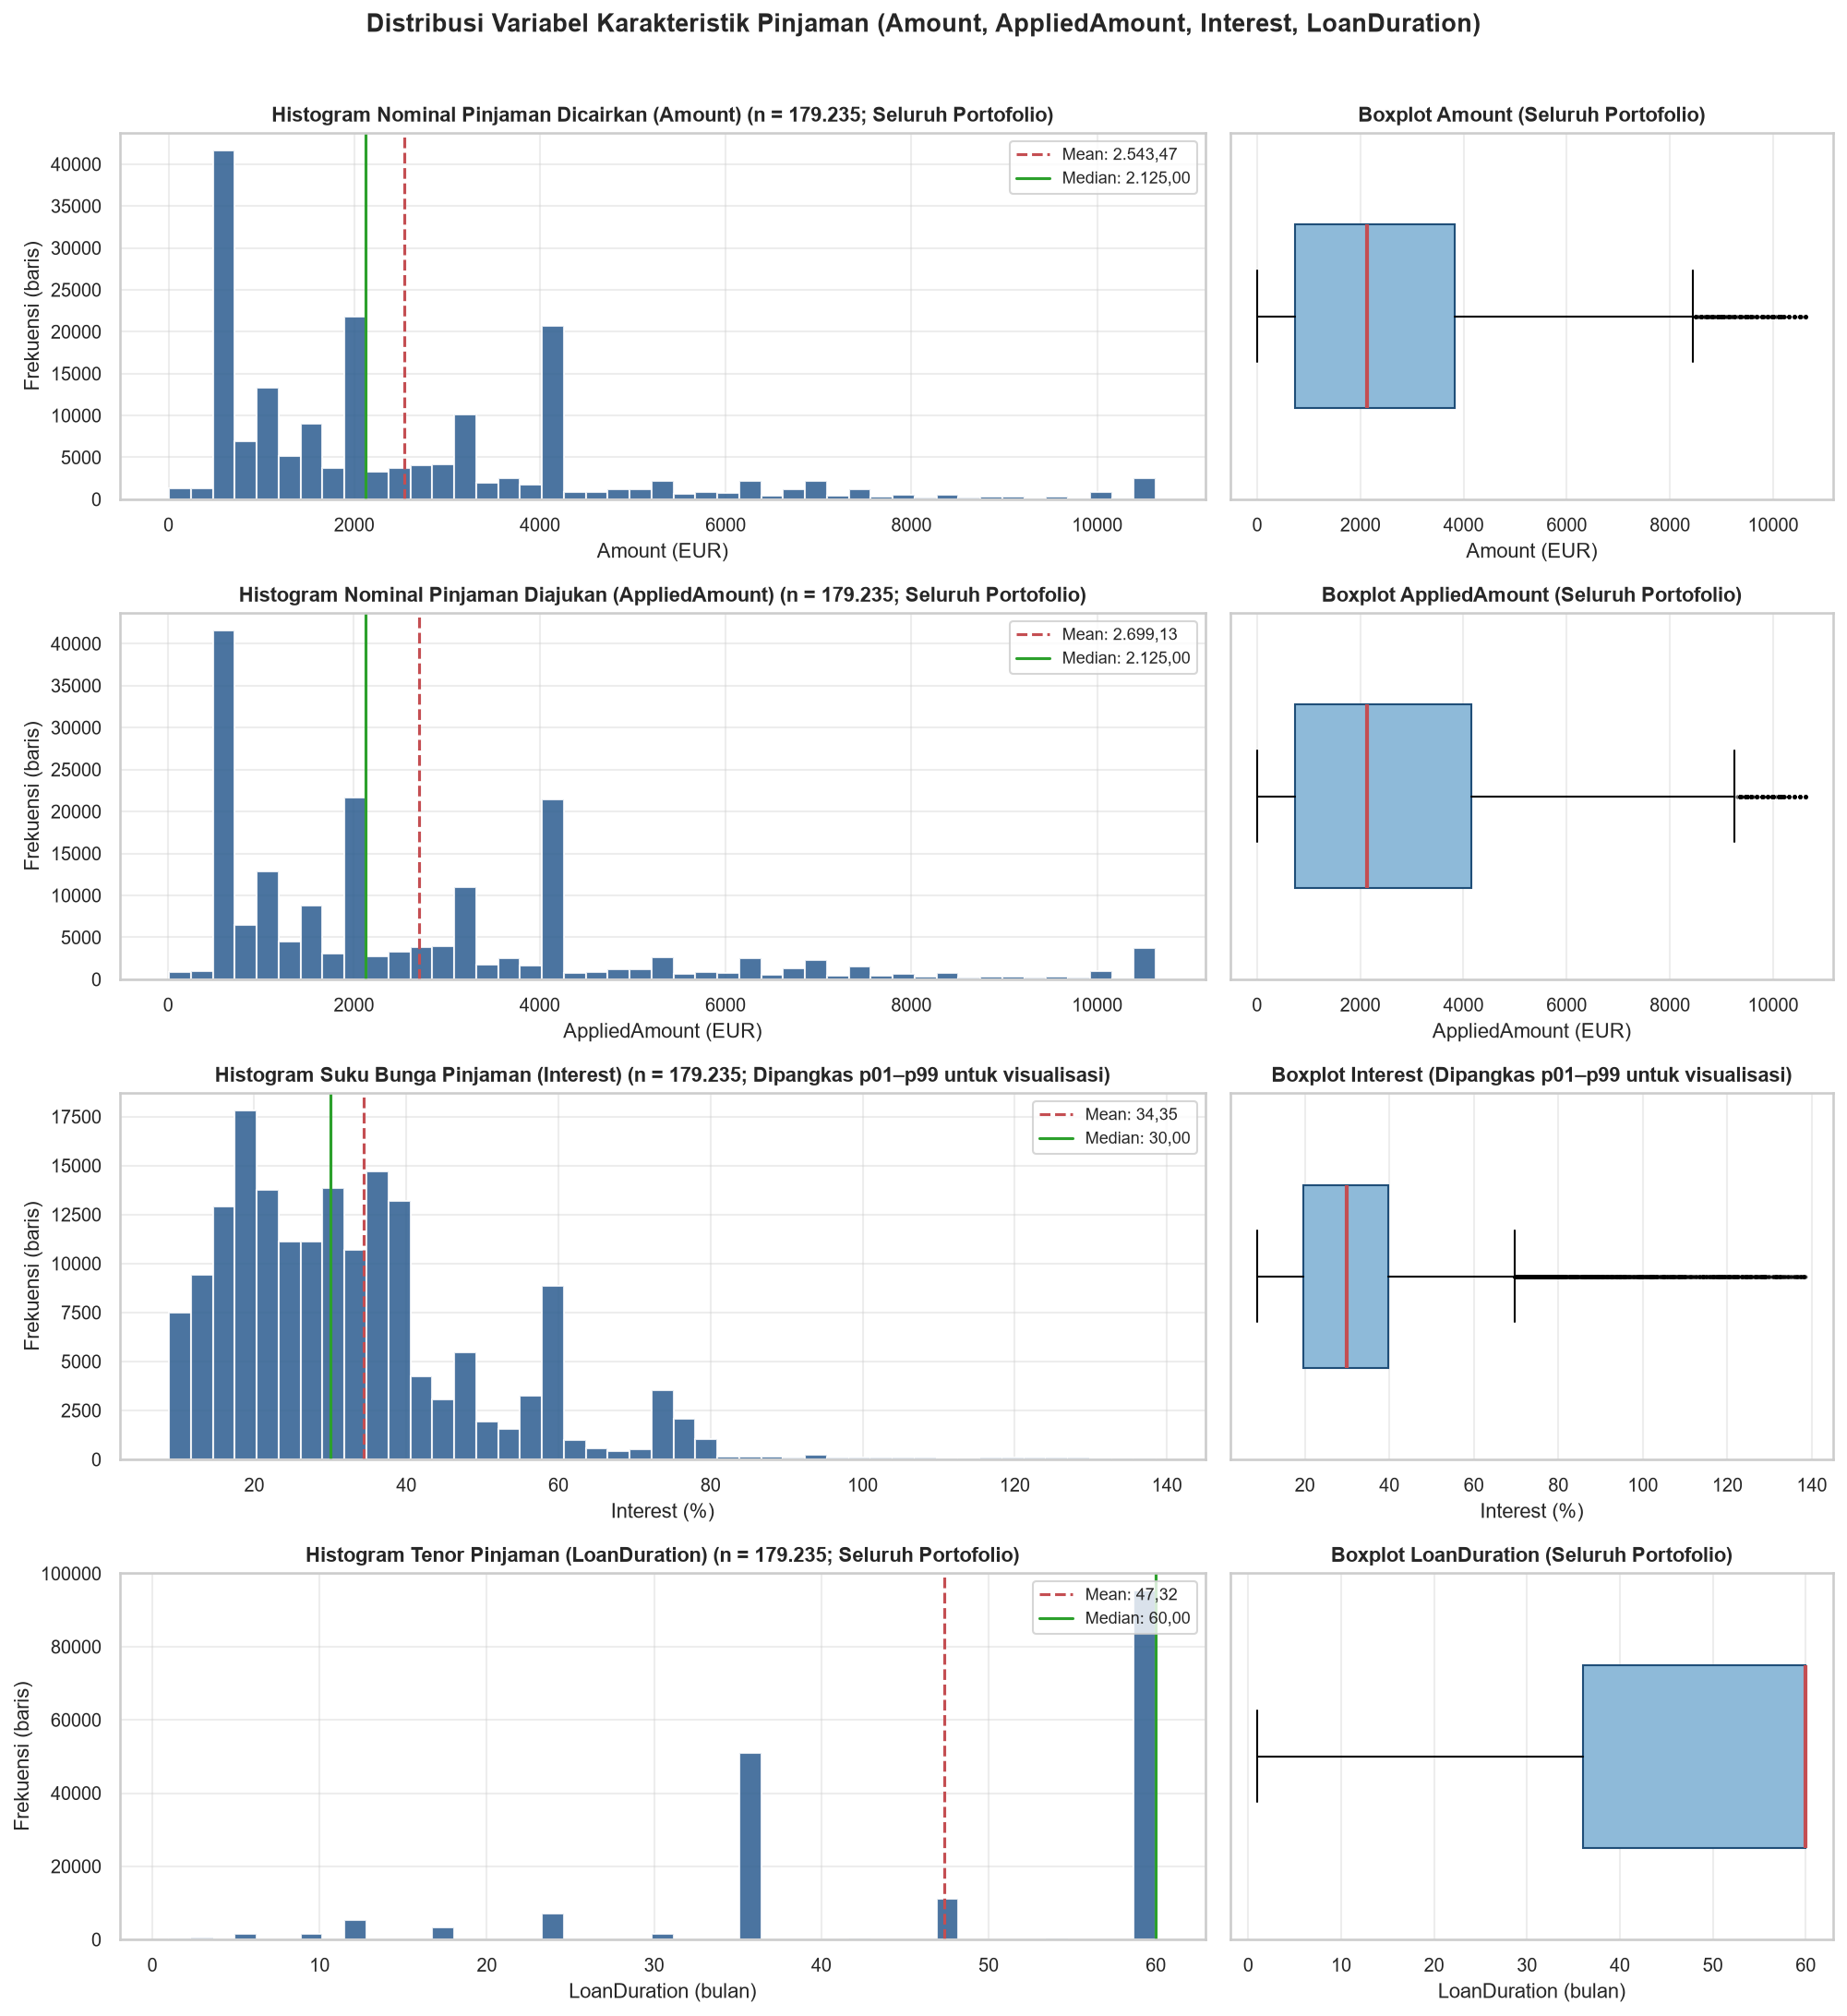

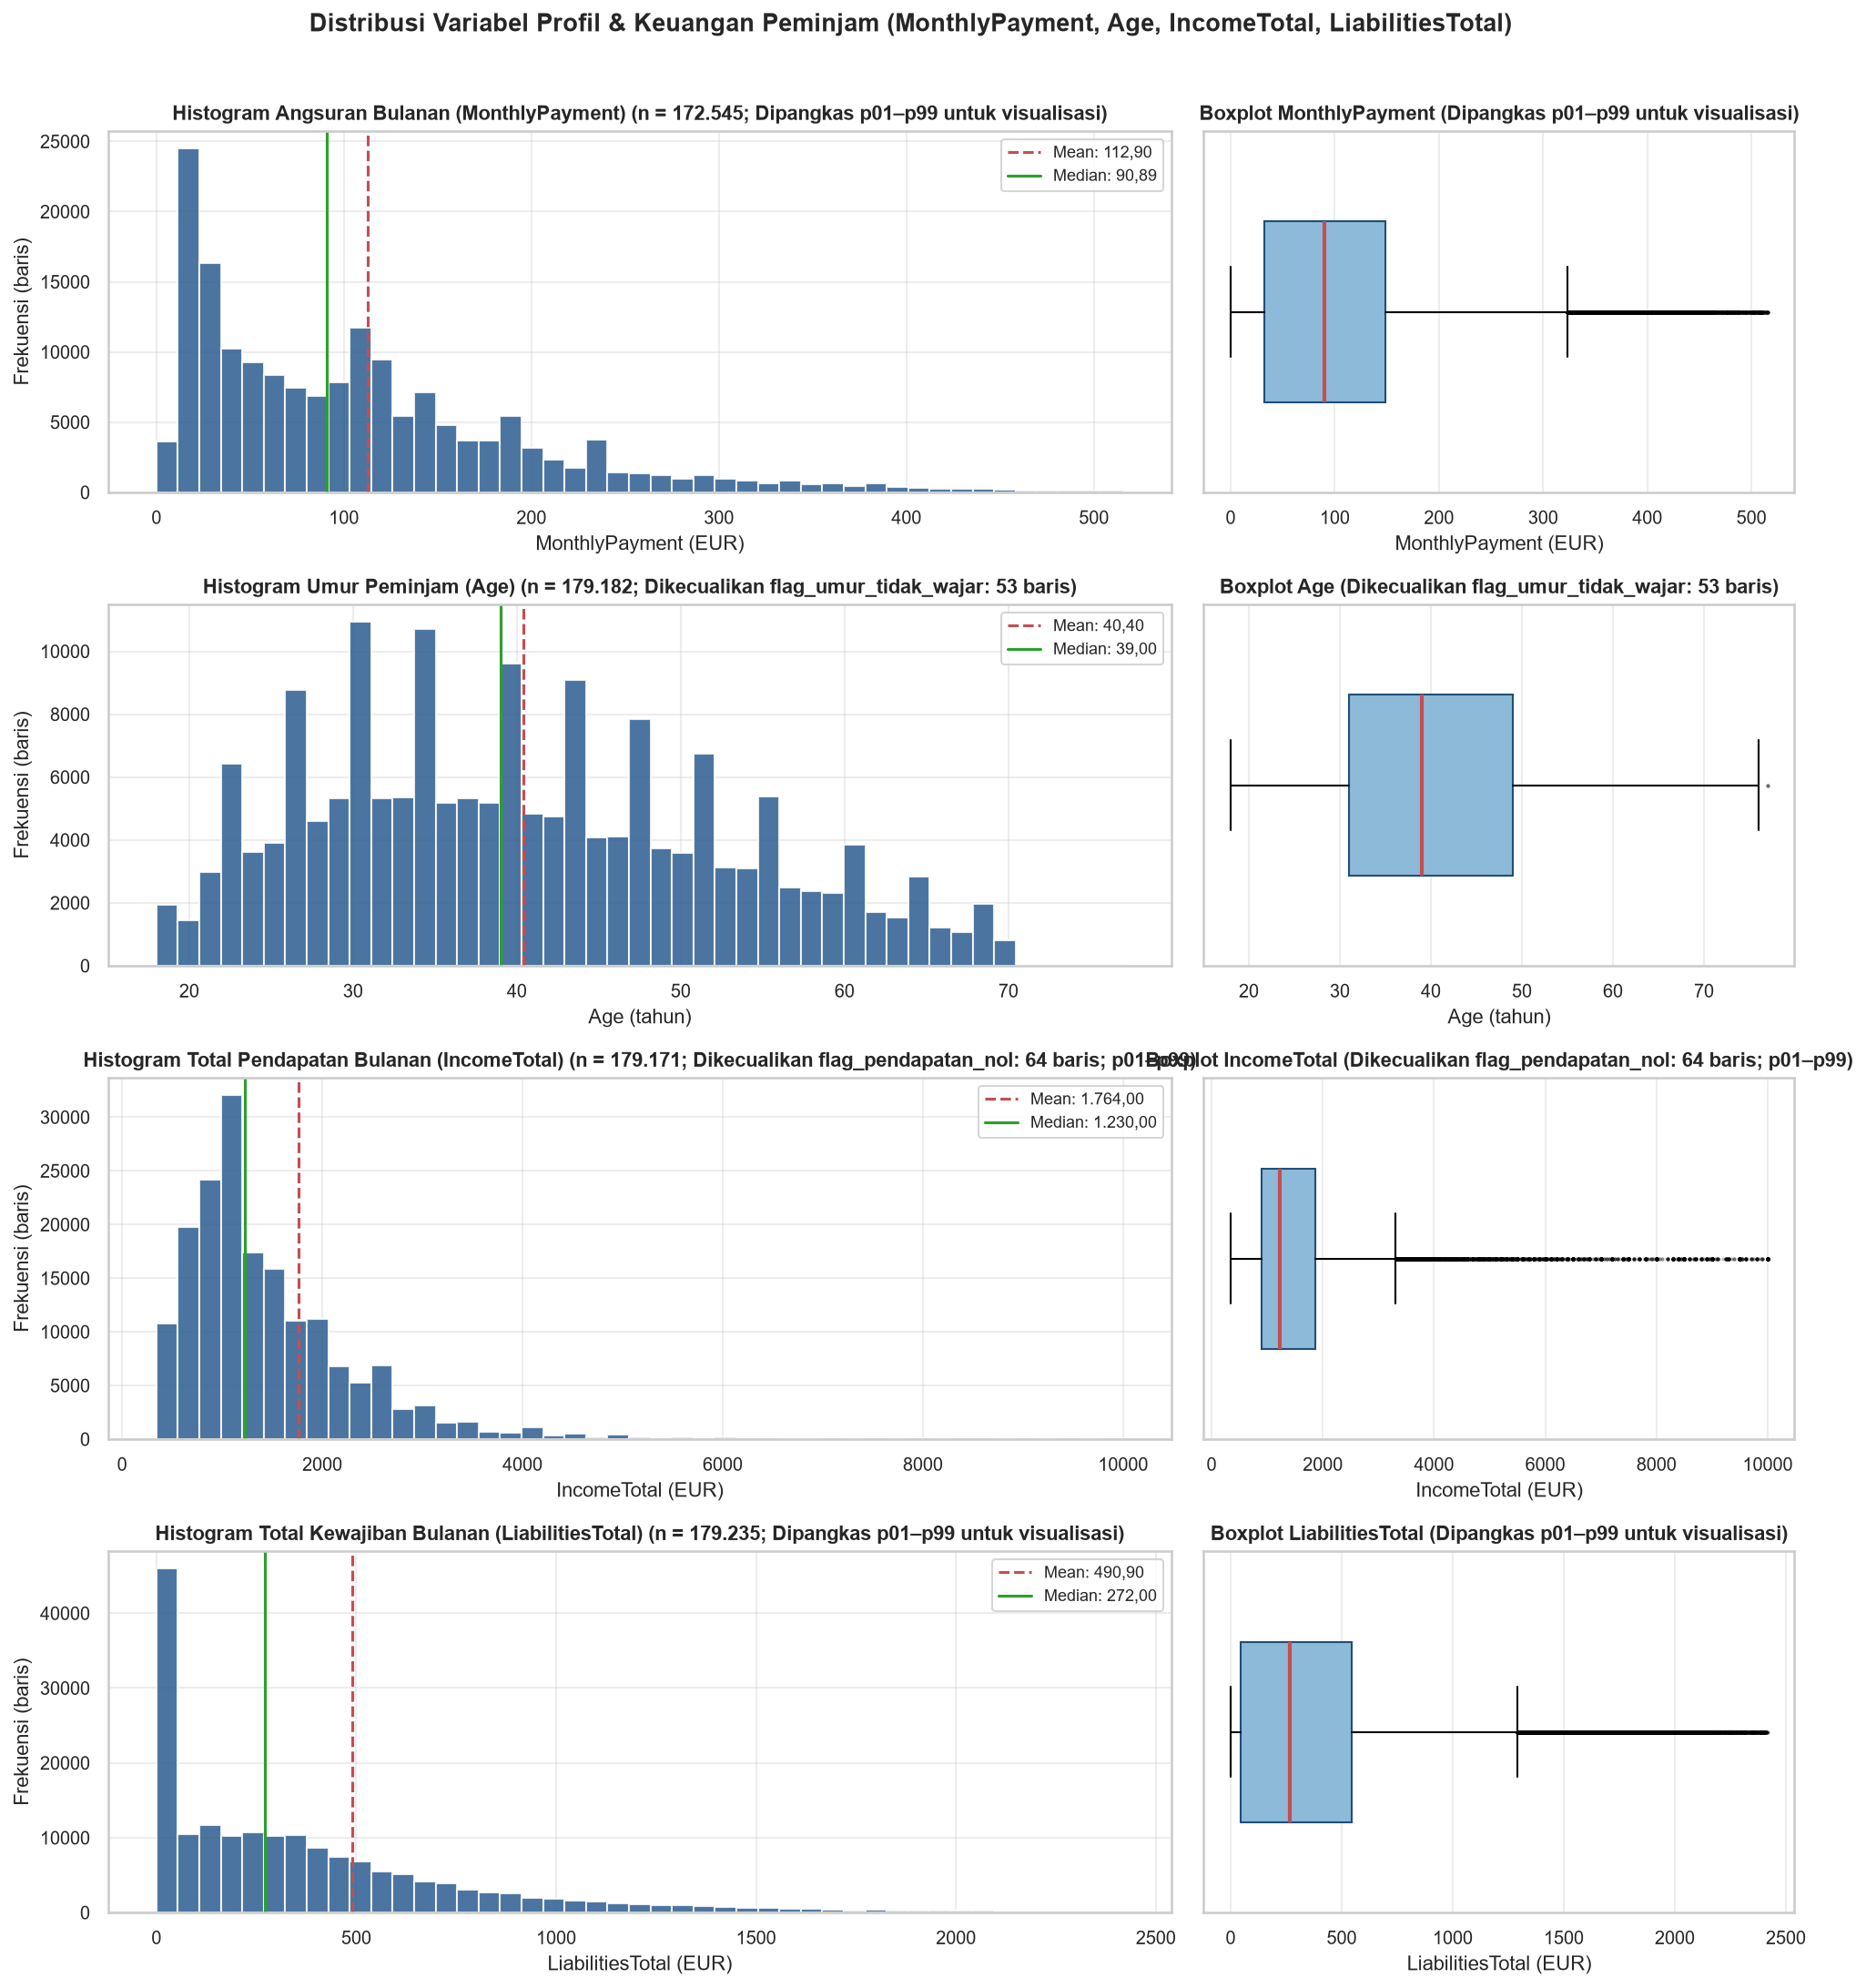

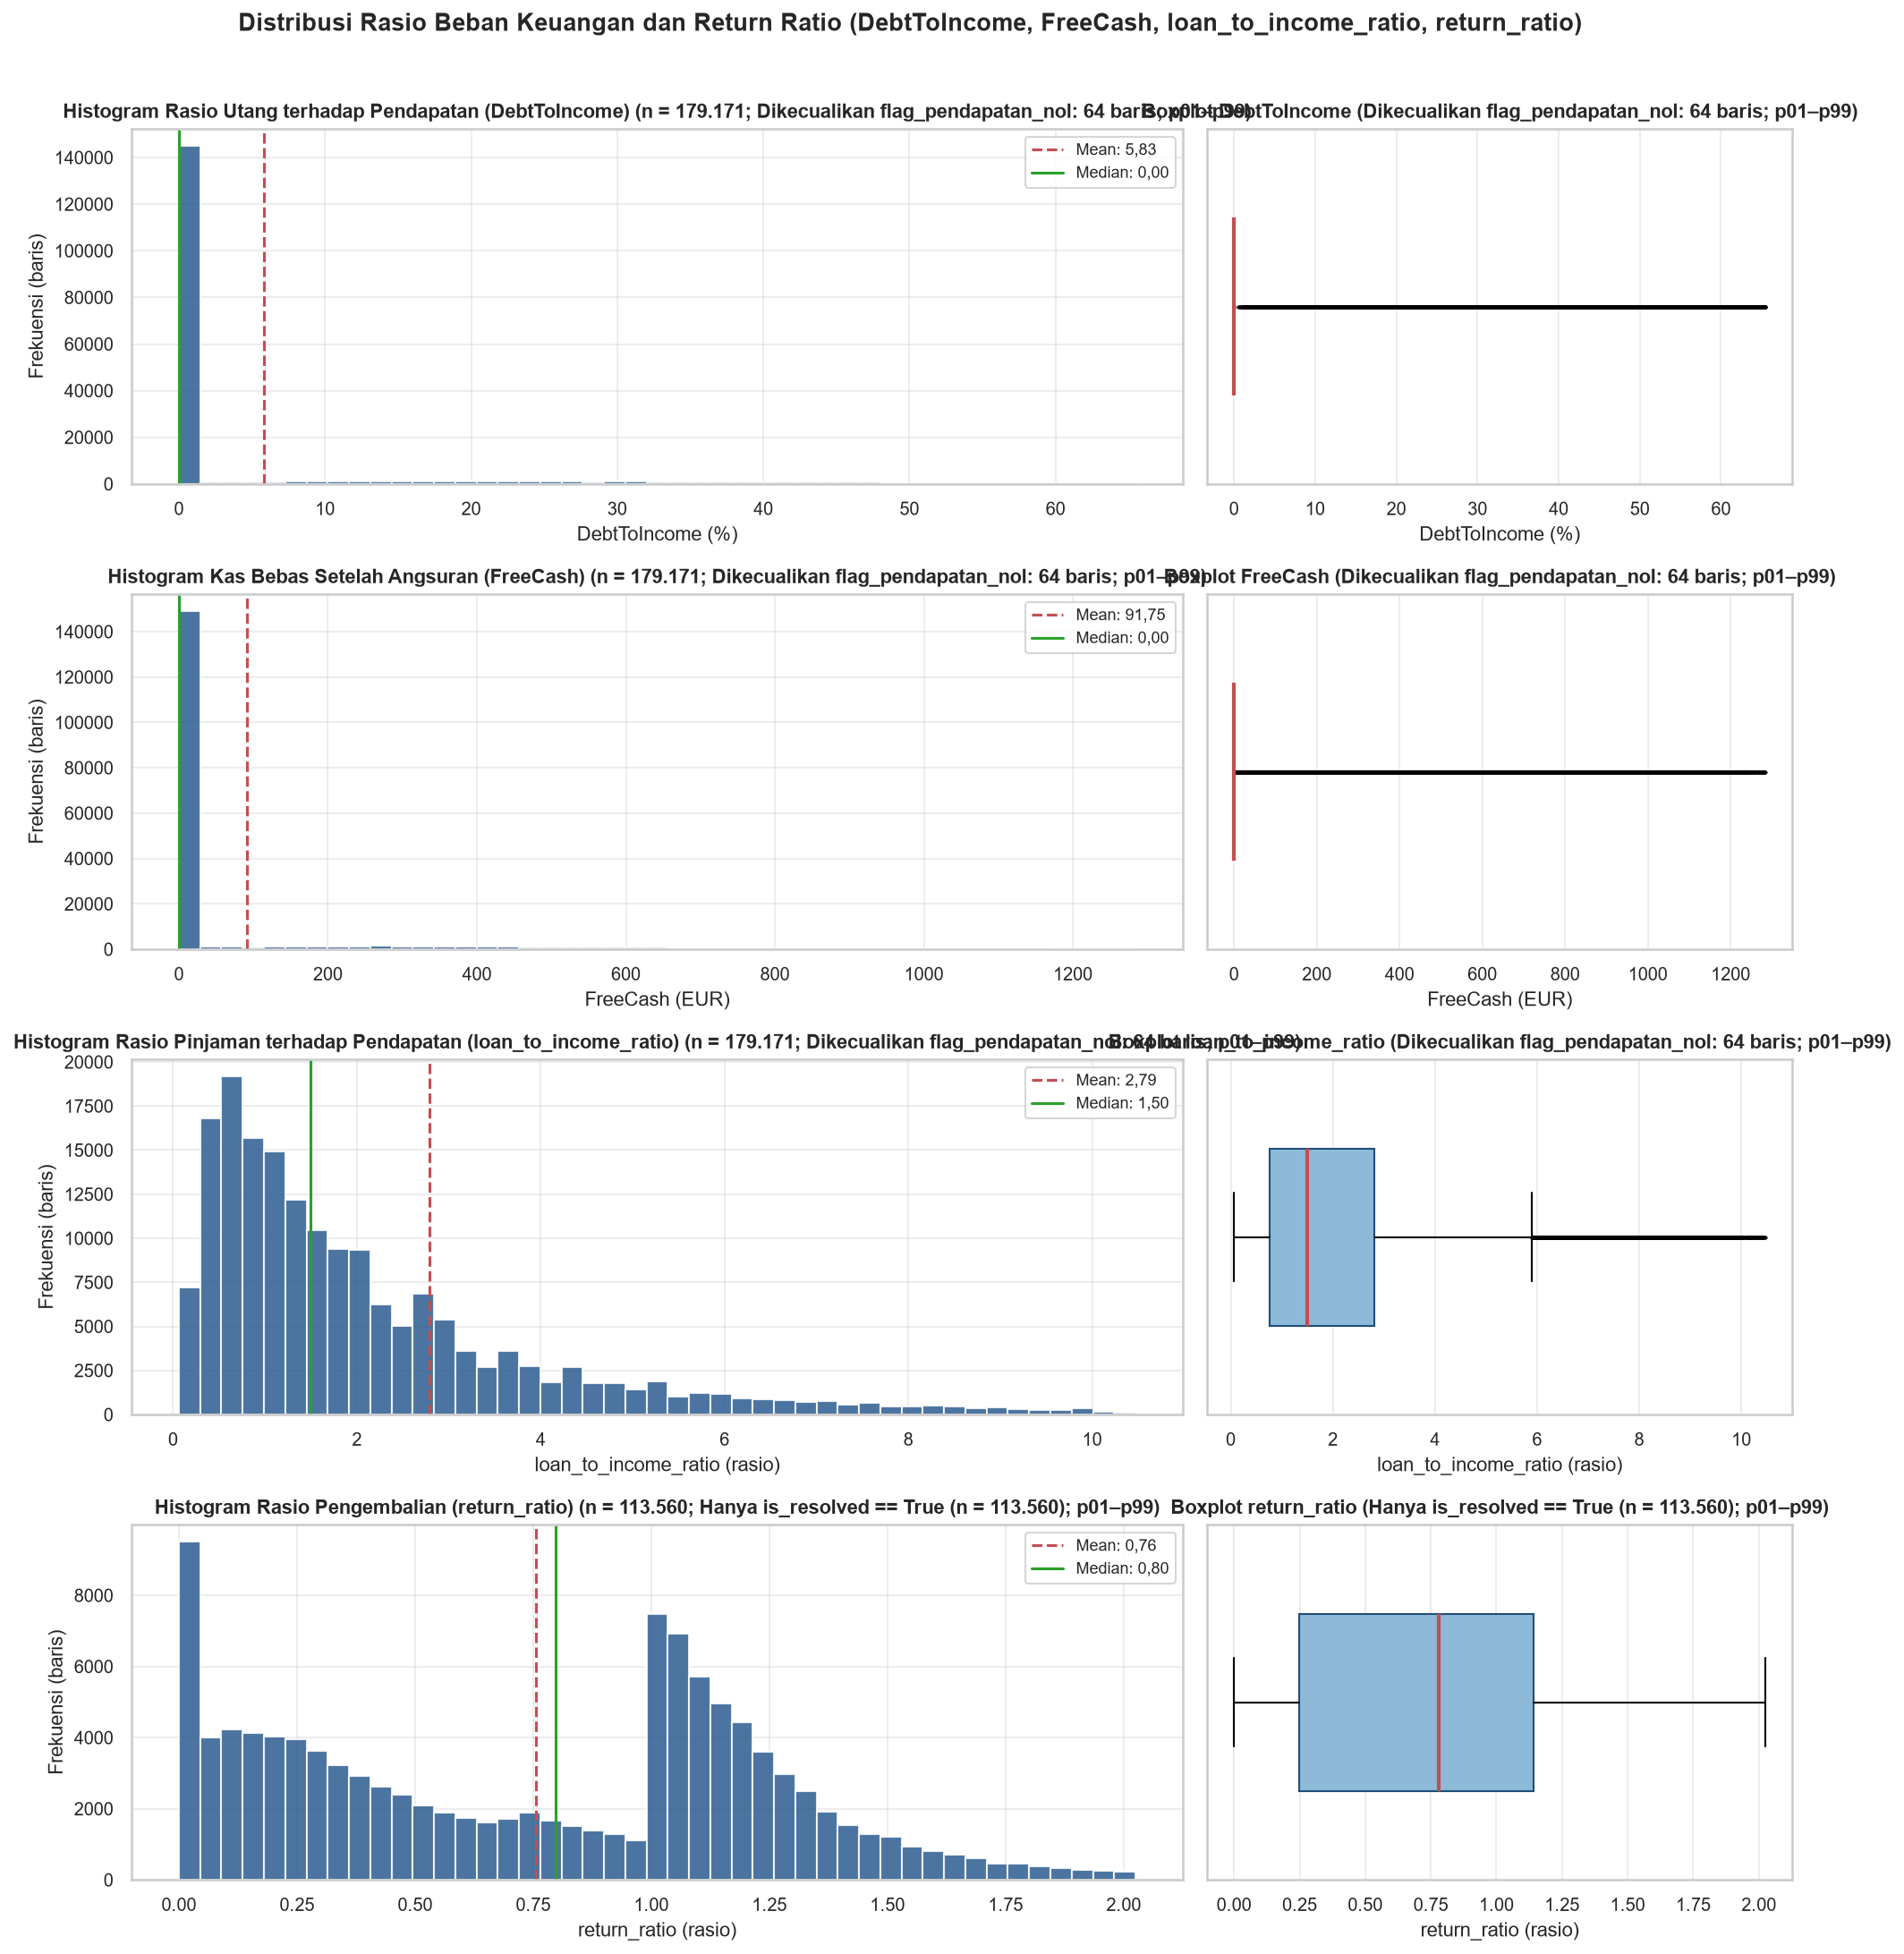

In [5]:
# Visualisasi Histogram + Boxplot Berdampingan untuk 12 Kolom Utama (3 kelompok gambar)
key_num_specs = [
    ('Amount', 'Nominal Pinjaman Dicairkan (Amount)', 'EUR', df['Amount'], False, 'Seluruh Portofolio'),
    ('AppliedAmount', 'Nominal Pinjaman Diajukan (AppliedAmount)', 'EUR', df['AppliedAmount'], False, 'Seluruh Portofolio'),
    ('Interest', 'Suku Bunga Pinjaman (Interest)', '%', df['Interest'], True, 'Dipangkas p01–p99 untuk visualisasi'),
    ('LoanDuration', 'Tenor Pinjaman (LoanDuration)', 'bulan', df['LoanDuration'], False, 'Seluruh Portofolio'),
    ('MonthlyPayment', 'Angsuran Bulanan (MonthlyPayment)', 'EUR', df['MonthlyPayment'], True, 'Dipangkas p01–p99 untuk visualisasi'),
    ('Age', 'Umur Peminjam (Age)', 'tahun', df.loc[df['flag_umur_tidak_wajar'] == False, 'Age'], False, f'Dikecualikan flag_umur_tidak_wajar: {n_bad_age} baris'),
    ('IncomeTotal', 'Total Pendapatan Bulanan (IncomeTotal)', 'EUR', df.loc[df['flag_pendapatan_nol'] == False, 'IncomeTotal'], True, f'Dikecualikan flag_pendapatan_nol: {n_zero_inc} baris; p01–p99'),
    ('LiabilitiesTotal', 'Total Kewajiban Bulanan (LiabilitiesTotal)', 'EUR', df['LiabilitiesTotal'], True, 'Dipangkas p01–p99 untuk visualisasi'),
    ('DebtToIncome', 'Rasio Utang terhadap Pendapatan (DebtToIncome)', '%', df.loc[df['flag_pendapatan_nol'] == False, 'DebtToIncome'], True, f'Dikecualikan flag_pendapatan_nol: {n_zero_inc} baris; p01–p99'),
    ('FreeCash', 'Kas Bebas Setelah Angsuran (FreeCash)', 'EUR', df.loc[df['flag_pendapatan_nol'] == False, 'FreeCash'], True, f'Dikecualikan flag_pendapatan_nol: {n_zero_inc} baris; p01–p99'),
    ('loan_to_income_ratio', 'Rasio Pinjaman terhadap Pendapatan (loan_to_income_ratio)', 'rasio', df.loc[df['flag_pendapatan_nol'] == False, 'loan_to_income_ratio'], True, f'Dikecualikan flag_pendapatan_nol: {n_zero_inc} baris; p01–p99'),
    ('return_ratio', 'Rasio Pengembalian (return_ratio)', 'rasio', df.loc[df['is_resolved'] == True, 'return_ratio'], True, 'Hanya is_resolved == True (n = 113.560); p01–p99'),
]

group_names = [
    ('02_numeric_distributions_pinjaman.png', 'Distribusi Variabel Karakteristik Pinjaman (Amount, AppliedAmount, Interest, LoanDuration)', key_num_specs[0:4]),
    ('02_numeric_distributions_peminjam.png', 'Distribusi Variabel Profil & Keuangan Peminjam (MonthlyPayment, Age, IncomeTotal, LiabilitiesTotal)', key_num_specs[4:8]),
    ('02_numeric_distributions_rasio_return.png', 'Distribusi Rasio Beban Keuangan dan Return Ratio (DebtToIncome, FreeCash, loan_to_income_ratio, return_ratio)', key_num_specs[8:12]),
]

for fname, suptitle_txt, specs in group_names:
    fig, axes = plt.subplots(len(specs), 2, figsize=(13.5, 3.6 * len(specs)), gridspec_kw={'width_ratios': [1.8, 1.0]})
    for idx, (col_name, label_id, unit_str, series_raw, clip_p01_p99, note_str) in enumerate(specs):
        s_val = pd.to_numeric(series_raw, errors='coerce').dropna().astype('float64')
        n_val = len(s_val)
        p01, p50, p99 = s_val.quantile([0.01, 0.50, 0.99])
        mean_v = s_val.mean()
        s_plot = s_val.loc[(s_val >= p01) & (s_val <= p99)] if clip_p01_p99 else s_val

        ax_h, ax_b = axes[idx, 0], axes[idx, 1]
        ax_h.hist(s_plot, bins=45, color='#2b5c8f', edgecolor='white', alpha=0.85)
        ax_h.axvline(mean_v, color='#c44e52', linestyle='--', linewidth=1.5, label=f'Mean: {fmt_id(mean_v, 2)}')
        ax_h.axvline(p50, color='#2ca02c', linestyle='-', linewidth=1.5, label=f'Median: {fmt_id(p50, 2)}')
        ax_h.set_title(f'Histogram {label_id} (n = {fmt_id(n_val, is_int=True)}; {note_str})', fontsize=10.5)
        ax_h.set_xlabel(f'{col_name} ({unit_str})')
        ax_h.set_ylabel('Frekuensi (baris)')
        ax_h.legend(loc='upper right', fontsize=8.5)

        ax_b.boxplot(
            s_plot, orientation='horizontal', widths=0.5, patch_artist=True,
            boxprops={'facecolor': '#8ebad9', 'edgecolor': '#1f4e78'},
            medianprops={'color': '#c44e52', 'linewidth': 2},
            flierprops={'marker': '.', 'markersize': 2, 'alpha': 0.25},
        )
        ax_b.set_title(f'Boxplot {col_name} ({note_str})', fontsize=10.5)
        ax_b.set_xlabel(f'{col_name} ({unit_str})')
        ax_b.set_yticks([])

    fig.suptitle(suptitle_txt, fontsize=13, fontweight='bold', y=1.01)
    fig.tight_layout()
    save_fig(fig, fname, close=False)
    plt.show()
    plt.close(fig)

### Narasi Distribusi 12 Variabel Numerik Utama

1. **`Amount` (`02_numeric_distributions_pinjaman.png`):** Distribusi nominal pinjaman dicairkan (`n = 179.235`) miring ke kanan (*right-skewed*, `skewness = 1,51`) dengan beberapa puncak diskrit pada angka bulat (seperti 530 EUR, 1.060 EUR, 2.125 EUR, dan 4.250 EUR). Nilai tengah tercatat pada median **2.125,00 EUR** (kuartil bawah `p25 = 740,00 EUR`, kuartil atas `p75 = 3.825,00 EUR`) dan rata-rata **2.543,47 EUR**, dengan ekor kanan mencapai `p99 = 10.630,00 EUR` dan maksimum **10.632,00 EUR**.
2. **`AppliedAmount` (`02_numeric_distributions_pinjaman.png`):** Serupa dengan `Amount`, distribusi nominal yang diajukan (`n = 179.235`) miring ke kanan (`skewness = 1,46`) dan memiliki median yang sama yaitu **2.125,00 EUR** (`p25 = 740,00 EUR`, `p75 = 4.150,00 EUR`), tetapi rata-ratanya sedikit lebih tinggi di **2.699,13 EUR**. Ekor kanan pada `p95` mencapai **7.442,00 EUR** dan `p99 = 10.630,00 EUR`.
3. **`Interest` (`02_numeric_distributions_pinjaman.png`):** Suku bunga pinjaman (`n = 179.235`, ditampilkan pada rentang `p01–p99` yakni **8,80%–138,58%**) miring kuat ke kanan (`skewness = 3,63`, `kurtosis = 22,26`). Nilai median berada pada **30,00%** (`p25 = 19,41%`, `p75 = 39,80%`) dan rata-rata **34,35%**, dengan ekor kanan ekstrem mencapai maksimum **264,31%**.
4. **`LoanDuration` (`02_numeric_distributions_pinjaman.png`):** Distribusi tenor pinjaman (`n = 179.235`) bersifat multimodal diskrit dan miring ke kiri (`skewness = -0,88`), terkonsentrasi kuat pada tenor standar **36 bulan** (`p25 = 36,00`) dan terutama **60 bulan** (`p50 = 60,00`, `p75 = 60,00`, `max = 60,00`). Rata-rata tenor adalah **47,32 bulan**, dengan ekor bawah `p05 = 12,00 bulan` dan `p01 = 6,00 bulan`.
5. **`MonthlyPayment` (`02_numeric_distributions_peminjam.png`):** Angsuran bulanan (`n = 172.545`, kosong `6.690` baris atau `3,73%`; ditampilkan pada `p01–p99` yaitu **0,00–515,58 EUR**) miring ke kanan (`skewness = 2,80`, `kurtosis = 18,03`). Nilai median tercatat **90,89 EUR** (`p25 = 32,85 EUR`, `p75 = 151,77 EUR`) dan rata-rata **112,90 EUR**, sedangkan ekor kanan mencapai `p95 = 309,08 EUR` dan maksimum **2.368,54 EUR**.
6. **`Age` (`02_numeric_distributions_peminjam.png`):** Setelah mengecualikan **53 baris** `flag_umur_tidak_wajar` (`n = 179.182`), distribusi umur peminjam berbentuk unimodal dan sedikit miring ke kanan (`skewness = 0,36`). Nilai tengah berada pada median **39,00 tahun** (`p25 = 31,00 tahun`, `p75 = 49,00 tahun`) dan rata-rata **40,40 tahun**, dengan rentang `p01 = 19,00 tahun` hingga `p99 = 68,00 tahun` (`max = 77,00 tahun`).
7. **`IncomeTotal` (`02_numeric_distributions_peminjam.png`):** Setelah mengecualikan **64 baris** `flag_pendapatan_nol` (`n = 179.171`, ditampilkan pada `p01–p99` yaitu **340,00–10.000,00 EUR**), distribusi pendapatan bulanan sangat miring ke kanan (`skewness = 81,08`, `kurtosis = 7.895,35`) akibat segelintir pencilan ekstrem hingga **1.012.019,00 EUR**. Mayoritas peminjam berada di sekitar median **1.230,00 EUR** (`p25 = 874,60 EUR`, `p75 = 1.900,00 EUR`), lebih rendah dari rata-rata **1.764,00 EUR**.
8. **`LiabilitiesTotal` (`02_numeric_distributions_peminjam.png`):** Total kewajiban bulanan (`n = 179.235`, ditampilkan pada `p01–p99` yaitu **0,00–2.418,71 EUR**) memiliki kemiringan ekstrem (`skewness = 421,81`) karena adanya nilai maksimum **12.400.000,00 EUR**. Nilai tengah berada pada median **272,00 EUR** (`p25 = 49,13 EUR`, `p75 = 555,00 EUR`) dan rata-rata **490,90 EUR**.
9. **`DebtToIncome` (`02_numeric_distributions_rasio_return.png`):** Setelah mengecualikan **64 baris** `flag_pendapatan_nol` (`n = 179.135` non-missing), distribusi `DebtToIncome` memiliki konsentrasi besar pada nilai **0,00%** (`p25 = 0,00%`, `p50 = 0,00%`, `p75 = 0,00%`) karena perubahan pencatatan pada era terbaru. Rata-ratanya tercatat **5,83%** dengan ekor kanan `p95 = 42,79%`, `p99 = 65,47%`, dan maksimum **198,02%**.
10. **`FreeCash` (`02_numeric_distributions_rasio_return.png`):** Serupa dengan `DebtToIncome`, variabel `FreeCash` (`n = 179.135` setelah mengecualikan `flag_pendapatan_nol`) terpusat di **0,00 EUR** (`p25 = 0,00`, `p50 = 0,00`, `p75 = 0,00`) dengan rata-rata **91,77 EUR**. Ekor bawah mencapai **-2.332,00 EUR** dan ekor kanan `p95 = 632,00 EUR`, `p99 = 1.284,00 EUR` (`max = 158.748,64 EUR`).
11. **`loan_to_income_ratio` (`02_numeric_distributions_rasio_return.png`):** Rasio nominal pinjaman terhadap pendapatan bulanan (`n = 179.171`, `64` baris `flag_pendapatan_nol` otomatis bernilai `NaN`; ditampilkan pada `p01–p99` yaitu **0,06–10,47**) miring ke kanan (`skewness = 281,07`). Nilai median tercatat **1,50 kali pendapatan bulanan** (`p25 = 0,76`, `p75 = 2,83`) dan rata-rata **2,79**, dengan `p95 = 6,65`.
12. **`return_ratio` (`02_numeric_distributions_rasio_return.png`):** Pada populasi pinjaman selesai (`is_resolved == True`, `n = 113.560`, ditampilkan pada `p01–p99` yaitu **0,00–2,025**), distribusi bersifat bimodal: satu puncak di dekat `0,00–0,35` (pinjaman default) dan puncak kedua di atas `1,00` (pinjaman lunas beserta bunga). Nilai median tercatat **0,7974** (`p25 = 0,2533`, `p75 = 1,1477`), rata-rata **0,7562**, dan ekor kanan mencapai `p95 = 1,5711` serta maksimum **7,4111**.

## Bagian C — Distribusi Variabel Kategorikal (`02_categorical_frequency.csv`)

Tabel frekuensi untuk 12 variabel kategorikal utama digabungkan ke `reports/tables/02_categorical_frequency.csv`. Kode `-1` dipisahkan secara eksplisit sebagai `-1 (Not set)`, sedangkan kode numerik lainnya dipertahankan apa adanya dengan penanda `TODO: label resmi menunggu pengguna`.

In [6]:
cat_cols = [
    'Country', 'Gender', 'Education', 'MaritalStatus', 'EmploymentStatus',
    'OccupationArea', 'UseOfLoan', 'HomeOwnershipType', 'VerificationType',
    'NewCreditCustomer', 'LanguageCode', 'Rating',
]

cat_tables = []
for c_col in cat_cols:
    ft = freq_table(df, c_col, dropna=False)
    def _format_cat_val(v: str) -> str:
        v_str = str(v).strip()
        if v_str in {'-1', '-1.0'}:
            return '-1 (Not set)'
        if v_str.endswith('.0') and v_str[:-2].lstrip('-').isdigit():
            v_str = v_str[:-2]
        return v_str
    ft['nilai'] = ft['nilai'].map(_format_cat_val)
    cat_tables.append(ft[['variabel', 'nilai', 'jumlah', 'persen']])

cat_freq_df = pd.concat(cat_tables, ignore_index=True)
cat_freq_df.to_csv(TABLES_DIR / '02_categorical_frequency.csv', index=False)
print(f'Saved 02_categorical_frequency.csv: {len(cat_freq_df)} baris dari {len(cat_cols)} variabel')
display(cat_freq_df.head(35))

Saved 02_categorical_frequency.csv: 114 baris dari 12 variabel


,variabel,nilai,jumlah,persen
0,Country,EE,110714,61.770302
1,Country,FI,41955,23.407817
2,Country,ES,26270,14.656736
3,Country,SK,296,0.165146
4,Gender,0,107724,60.102101
5,Gender,1,59286,33.077245
6,Gender,2,12180,6.795548
7,Gender,(Missing),45,0.025107
8,Education,4,67186,37.484866
9,Education,5,43626,24.340112


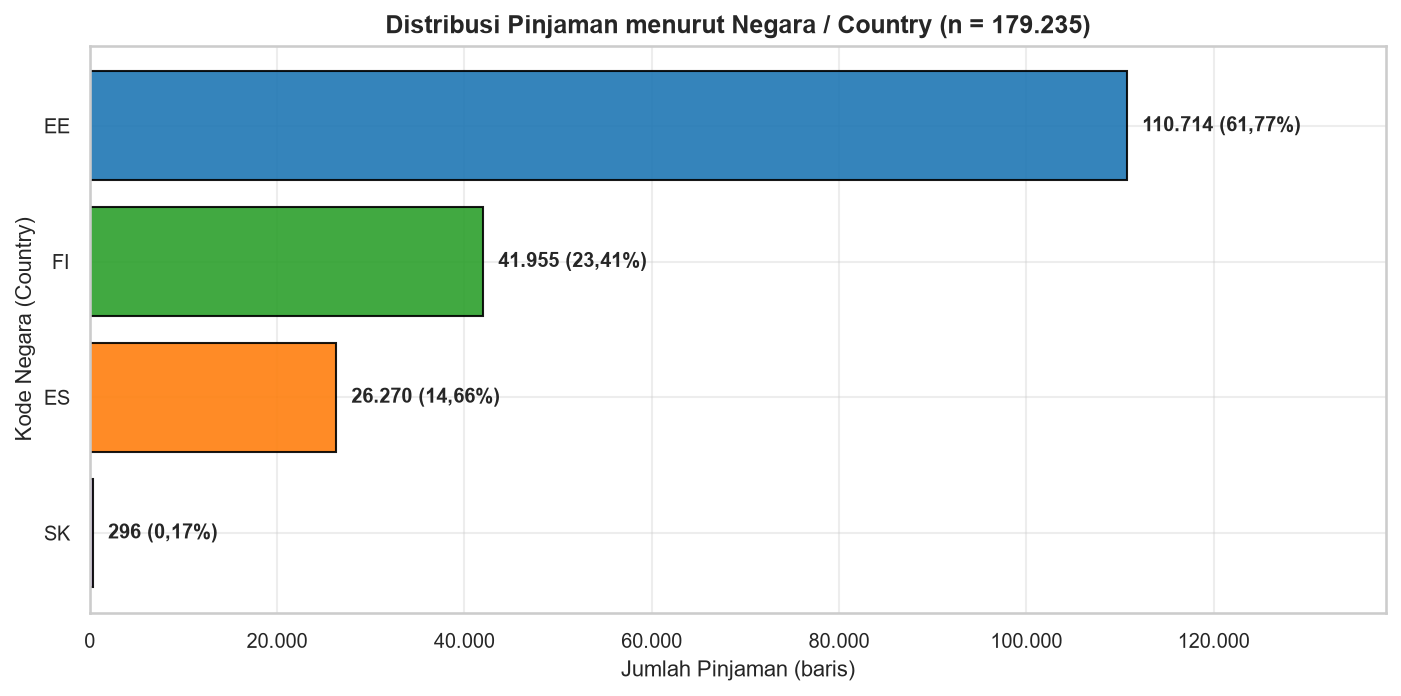

In [7]:
# Grafik Tersendiri: Country (EE, FI, ES, SK) -> reports/figures/02_country_distribution.png
ft_country = cat_freq_df.loc[cat_freq_df['variabel'] == 'Country'].copy()
fig, ax = plt.subplots(figsize=(9.5, 4.8))
bars = ax.barh(
    ft_country['nilai'][::-1], ft_country['jumlah'][::-1],
    color=['#1f77b4', '#2ca02c', '#ff7f0e', '#9467bd'][:len(ft_country)][::-1],
    edgecolor='black', alpha=0.9,
)
ax.set_title(f'Distribusi Pinjaman menurut Negara / Country (n = {fmt_id(n_total, is_int=True)})')
ax.set_xlabel('Jumlah Pinjaman (baris)')
ax.set_ylabel('Kode Negara (Country)')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: fmt_id(x, is_int=True)))
ax.set_xlim(0, ft_country['jumlah'].max() * 1.25)
for bar, jml, pct in zip(bars, ft_country['jumlah'][::-1], ft_country['persen'][::-1]):
    ax.text(bar.get_width() + ft_country['jumlah'].max() * 0.015, bar.get_y() + bar.get_height() / 2, f'{fmt_id(jml, is_int=True)} ({fmt_id(pct, 2)}%)', va='center', fontsize=9.5, fontweight='bold')
fig.tight_layout()
save_fig(fig, '02_country_distribution.png', close=False)
plt.show()
plt.close(fig)

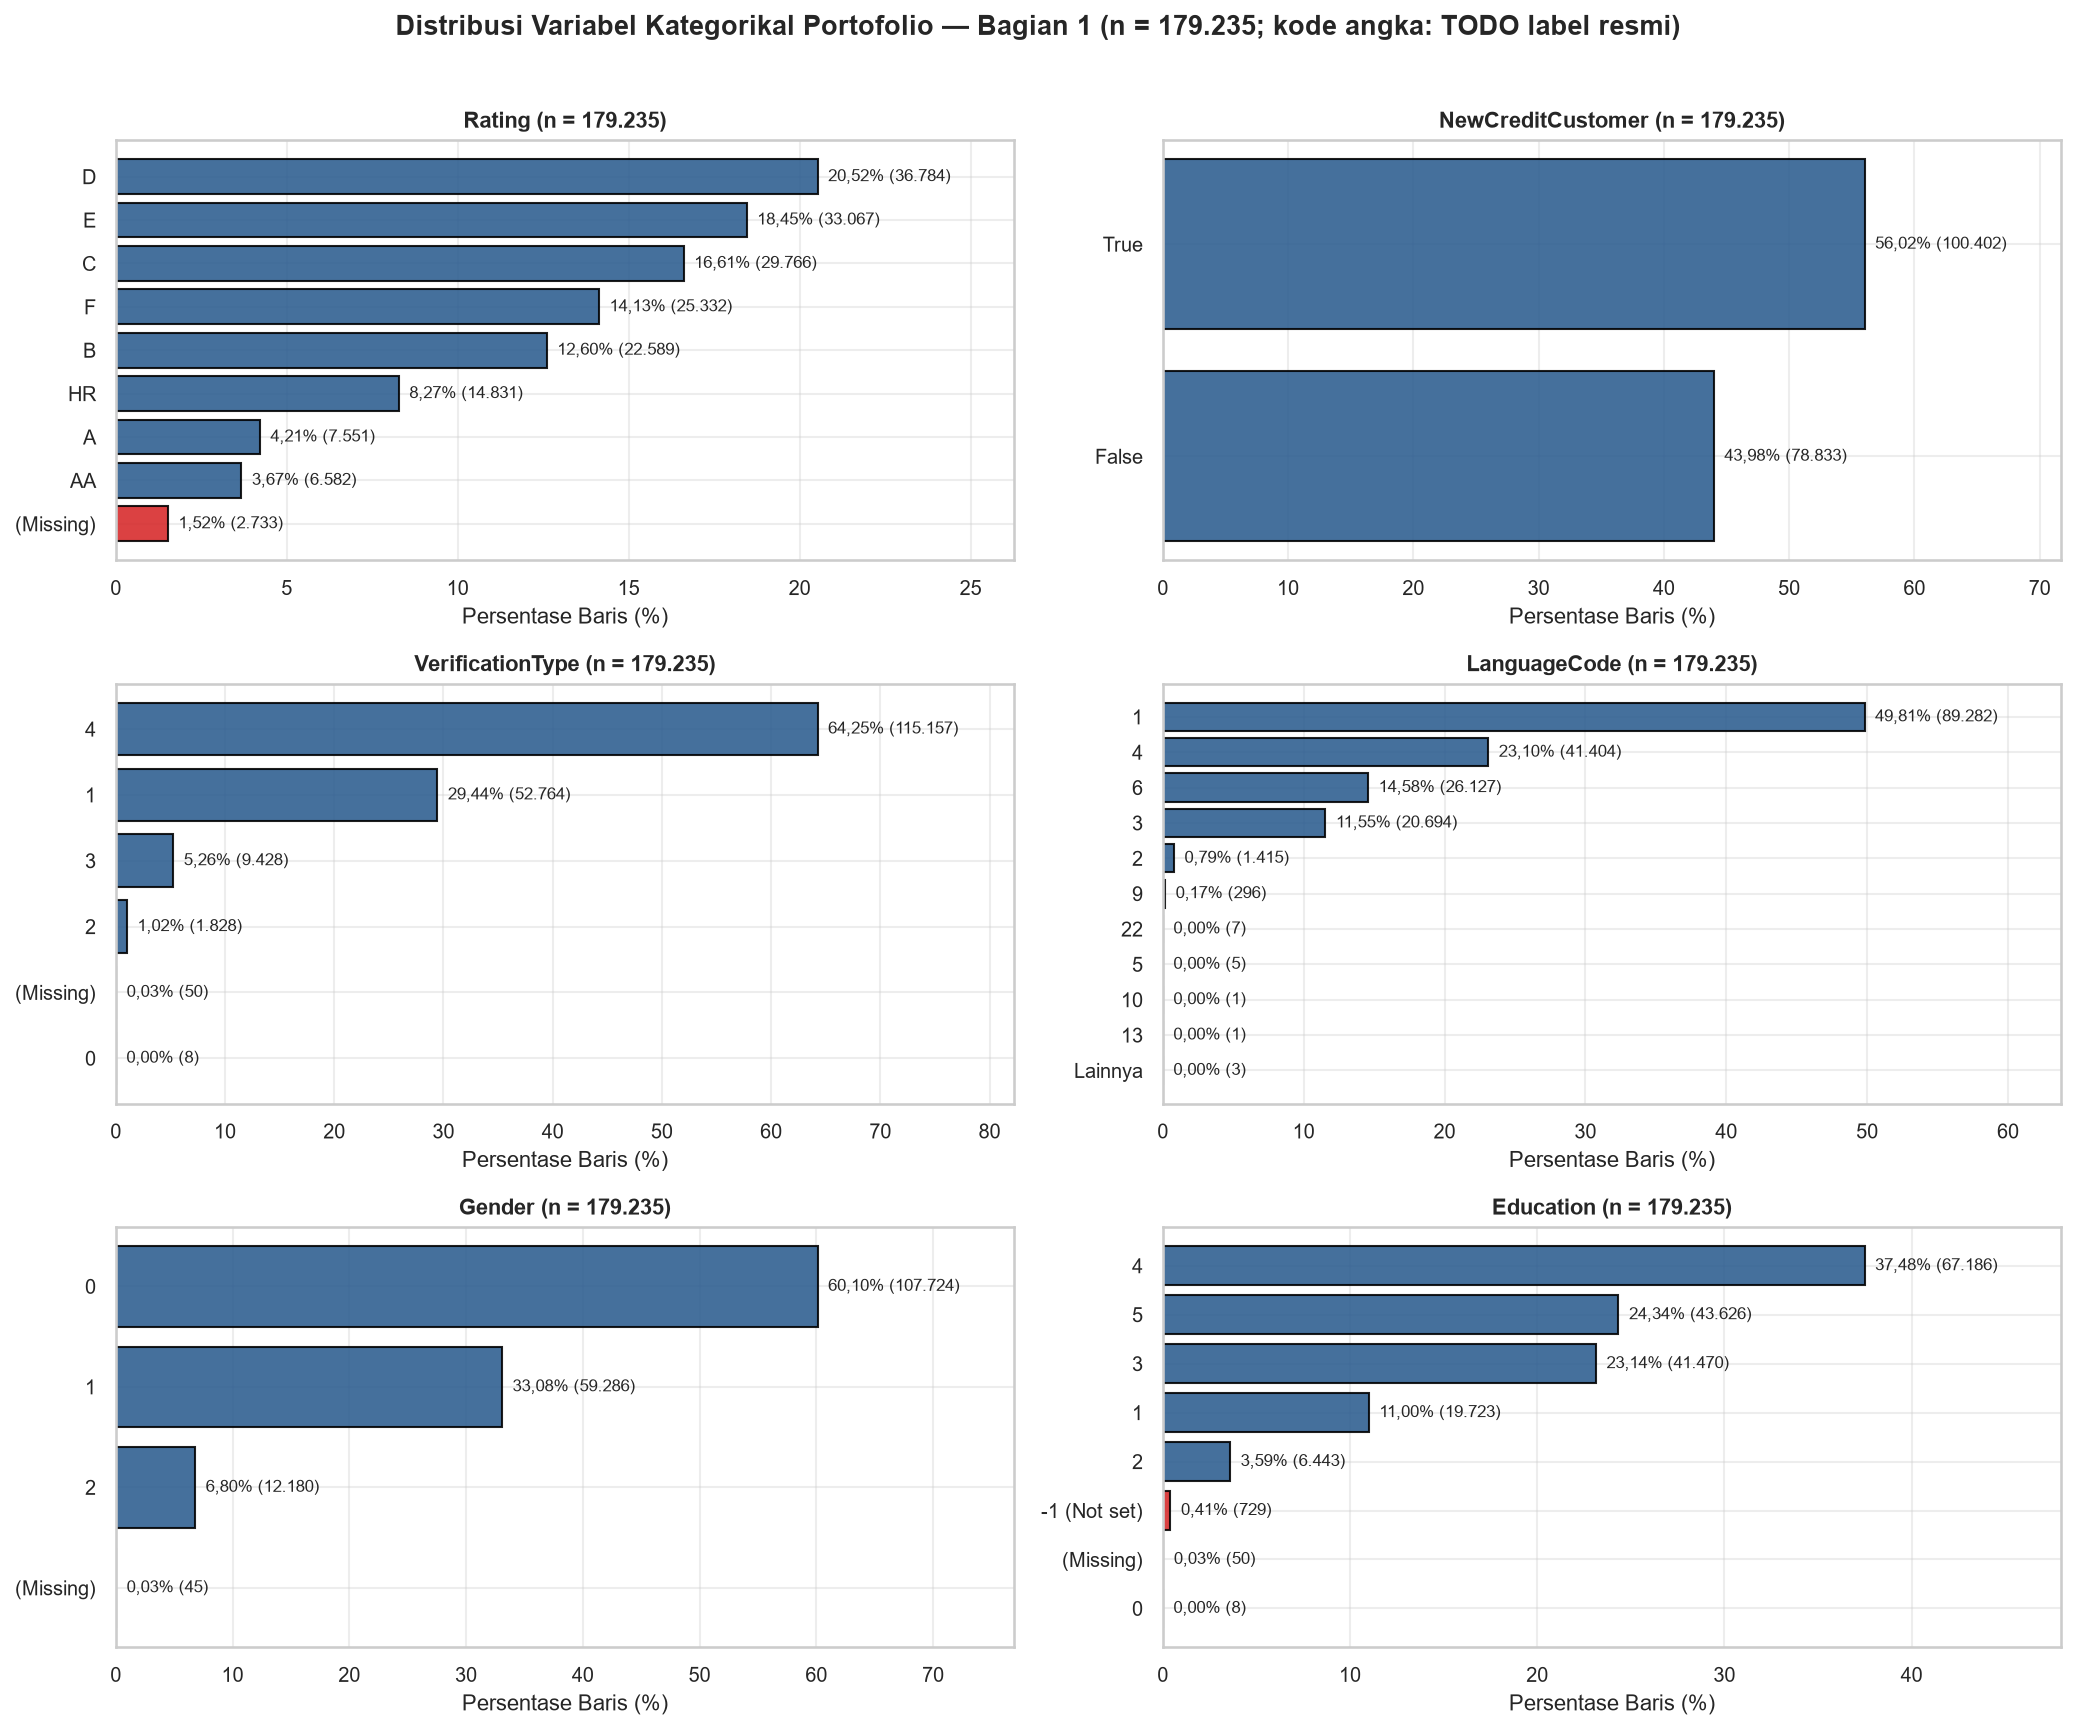

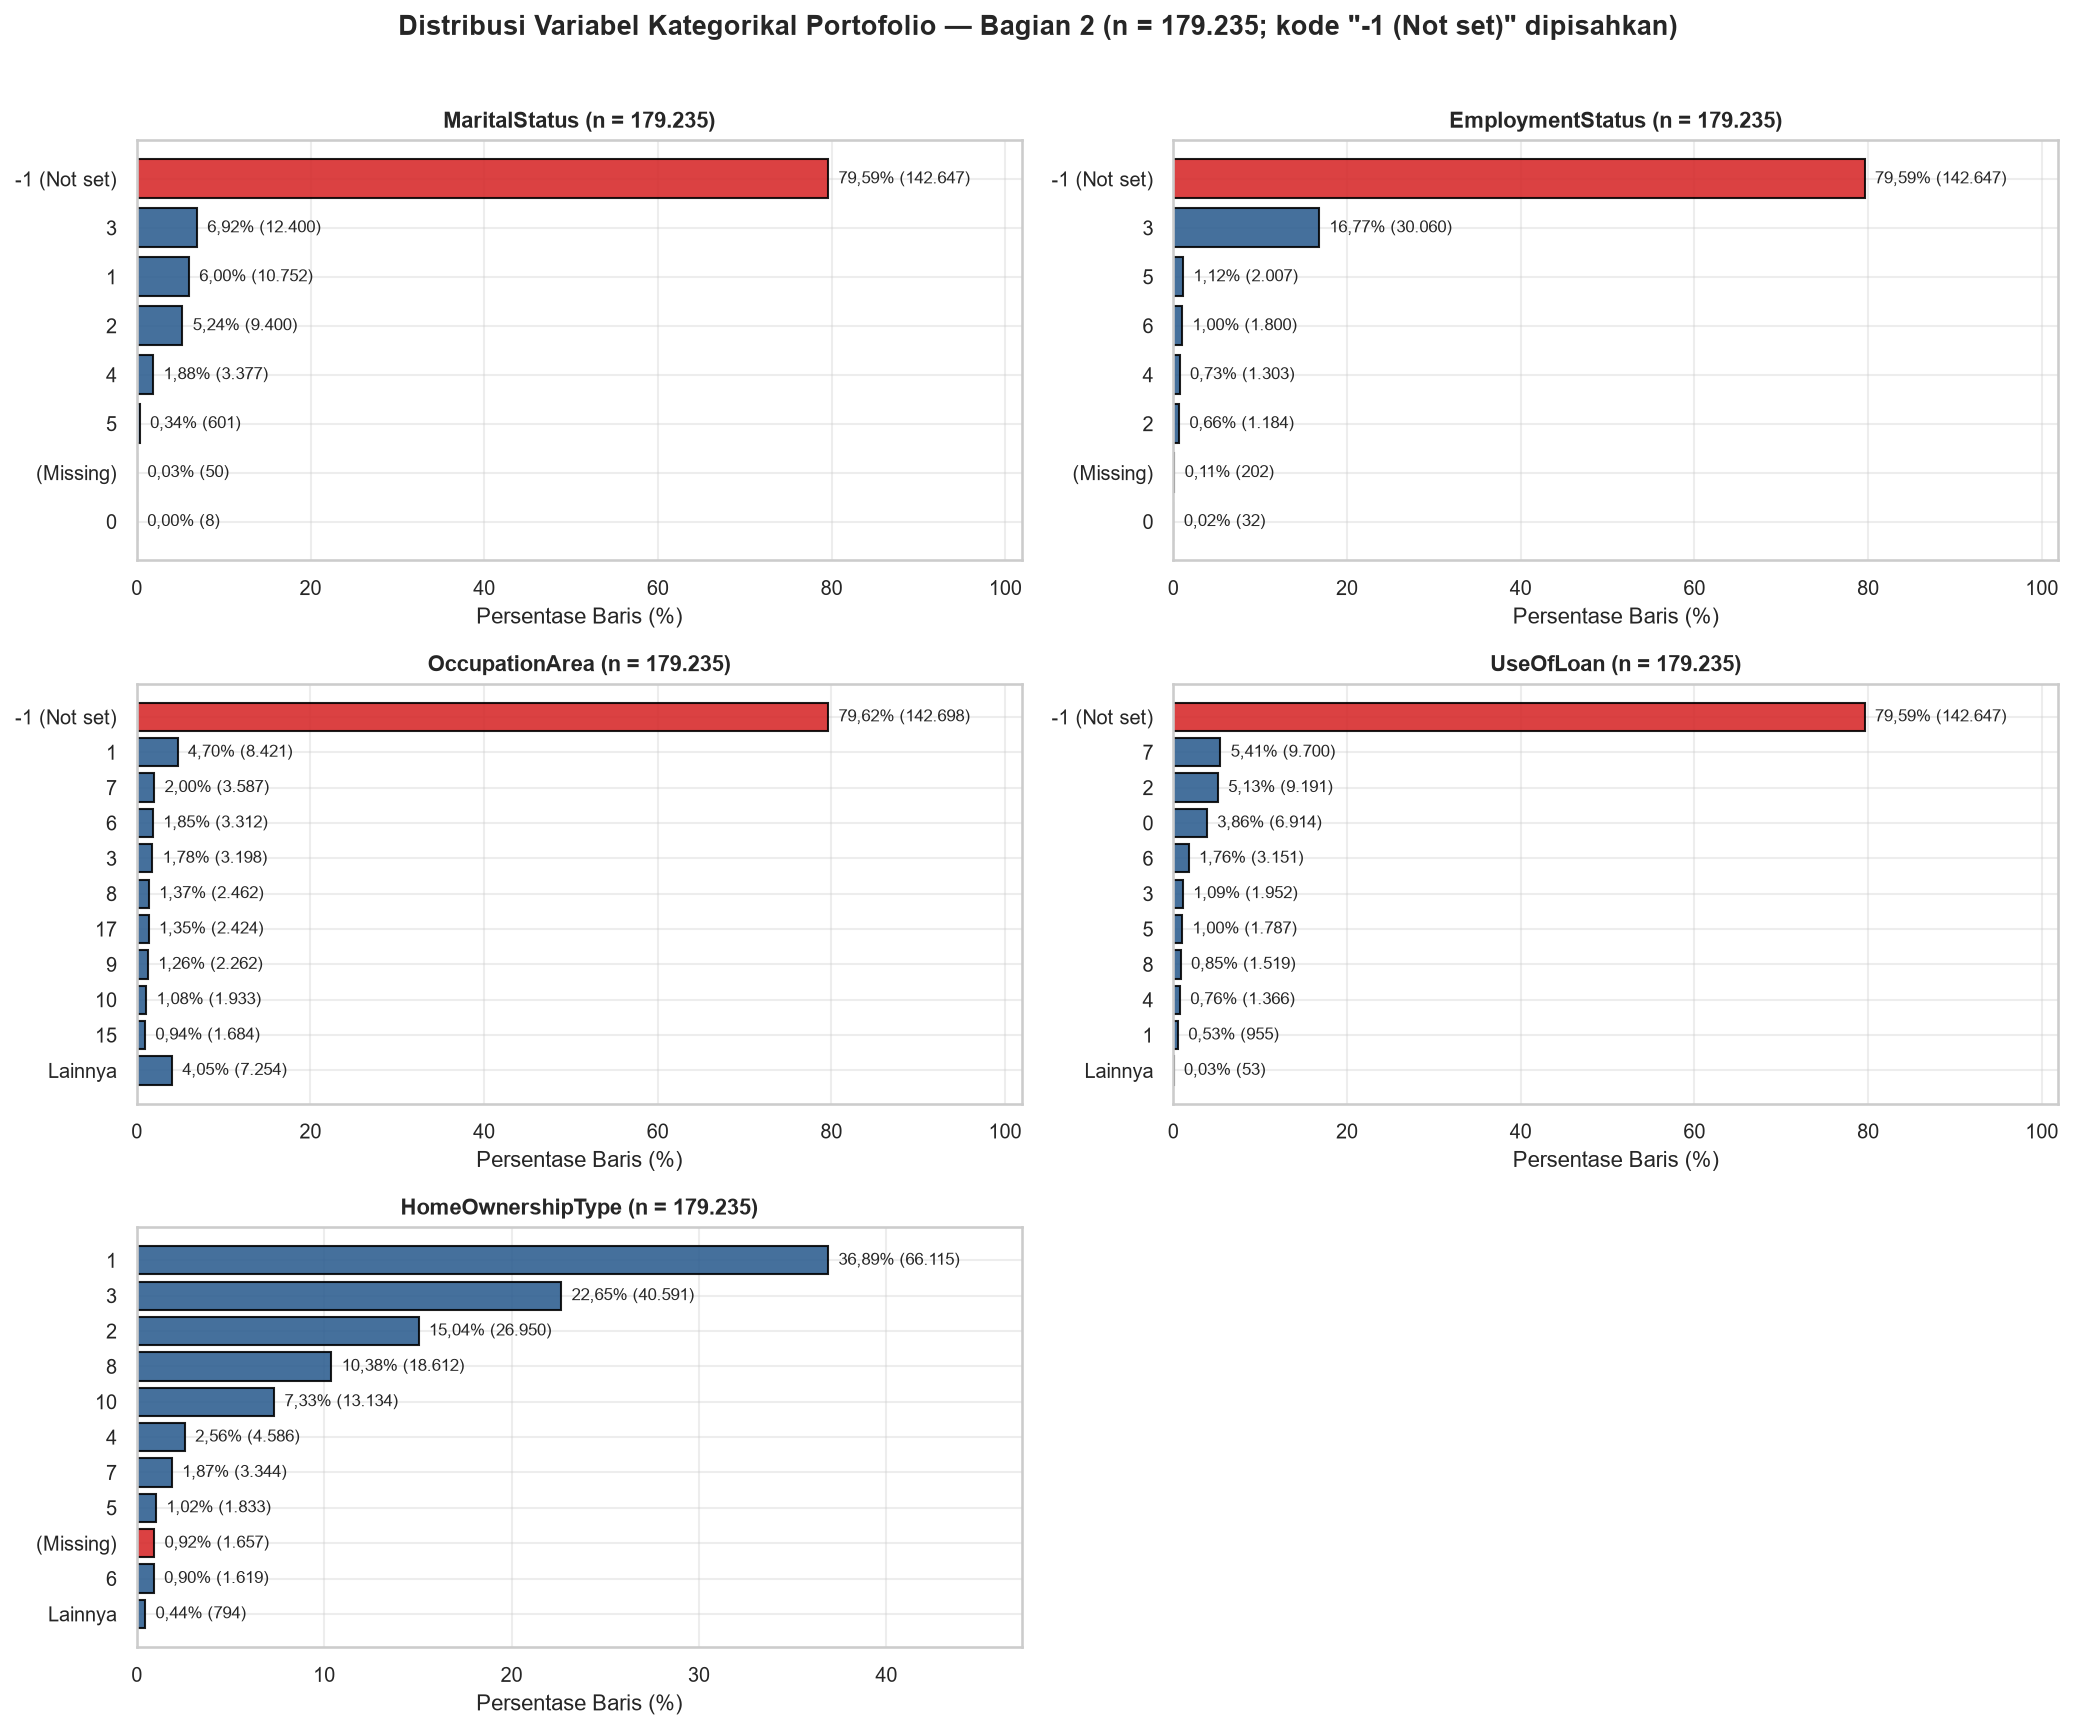

In [8]:
# Grafik Batang Horizontal Terurut untuk 11 Variabel Kategorikal Lainnya
other_cat_cols_1 = ['Rating', 'NewCreditCustomer', 'VerificationType', 'LanguageCode', 'Gender', 'Education']
other_cat_cols_2 = ['MaritalStatus', 'EmploymentStatus', 'OccupationArea', 'UseOfLoan', 'HomeOwnershipType']

for fig_name, cols_subset, fig_title in [
    ('02_categorical_distributions_1.png', other_cat_cols_1, 'Distribusi Variabel Kategorikal Portofolio — Bagian 1 (n = 179.235; kode angka: TODO label resmi)'),
    ('02_categorical_distributions_2.png', other_cat_cols_2, 'Distribusi Variabel Kategorikal Portofolio — Bagian 2 (n = 179.235; kode "-1 (Not set)" dipisahkan)'),
]:
    n_panels = len(cols_subset)
    n_rows_grid = int(np.ceil(n_panels / 2))
    fig, axes = plt.subplots(n_rows_grid, 2, figsize=(14, 3.8 * n_rows_grid))
    axes_flat = axes.flatten()
    for i, c_col in enumerate(cols_subset):
        ax = axes_flat[i]
        sub_ft = cat_freq_df.loc[cat_freq_df['variabel'] == c_col].copy()
        if len(sub_ft) > 12:
            top_ft = sub_ft.iloc[:10].copy()
            rest_jml = int(sub_ft.iloc[10:]['jumlah'].sum())
            rest_pct = float(sub_ft.iloc[10:]['persen'].sum())
            top_ft = pd.concat([top_ft, pd.DataFrame([{'variabel': c_col, 'nilai': 'Lainnya', 'jumlah': rest_jml, 'persen': rest_pct}])], ignore_index=True)
        else:
            top_ft = sub_ft
        bar_colors = ['#d62728' if 'Not set' in str(v) or 'Missing' in str(v) else '#2b5c8f' for v in top_ft['nilai'][::-1]]
        bars = ax.barh(top_ft['nilai'][::-1], top_ft['persen'][::-1], color=bar_colors, edgecolor='black', alpha=0.88)
        ax.set_title(f'{c_col} (n = {fmt_id(n_total, is_int=True)})', fontsize=10.5)
        ax.set_xlabel('Persentase Baris (%)')
        ax.set_xlim(0, max(top_ft['persen']) * 1.28)
        for bar, jml, pct in zip(bars, top_ft['jumlah'][::-1], top_ft['persen'][::-1]):
            ax.text(bar.get_width() + max(top_ft['persen']) * 0.015, bar.get_y() + bar.get_height() / 2, f'{fmt_id(pct, 2)}% ({fmt_id(jml, is_int=True)})', va='center', fontsize=8.3)
    for j in range(len(cols_subset), len(axes_flat)):
        axes_flat[j].axis('off')
    fig.suptitle(fig_title, fontsize=13, fontweight='bold', y=1.01)
    fig.tight_layout()
    save_fig(fig, fig_name, close=False)
    plt.show()
    plt.close(fig)

### Ringkasan Observasi Bagian C (Variabel Kategorikal)
- **Konsentrasi Geografis (`Country`, `02_country_distribution.png`):** Portofolio sangat terkonsentrasi di Estonia (**EE**: **110.714** pinjaman, **61,77%**), diikuti Finlandia (**FI**: **41.955** pinjaman, **23,41%**) dan Spanyol (**ES**: **26.270** pinjaman, **14,66%**), sedangkan Slovakia (**SK**) hanya mencakup **296** pinjaman (**0,17%**).
- **Dominasi Kode Sentinel `-1 (Not set)` (`02_categorical_distributions_2.png`):** Empat kolom demografi/aplikasi memiliki proporsi kode `-1 (Not set)` hampir **80%** dari seluruh portofolio, yaitu `OccupationArea` (**142.698** baris, **79,62%**), `MaritalStatus` (**142.647** baris, **79,59%**), `EmploymentStatus` (**142.647** baris, **79,59%**), dan `UseOfLoan` (**142.647** baris, **79,59%**). *(Catatan dokumentasi pihak ketiga — **belum terverifikasi dengan sumber resmi**: kode `-1` pada `UseOfLoan` merupakan nilai baku untuk lelang pinjaman sejak Juni 2017.)* Sebaliknya, pada `Education` kode `-1 (Not set)` hanya tercatat **729** baris (**0,41%**) dan pada `HomeOwnershipType` hanya **3** baris (**0,0017%**).
- **Distribusi `Rating` & `VerificationType` (`02_categorical_distributions_1.png`):** Kelas risiko internal Bondora didominasi oleh peringkat menengah-bawah: `D` (**36.784** baris, **20,52%**), `E` (**33.067** baris, **18,45%**), `C` (**29.766** baris, **16,61%**), `F` (**25.332** baris, **14,13%**), dan `B` (**22.589** baris, **12,60%**), sementara peringkat tertinggi `AA` (**6.582** baris, **3,67%**) dan `A` (**7.551** baris, **4,21%**) mencakup kurang dari 8% portofolio. Pada `VerificationType` (`TODO: label resmi`), kode `4` mencakup **115.157** baris (**64,25%**) dan kode `1` mencakup **52.764** baris (**29,44%**).

## Bagian D — Tren Waktu (`02_yearly_trend.csv`, `02_outcome_by_year.csv`, `02_missing_by_year.csv`)

Bagian ini mengeksplorasi dinamika portofolio antar-tahun (`loan_year`, 2009–2021) dan antar-bulan (`loan_month`), pergeseran komposisi negara, perubahan pencatatan kode `-1 (Not set)` dan `ModelVersion`, komposisi 4 kelompok hasil beserta tingkat resolusi (*censoring*), serta distribusi nilai kosong (*missing*) per tahun.

,loan_year,n_loans,total_amount_eur,mean_amount_eur,median_amount_eur,mean_interest,median_interest,mean_loan_duration,median_loan_duration,mean_income_total,median_income_total,weighted_interest
0,2009,665,1.335688e+05,200.855404,191.7350,29.719549,30.00,9.836090,7.0,12447.944361,11000.0,30.251881
1,2010,1157,3.997380e+05,345.495252,236.4978,32.626621,32.00,12.178047,12.0,12104.394123,10800.0,32.201645
2,2011,451,4.971600e+05,1102.350333,950.0000,25.648559,25.00,18.037694,24.0,963.536962,800.0,25.811650
3,2012,457,7.020750e+05,1536.269147,1200.0000,24.109409,28.00,20.859956,24.0,926.100000,800.0,24.383855
4,2013,2512,7.588440e+06,3020.875796,2500.0000,26.391322,28.00,36.601115,36.0,1009.165207,832.0,26.527671
5,2014,7455,1.930710e+07,2589.818511,2000.0000,29.300076,31.00,40.314420,36.0,1236.093325,1030.0,28.034272
6,2015,8046,2.005198e+07,2492.168158,2000.0000,33.055880,29.25,50.387025,60.0,1490.360303,1300.0,30.346625
7,2016,10514,2.843780e+07,2704.755564,2125.0000,41.168015,32.17,41.869317,36.0,1445.132205,1200.0,36.285592
8,2017,17933,3.490102e+07,1946.189706,1472.0000,46.725939,26.05,43.382647,36.0,1393.229442,1144.0,36.124101
9,2018,25103,6.087211e+07,2424.893957,2020.0000,31.739561,28.08,46.951799,48.0,1752.025934,1300.0,34.172630


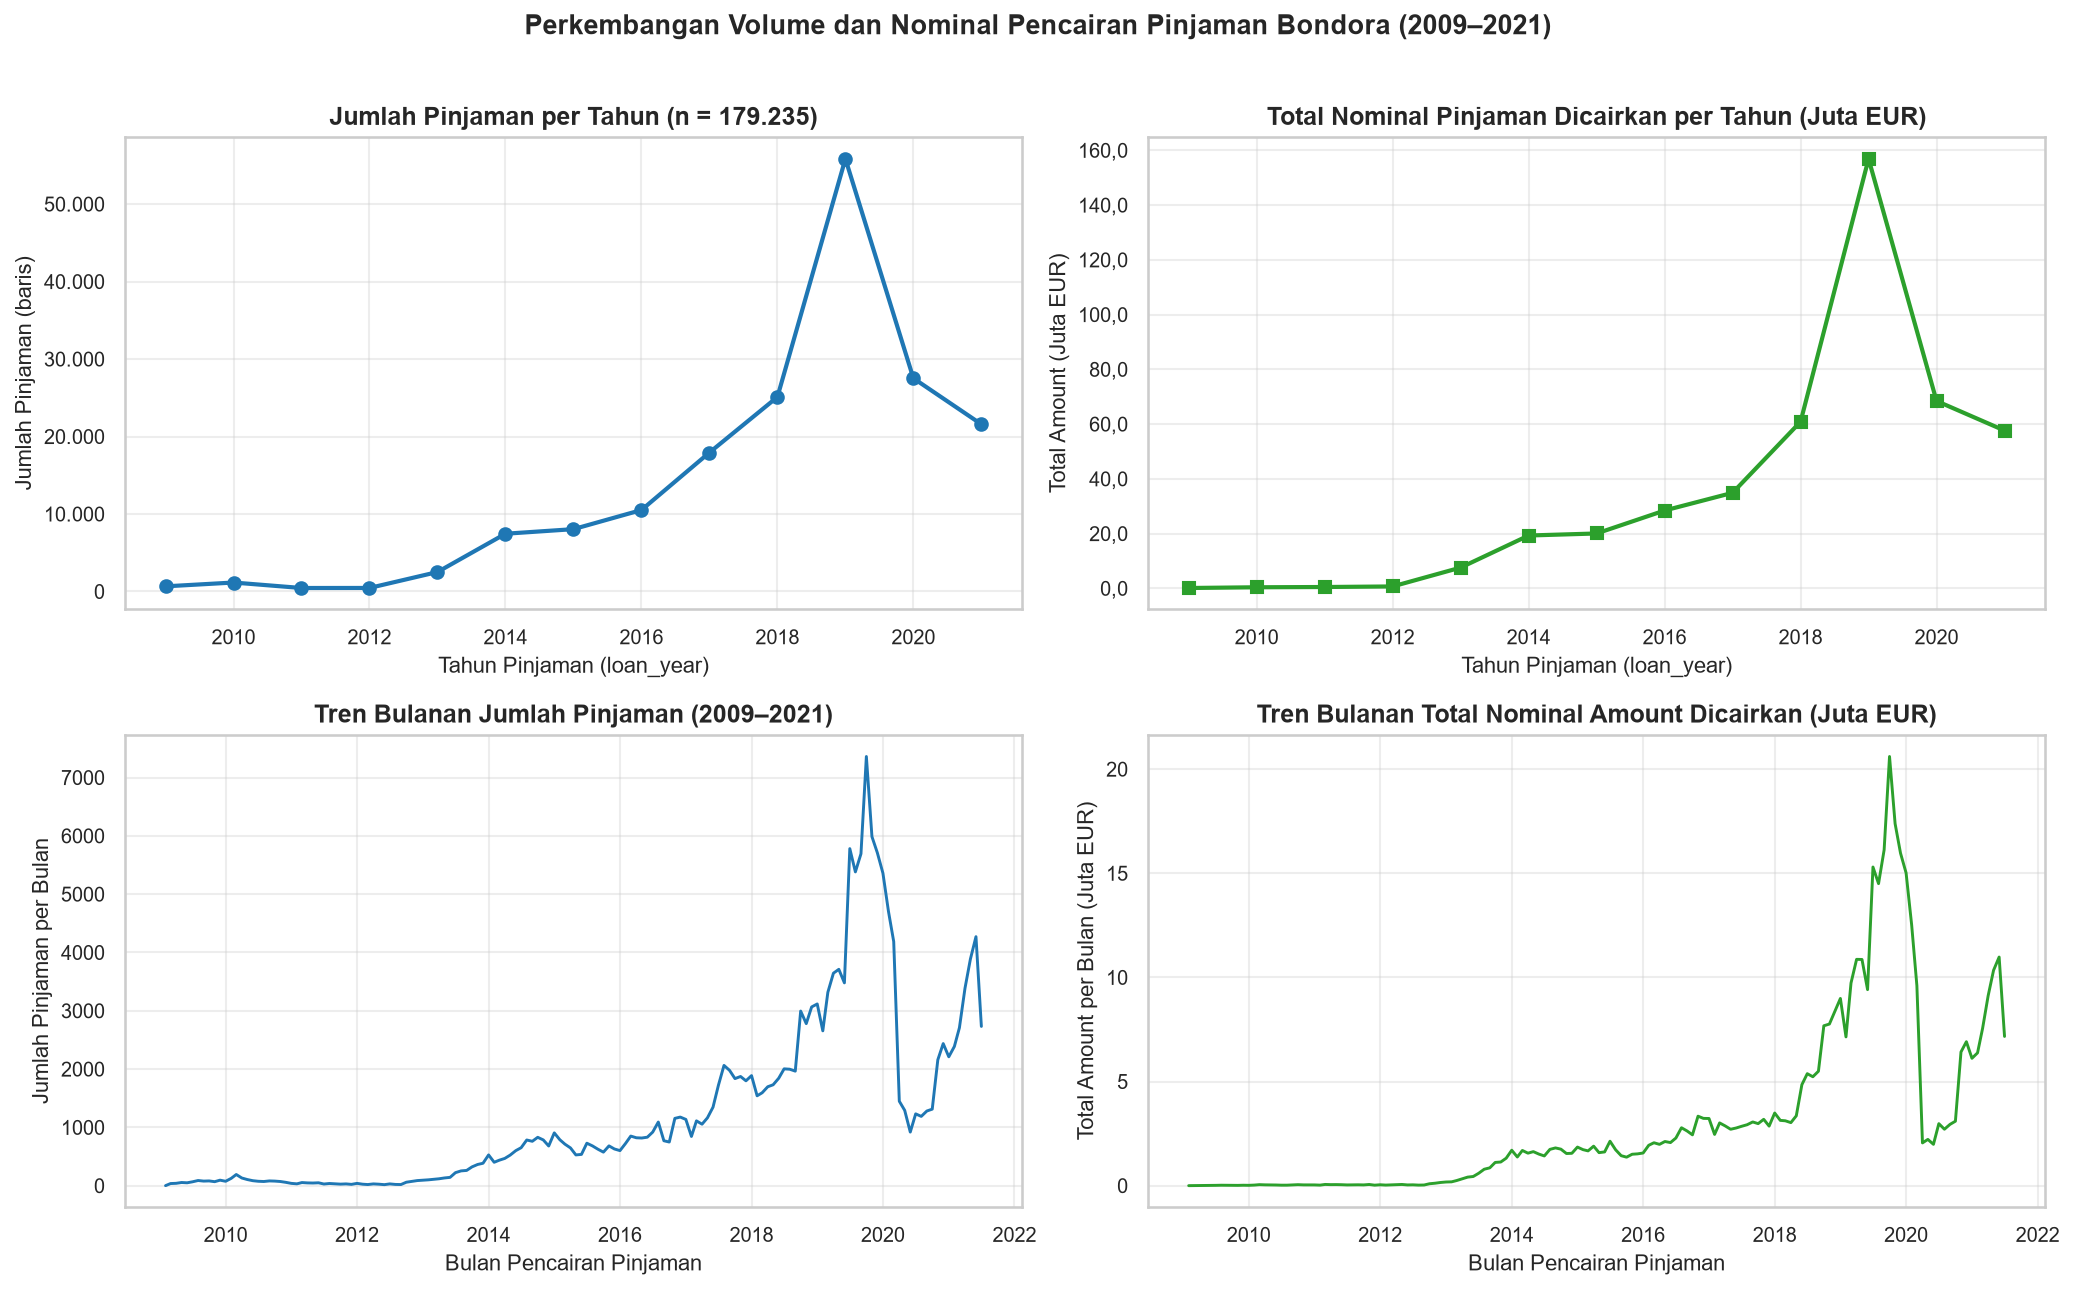

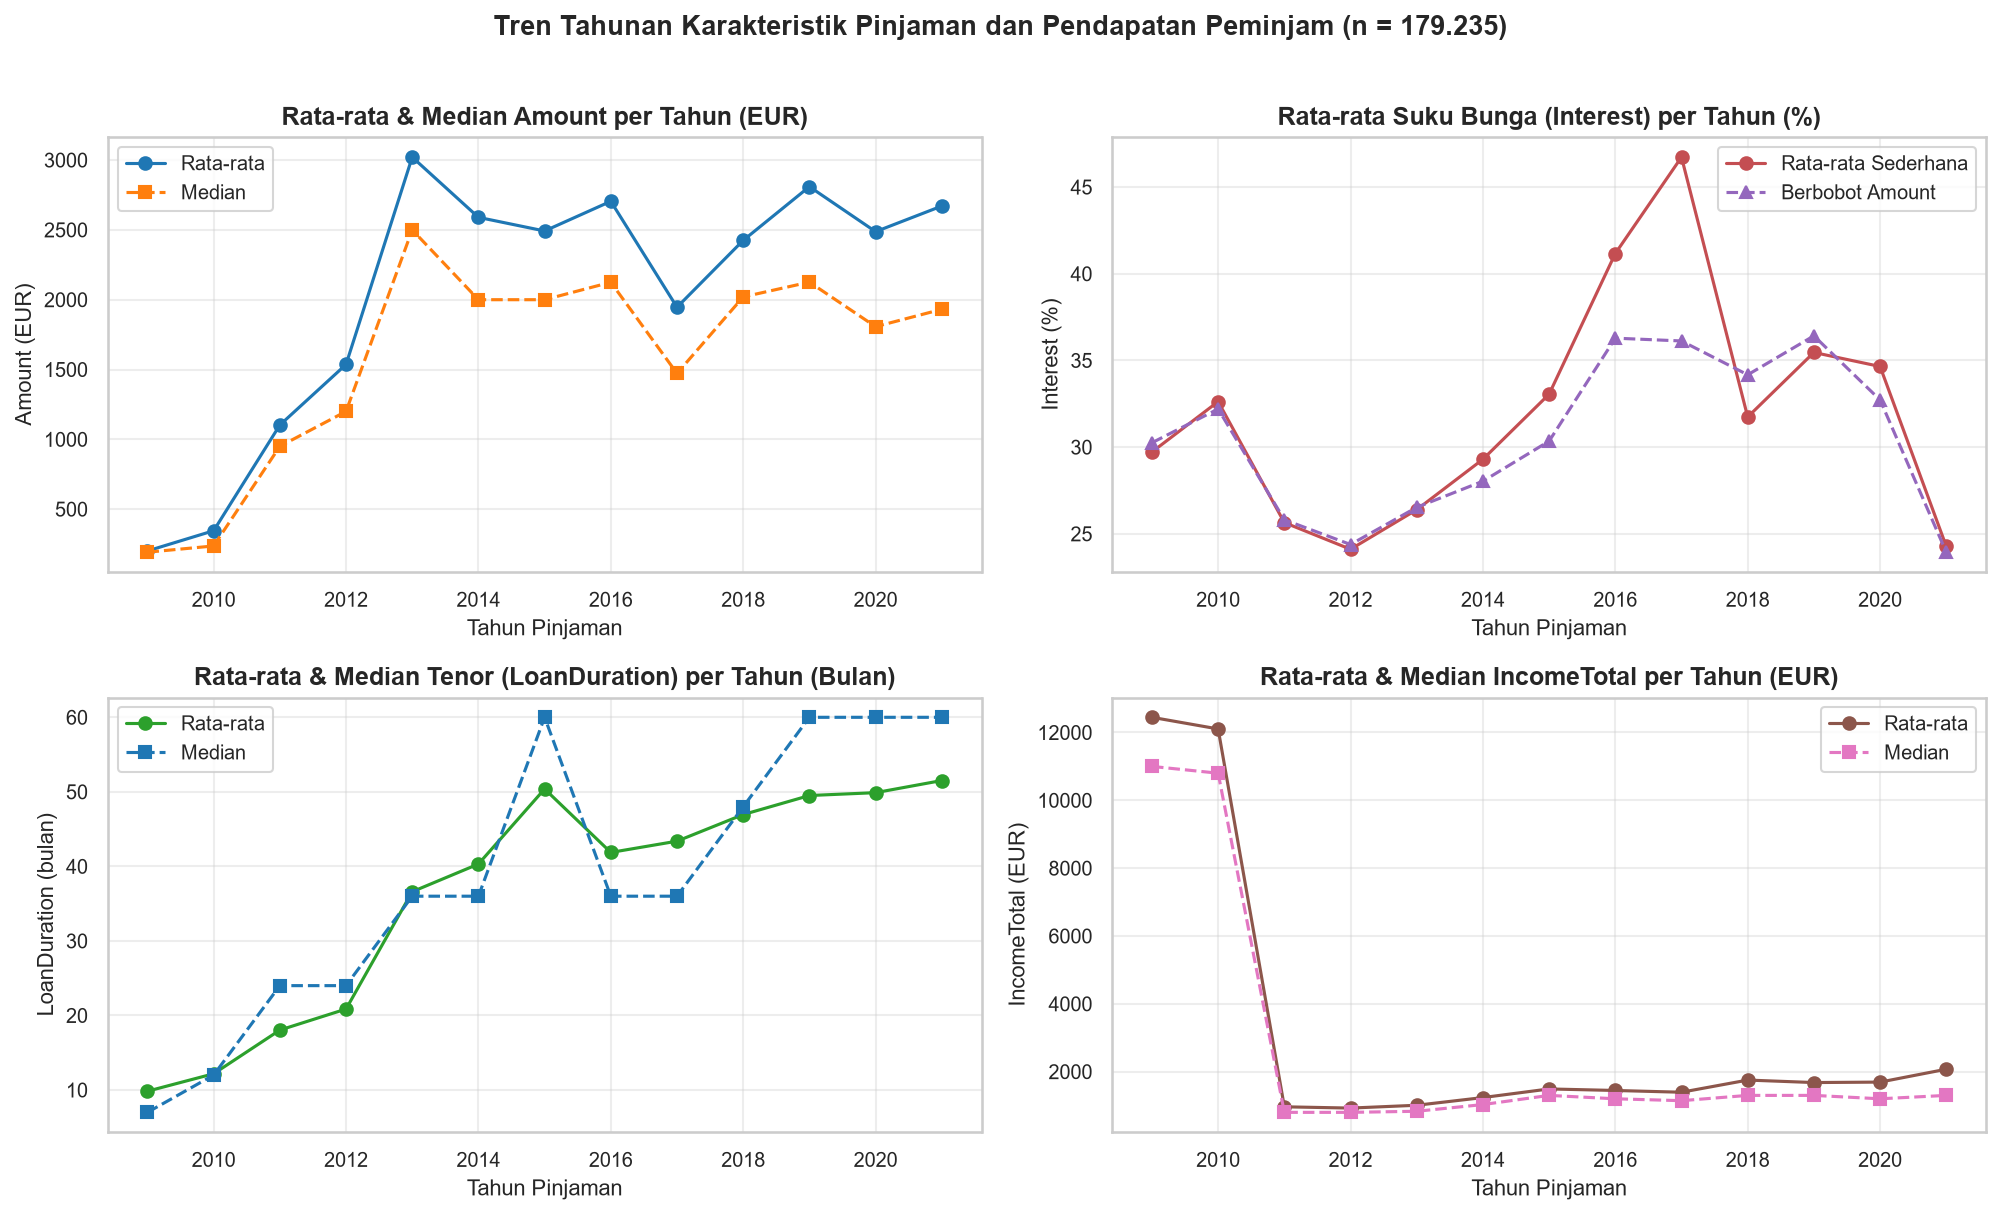

In [9]:
# 1 & 2. Tren Tahunan & Bulanan Volume, Nominal, Bunga, Tenor, dan Pendapatan -> 02_yearly_trend.csv
yearly_grp = df.groupby('loan_year', observed=True)
yearly_trend = yearly_grp.agg(
    n_loans=('LoanId', 'count'),
    total_amount_eur=('Amount', 'sum'),
    mean_amount_eur=('Amount', 'mean'),
    median_amount_eur=('Amount', 'median'),
    mean_interest=('Interest', 'mean'),
    median_interest=('Interest', 'median'),
    mean_loan_duration=('LoanDuration', 'mean'),
    median_loan_duration=('LoanDuration', 'median'),
    mean_income_total=('IncomeTotal', 'mean'),
    median_income_total=('IncomeTotal', 'median'),
).reset_index()

int_amt_by_yr = df.assign(_ia=df['Interest'] * df['Amount']).groupby('loan_year', observed=True)['_ia'].sum().reset_index()
yearly_trend = yearly_trend.merge(int_amt_by_yr, on='loan_year', how='left')
yearly_trend['weighted_interest'] = yearly_trend['_ia'] / yearly_trend['total_amount_eur']
yearly_trend = yearly_trend.drop(columns=['_ia'])
yearly_trend.to_csv(TABLES_DIR / '02_yearly_trend.csv', index=False)
display(yearly_trend)

df_ym = (
    df.assign(year_month=pd.to_datetime(df['loan_year'].astype(str) + '-' + df['loan_month'].astype(str).str.zfill(2) + '-01'))
    .groupby('year_month', observed=True)
    .agg(n_loans=('LoanId', 'count'), total_amount_eur=('Amount', 'sum'))
    .reset_index()
    .sort_values('year_month')
)

fig, axes = plt.subplots(2, 2, figsize=(14, 8.5))
axes[0, 0].plot(yearly_trend['loan_year'], yearly_trend['n_loans'], marker='o', linewidth=2, color='#1f77b4')
axes[0, 0].set_title(f'Jumlah Pinjaman per Tahun (n = {fmt_id(n_total, is_int=True)})')
axes[0, 0].set_xlabel('Tahun Pinjaman (loan_year)')
axes[0, 0].set_ylabel('Jumlah Pinjaman (baris)')
axes[0, 0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: fmt_id(x, is_int=True)))

axes[0, 1].plot(yearly_trend['loan_year'], yearly_trend['total_amount_eur'] / 1e6, marker='s', linewidth=2, color='#2ca02c')
axes[0, 1].set_title('Total Nominal Pinjaman Dicairkan per Tahun (Juta EUR)')
axes[0, 1].set_xlabel('Tahun Pinjaman (loan_year)')
axes[0, 1].set_ylabel('Total Amount (Juta EUR)')
axes[0, 1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: fmt_id(x, 1)))

axes[1, 0].plot(df_ym['year_month'], df_ym['n_loans'], linewidth=1.4, color='#1f77b4')
axes[1, 0].set_title('Tren Bulanan Jumlah Pinjaman (2009–2021)')
axes[1, 0].set_xlabel('Bulan Pencairan Pinjaman')
axes[1, 0].set_ylabel('Jumlah Pinjaman per Bulan')

axes[1, 1].plot(df_ym['year_month'], df_ym['total_amount_eur'] / 1e6, linewidth=1.4, color='#2ca02c')
axes[1, 1].set_title('Tren Bulanan Total Nominal Amount Dicairkan (Juta EUR)')
axes[1, 1].set_xlabel('Bulan Pencairan Pinjaman')
axes[1, 1].set_ylabel('Total Amount per Bulan (Juta EUR)')

fig.suptitle('Perkembangan Volume dan Nominal Pencairan Pinjaman Bondora (2009–2021)', fontsize=13, fontweight='bold', y=1.01)
fig.tight_layout()
save_fig(fig, '02_loan_volume_trend.png', close=False)
plt.show()
plt.close(fig)

fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.0))
axes[0, 0].plot(yearly_trend['loan_year'], yearly_trend['mean_amount_eur'], marker='o', label='Rata-rata', color='#1f77b4')
axes[0, 0].plot(yearly_trend['loan_year'], yearly_trend['median_amount_eur'], marker='s', linestyle='--', label='Median', color='#ff7f0e')
axes[0, 0].set_title('Rata-rata & Median Amount per Tahun (EUR)')
axes[0, 0].set_xlabel('Tahun Pinjaman')
axes[0, 0].set_ylabel('Amount (EUR)')
axes[0, 0].legend()

axes[0, 1].plot(yearly_trend['loan_year'], yearly_trend['mean_interest'], marker='o', label='Rata-rata Sederhana', color='#c44e52')
axes[0, 1].plot(yearly_trend['loan_year'], yearly_trend['weighted_interest'], marker='^', linestyle='--', label='Berbobot Amount', color='#9467bd')
axes[0, 1].set_title('Rata-rata Suku Bunga (Interest) per Tahun (%)')
axes[0, 1].set_xlabel('Tahun Pinjaman')
axes[0, 1].set_ylabel('Interest (%)')
axes[0, 1].legend()

axes[1, 0].plot(yearly_trend['loan_year'], yearly_trend['mean_loan_duration'], marker='o', label='Rata-rata', color='#2ca02c')
axes[1, 0].plot(yearly_trend['loan_year'], yearly_trend['median_loan_duration'], marker='s', linestyle='--', label='Median', color='#1f77b4')
axes[1, 0].set_title('Rata-rata & Median Tenor (LoanDuration) per Tahun (Bulan)')
axes[1, 0].set_xlabel('Tahun Pinjaman')
axes[1, 0].set_ylabel('LoanDuration (bulan)')
axes[1, 0].legend()

axes[1, 1].plot(yearly_trend['loan_year'], yearly_trend['mean_income_total'], marker='o', label='Rata-rata', color='#8c564b')
axes[1, 1].plot(yearly_trend['loan_year'], yearly_trend['median_income_total'], marker='s', linestyle='--', label='Median', color='#e377c2')
axes[1, 1].set_title('Rata-rata & Median IncomeTotal per Tahun (EUR)')
axes[1, 1].set_xlabel('Tahun Pinjaman')
axes[1, 1].set_ylabel('IncomeTotal (EUR)')
axes[1, 1].legend()

fig.suptitle('Tren Tahunan Karakteristik Pinjaman dan Pendapatan Peminjam (n = 179.235)', fontsize=13, fontweight='bold', y=1.01)
fig.tight_layout()
save_fig(fig, '02_yearly_metrics_trend.png', close=False)
plt.show()
plt.close(fig)

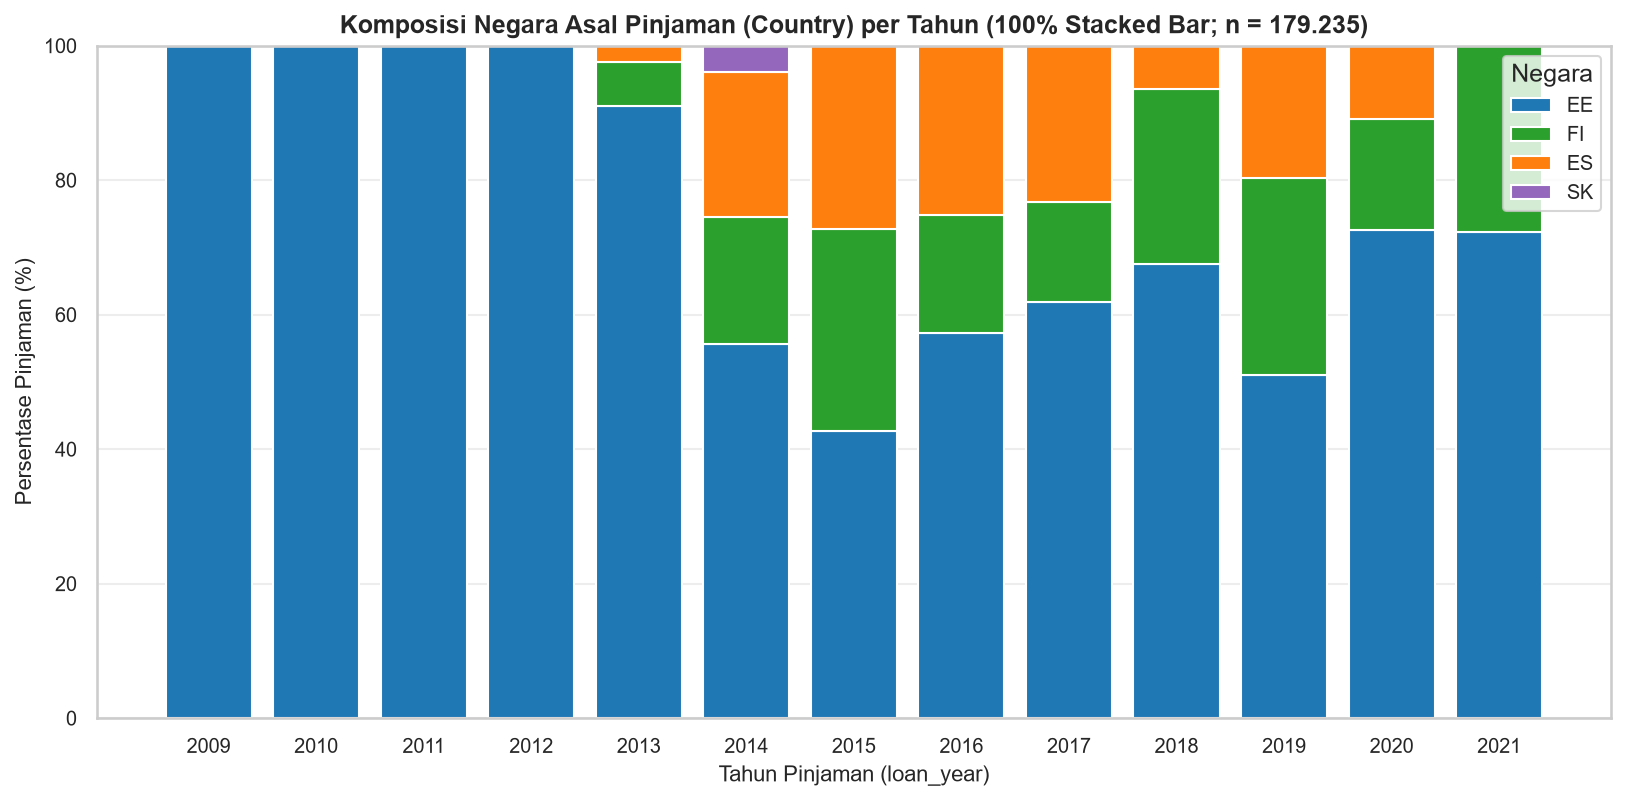

,loan_year,MaritalStatus,EmploymentStatus,OccupationArea,UseOfLoan,Education
0,2009,0.00,0.00,0.00,0.00,0.00
1,2010,0.00,0.00,0.00,0.00,0.00
2,2011,0.00,0.00,0.00,0.00,0.00
3,2012,0.00,0.00,0.00,0.00,0.00
4,2013,0.00,0.00,0.00,0.00,0.00
5,2014,0.00,0.00,0.66,0.00,0.00
6,2015,0.00,0.00,0.02,0.00,0.00
7,2016,0.00,0.00,0.00,0.00,0.00
8,2017,70.27,70.27,70.27,70.27,0.01
9,2018,100.00,100.00,100.00,100.00,0.01


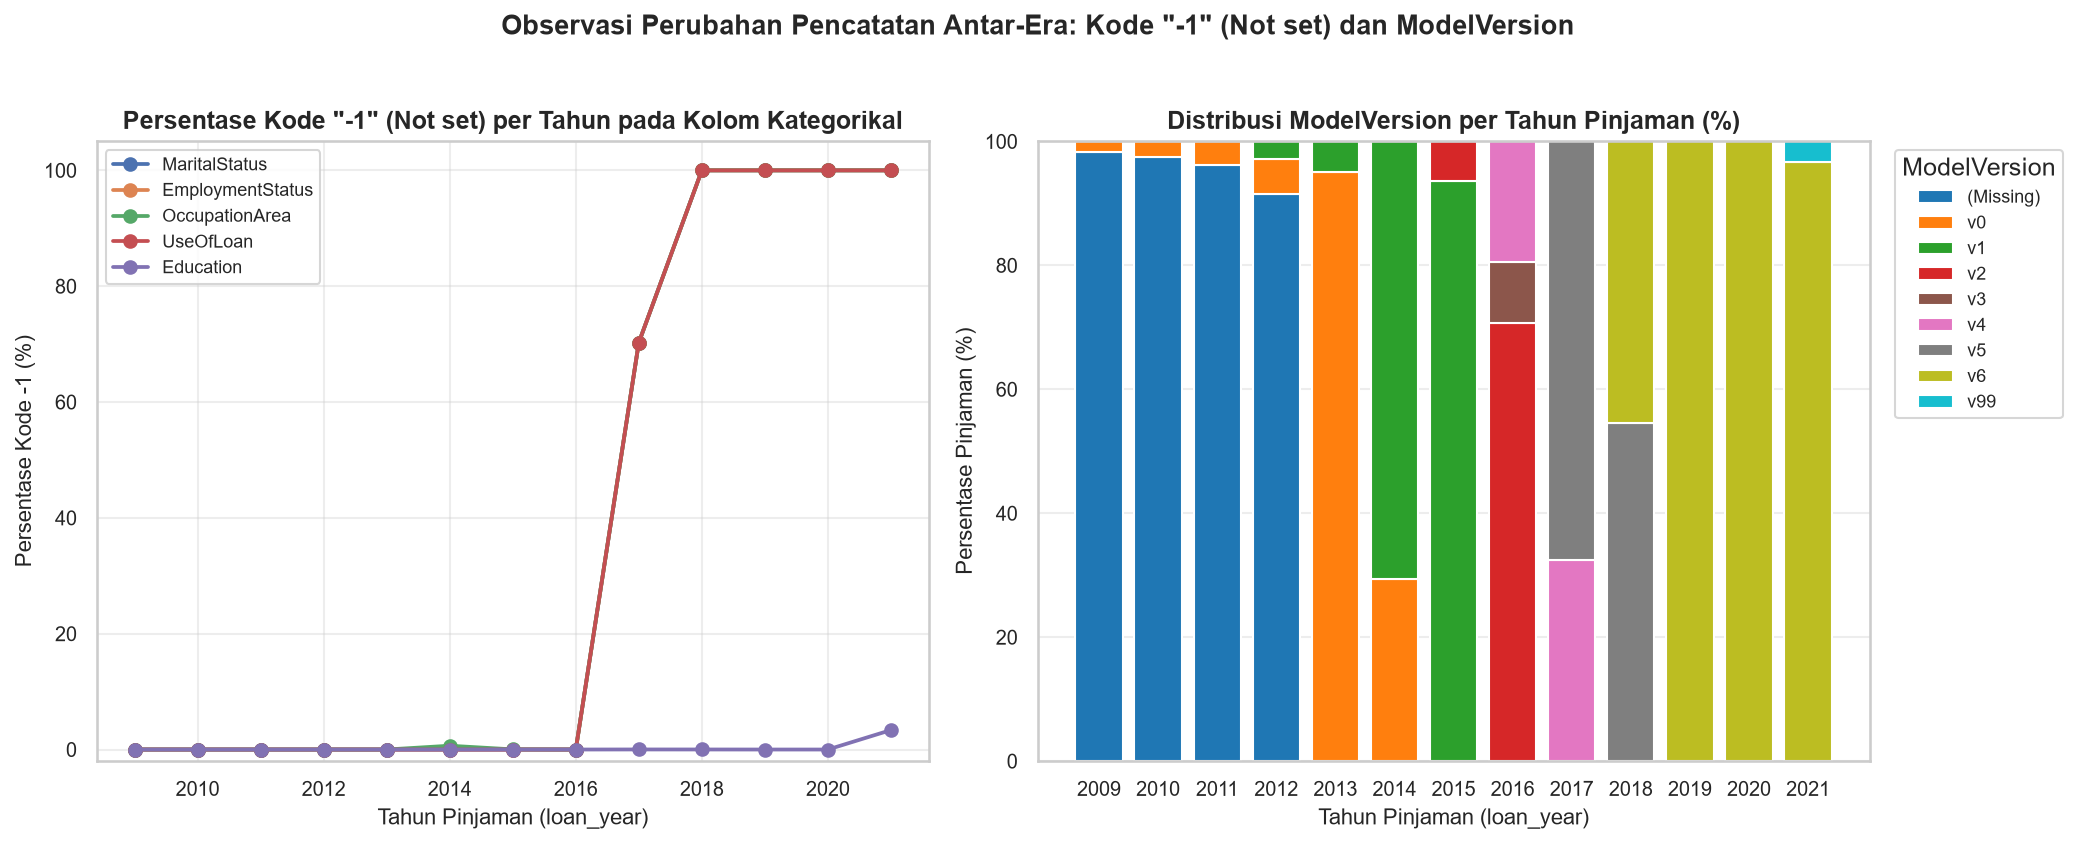

In [10]:
# 3 & 4. Komposisi Country per Tahun & Perubahan Pencatatan Antar-Era (-1 Not set & ModelVersion)
ct_country_yr = pd.crosstab(df['loan_year'], df['Country'], normalize='index') * 100.0
fig, ax = plt.subplots(figsize=(11, 5.5))
bottom = np.zeros(len(ct_country_yr))
c_palette = {'EE': '#1f77b4', 'FI': '#2ca02c', 'ES': '#ff7f0e', 'SK': '#9467bd'}
for c_code in ['EE', 'FI', 'ES', 'SK']:
    if c_code in ct_country_yr.columns:
        vals_c = ct_country_yr[c_code].to_numpy()
        ax.bar(ct_country_yr.index.astype(str), vals_c, bottom=bottom, label=c_code, color=c_palette.get(c_code, '#7f7f7f'), edgecolor='white')
        bottom += vals_c
ax.set_title('Komposisi Negara Asal Pinjaman (Country) per Tahun (100% Stacked Bar; n = 179.235)')
ax.set_xlabel('Tahun Pinjaman (loan_year)')
ax.set_ylabel('Persentase Pinjaman (%)')
ax.set_ylim(0, 100)
ax.legend(title='Negara', loc='upper right')
fig.tight_layout()
save_fig(fig, '02_country_mix_by_year.png', close=False)
plt.show()
plt.close(fig)

sentinel_cols = ['MaritalStatus', 'EmploymentStatus', 'OccupationArea', 'UseOfLoan', 'Education']
sentinel_yr = pd.DataFrame({'loan_year': yearly_trend['loan_year']})
for scol in sentinel_cols:
    s_is_neg1 = df[scol].astype(str).str.strip().isin(['-1', '-1.0'])
    pct_by_yr = s_is_neg1.groupby(df['loan_year'], observed=True).mean() * 100.0
    sentinel_yr[scol] = sentinel_yr['loan_year'].map(pct_by_yr)
display(sentinel_yr.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for scol in sentinel_cols:
    axes[0].plot(sentinel_yr['loan_year'], sentinel_yr[scol], marker='o', linewidth=1.8, label=scol)
axes[0].set_title('Persentase Kode "-1" (Not set) per Tahun pada Kolom Kategorikal')
axes[0].set_xlabel('Tahun Pinjaman (loan_year)')
axes[0].set_ylabel('Persentase Kode -1 (%)')
axes[0].set_ylim(-2, 105)
axes[0].legend(fontsize=8.5)

mv_str = df['ModelVersion'].astype('object').where(df['ModelVersion'].notna(), '(Missing)').astype(str).str.replace('.0', '', regex=False)
ct_mv_yr = pd.crosstab(df['loan_year'], mv_str, normalize='index') * 100.0
bottom_mv = np.zeros(len(ct_mv_yr))
cmap_mv = plt.cm.tab10(np.linspace(0, 1, len(ct_mv_yr.columns)))
for idx_c, mv_val in enumerate(ct_mv_yr.columns):
    vals_mv = ct_mv_yr[mv_val].to_numpy()
    axes[1].bar(ct_mv_yr.index.astype(str), vals_mv, bottom=bottom_mv, label=f'v{mv_val}' if mv_val != '(Missing)' else '(Missing)', color=cmap_mv[idx_c], edgecolor='white')
    bottom_mv += vals_mv
axes[1].set_title('Distribusi ModelVersion per Tahun Pinjaman (%)')
axes[1].set_xlabel('Tahun Pinjaman (loan_year)')
axes[1].set_ylabel('Persentase Pinjaman (%)')
axes[1].set_ylim(0, 100)
axes[1].legend(title='ModelVersion', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8.5)

fig.suptitle('Observasi Perubahan Pencatatan Antar-Era: Kode "-1" (Not set) dan ModelVersion', fontsize=13, fontweight='bold', y=1.02)
fig.tight_layout()
save_fig(fig, '02_sentinel_and_model_version_by_year.png', close=False)
plt.show()
plt.close(fig)

,loan_year,n_total,n_resolved,pct_resolved,n_default,pct_default,n_lunas_tanpa_default,pct_lunas_tanpa_default,n_berjalan,pct_berjalan,n_terlambat_belum_default,pct_terlambat_belum_default
0,2009,665,665,100.00,259,38.95,406,61.05,0,0.00,0,0.00
1,2010,1157,1157,100.00,437,37.77,720,62.23,0,0.00,0,0.00
2,2011,451,451,100.00,125,27.72,326,72.28,0,0.00,0,0.00
3,2012,457,456,99.78,95,20.79,361,78.99,1,0.22,0,0.00
4,2013,2512,2481,98.77,887,35.31,1594,63.46,28,1.11,3,0.12
5,2014,7455,7324,98.24,4096,54.94,3228,43.30,116,1.56,15,0.20
6,2015,8046,7771,96.58,4863,60.44,2908,36.14,238,2.96,37,0.46
7,2016,10514,9905,94.21,6251,59.45,3654,34.75,544,5.17,65,0.62
8,2017,17933,15757,87.87,10531,58.72,5226,29.14,1935,10.79,241,1.34
9,2018,25103,18906,75.31,12266,48.86,6640,26.45,5389,21.47,808,3.22


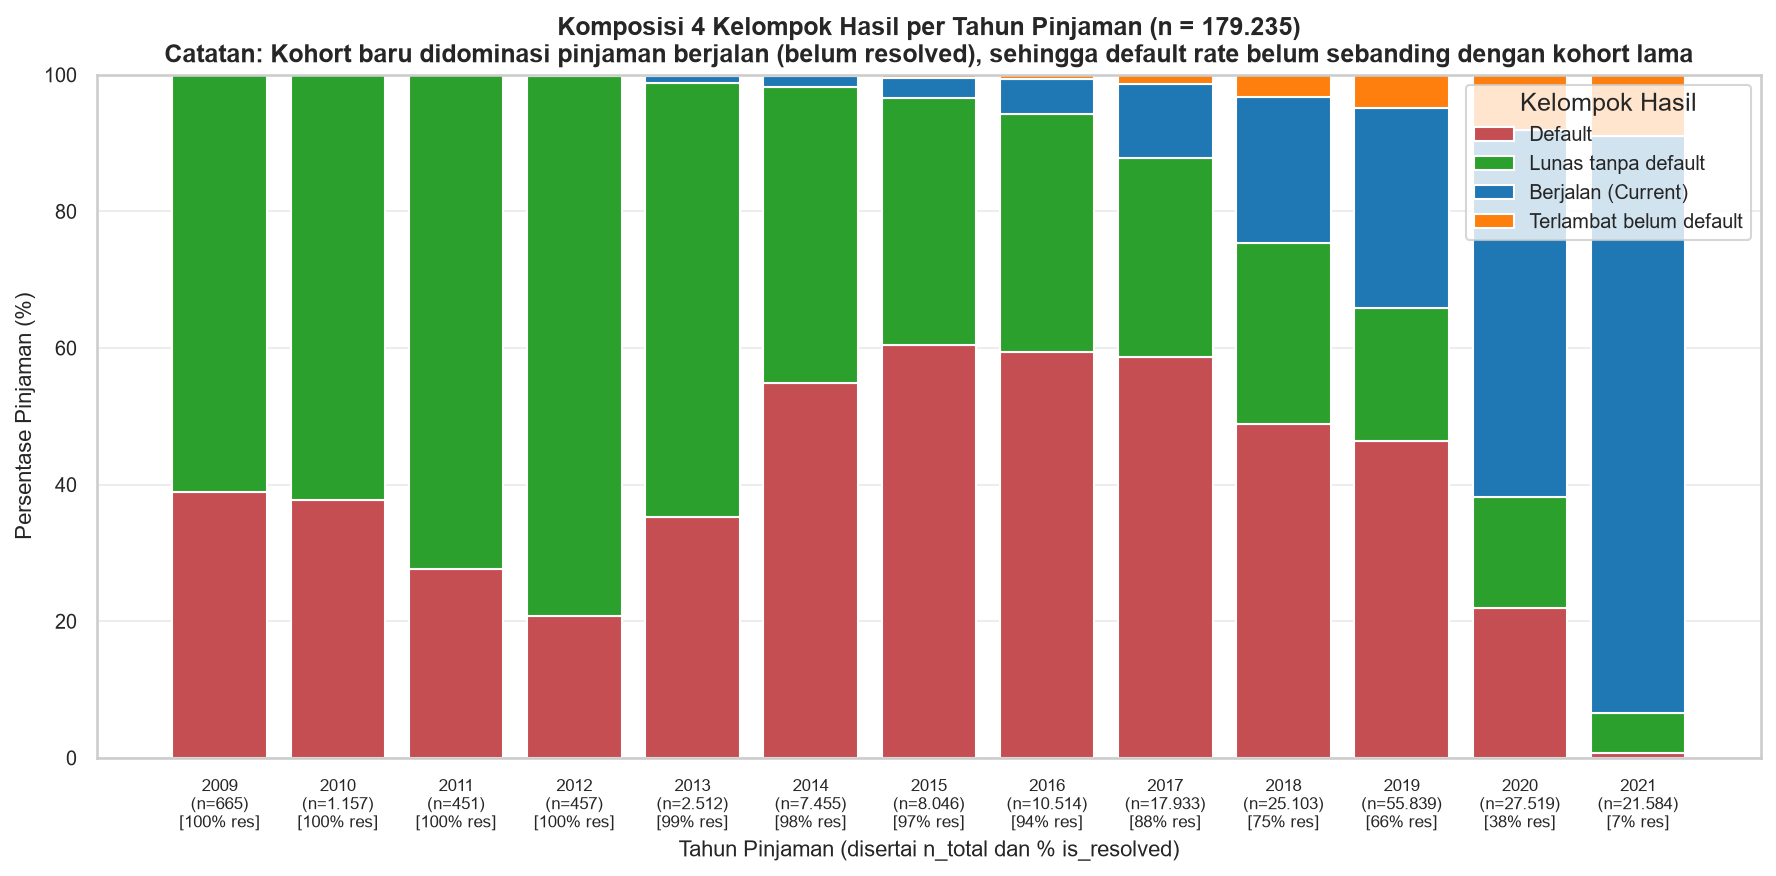

,loan_year,n_total,MonthlyPayment_n_missing,MonthlyPayment_pct_missing,PreviousRepaymentsBeforeLoan_n_missing,PreviousRepaymentsBeforeLoan_pct_missing,CreditScoreEsMicroL_n_missing,CreditScoreEsMicroL_pct_missing
0,2009,665,654,98.3459,0,0.0000,665,100.0000
1,2010,1157,1127,97.4071,0,0.0000,1157,100.0000
2,2011,451,434,96.2306,0,0.0000,451,100.0000
3,2012,457,427,93.4354,0,0.0000,457,100.0000
4,2013,2512,1741,69.3073,0,0.0000,2451,97.5717
5,2014,7455,2306,30.9323,0,0.0000,5847,78.4306
6,2015,8046,1,0.0124,0,0.0000,5859,72.8188
7,2016,10514,0,0.0000,0,0.0000,7872,74.8716
8,2017,17933,0,0.0000,0,0.0000,4820,26.8778
9,2018,25103,0,0.0000,5078,20.2287,0,0.0000


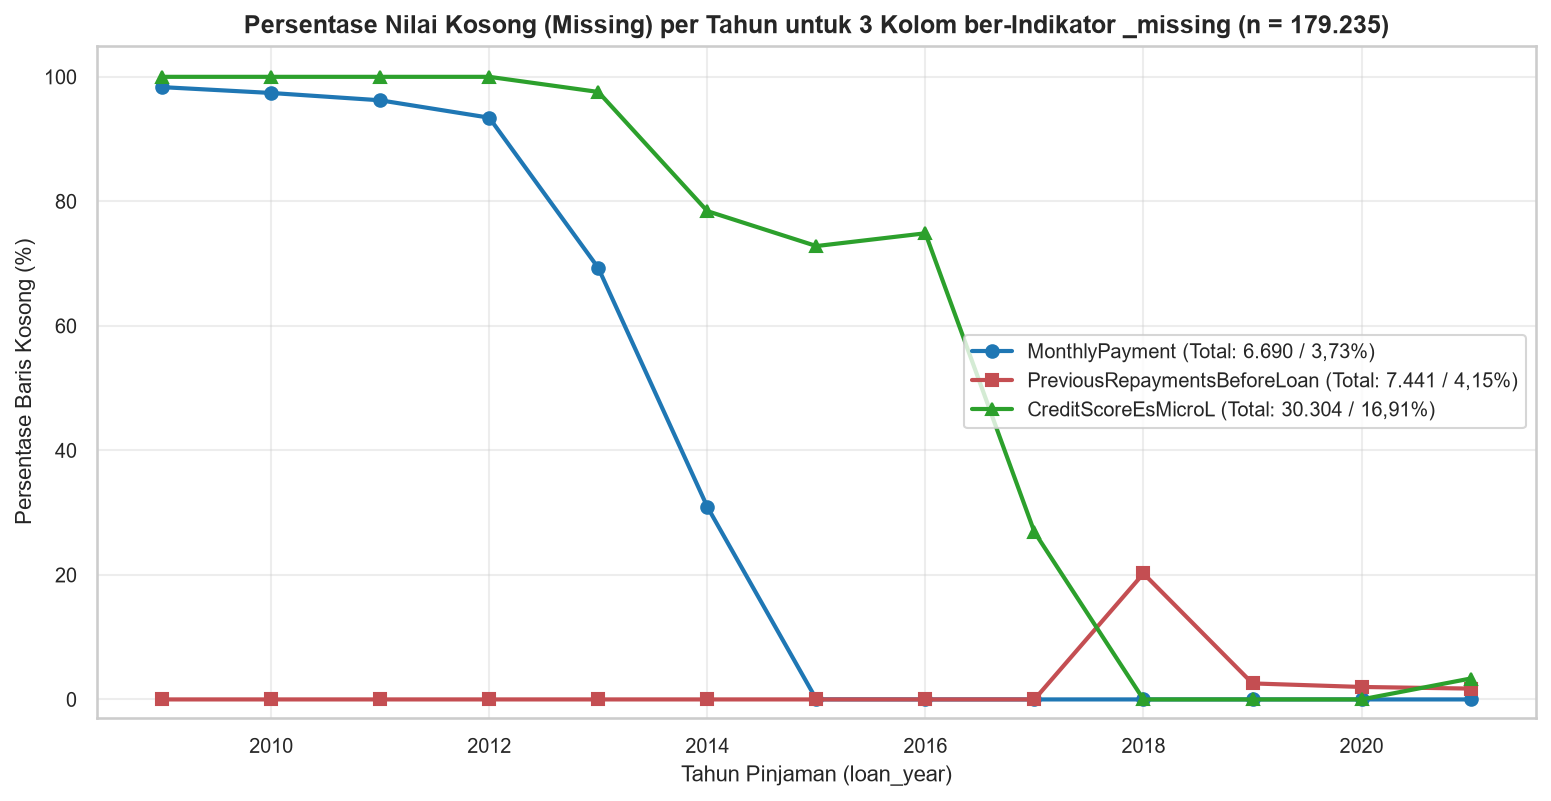

In [11]:
# 5 & 6. Komposisi 4 Kelompok Hasil per Tahun (02_outcome_by_year.csv) & Missing per Tahun (02_missing_by_year.csv)
outcome_yr_df = outcome_mix_by(df, 'loan_year')
outcome_yr_df.to_csv(TABLES_DIR / '02_outcome_by_year.csv', index=False)
display(outcome_yr_df)

fig, ax = plt.subplots(figsize=(12, 6.0))
bottom_og = np.zeros(len(outcome_yr_df))
pct_cols_map = [
    ('Default', 'pct_default'),
    ('Lunas tanpa default', 'pct_lunas_tanpa_default'),
    ('Berjalan (Current)', 'pct_berjalan'),
    ('Terlambat belum default', 'pct_terlambat_belum_default'),
]
x_labels = [f'{int(yr)}\n(n={fmt_id(nt, is_int=True)})\n[{fmt_id(pr, 0)}% res]' for yr, nt, pr in zip(outcome_yr_df['loan_year'], outcome_yr_df['n_total'], outcome_yr_df['pct_resolved'])]
for cat_label, pct_col in pct_cols_map:
    vals_og = outcome_yr_df[pct_col].to_numpy()
    ax.bar(x_labels, vals_og, bottom=bottom_og, label=cat_label, color=OUTCOME_PALETTE[cat_label], edgecolor='white')
    bottom_og += vals_og
ax.set_title(
    'Komposisi 4 Kelompok Hasil per Tahun Pinjaman (n = 179.235)\n'
    'Catatan: Kohort baru didominasi pinjaman berjalan (belum resolved), sehingga default rate belum sebanding dengan kohort lama'
)
ax.set_xlabel('Tahun Pinjaman (disertai n_total dan % is_resolved)')
ax.set_ylabel('Persentase Pinjaman (%)')
ax.set_ylim(0, 100)
ax.legend(title='Kelompok Hasil', loc='upper right')
plt.xticks(fontsize=8.0)
fig.tight_layout()
save_fig(fig, '02_outcome_mix_by_year.png', close=False)
plt.show()
plt.close(fig)

# Pemeriksaan Missing per Tahun untuk 3 Kolom ber-Indikator _missing (beserta Baris Total dari Data)
miss_rows = []
for yr, grp_df in df.groupby('loan_year', observed=True):
    n_yr = len(grp_df)
    n_mp_miss = int(grp_df['MonthlyPayment'].isna().sum())
    n_pr_miss = int(grp_df['PreviousRepaymentsBeforeLoan'].isna().sum())
    n_cs_miss = int(grp_df['CreditScoreEsMicroL'].isna().sum())
    miss_rows.append({
        'loan_year': str(int(yr)),
        'n_total': n_yr,
        'MonthlyPayment_n_missing': n_mp_miss,
        'MonthlyPayment_pct_missing': round(n_mp_miss / n_yr * 100.0, 4),
        'PreviousRepaymentsBeforeLoan_n_missing': n_pr_miss,
        'PreviousRepaymentsBeforeLoan_pct_missing': round(n_pr_miss / n_yr * 100.0, 4),
        'CreditScoreEsMicroL_n_missing': n_cs_miss,
        'CreditScoreEsMicroL_pct_missing': round(n_cs_miss / n_yr * 100.0, 4),
    })
miss_yr_only_df = pd.DataFrame(miss_rows)

# Hitung baris Total langsung dari data (tanpa hardcode) dan verifikasi assert == jumlah per tahun
tot_n_all = int(len(df))
tot_mp_na = int(df['MonthlyPayment'].isna().sum())
tot_pr_na = int(df['PreviousRepaymentsBeforeLoan'].isna().sum())
tot_cs_na = int(df['CreditScoreEsMicroL'].isna().sum())

assert tot_n_all == int(miss_yr_only_df['n_total'].sum()), 'Total baris tidak cocok dengan jumlah per tahun'
assert tot_mp_na == int(miss_yr_only_df['MonthlyPayment_n_missing'].sum()) == int(df['MonthlyPayment_missing'].sum())
assert tot_pr_na == int(miss_yr_only_df['PreviousRepaymentsBeforeLoan_n_missing'].sum()) == int(df['PreviousRepaymentsBeforeLoan_missing'].sum())
assert tot_cs_na == int(miss_yr_only_df['CreditScoreEsMicroL_n_missing'].sum()) == int(df['CreditScoreEsMicroL_missing'].sum())

total_miss_row = pd.DataFrame([{
    'loan_year': 'Total',
    'n_total': tot_n_all,
    'MonthlyPayment_n_missing': tot_mp_na,
    'MonthlyPayment_pct_missing': round(tot_mp_na / tot_n_all * 100.0, 4),
    'PreviousRepaymentsBeforeLoan_n_missing': tot_pr_na,
    'PreviousRepaymentsBeforeLoan_pct_missing': round(tot_pr_na / tot_n_all * 100.0, 4),
    'CreditScoreEsMicroL_n_missing': tot_cs_na,
    'CreditScoreEsMicroL_pct_missing': round(tot_cs_na / tot_n_all * 100.0, 4),
}])
miss_yr_df = pd.concat([miss_yr_only_df, total_miss_row], ignore_index=True)
miss_yr_df.to_csv(TABLES_DIR / '02_missing_by_year.csv', index=False)
display(miss_yr_df)

yr_int = miss_yr_only_df['loan_year'].astype(int)
fig, ax = plt.subplots(figsize=(10.5, 5.5))
ax.plot(yr_int, miss_yr_only_df['MonthlyPayment_pct_missing'], marker='o', linewidth=2, label=f'MonthlyPayment (Total: {fmt_id(tot_mp_na, is_int=True)} / {fmt_id(tot_mp_na / tot_n_all * 100, 2)}%)', color='#1f77b4')
ax.plot(yr_int, miss_yr_only_df['PreviousRepaymentsBeforeLoan_pct_missing'], marker='s', linewidth=2, label=f'PreviousRepaymentsBeforeLoan (Total: {fmt_id(tot_pr_na, is_int=True)} / {fmt_id(tot_pr_na / tot_n_all * 100, 2)}%)', color='#c44e52')
ax.plot(yr_int, miss_yr_only_df['CreditScoreEsMicroL_pct_missing'], marker='^', linewidth=2, label=f'CreditScoreEsMicroL (Total: {fmt_id(tot_cs_na, is_int=True)} / {fmt_id(tot_cs_na / tot_n_all * 100, 2)}%)', color='#2ca02c')
ax.set_title('Persentase Nilai Kosong (Missing) per Tahun untuk 3 Kolom ber-Indikator _missing (n = 179.235)')
ax.set_xlabel('Tahun Pinjaman (loan_year)')
ax.set_ylabel('Persentase Baris Kosong (%)')
ax.set_ylim(-3, 105)
ax.legend(loc='center right')
fig.tight_layout()
save_fig(fig, '02_missing_indicators_by_year.png', close=False)
plt.show()
plt.close(fig)

### Ringkasan Observasi Bagian D (Tren Waktu & Pemeriksaan Indikator `_missing`)
1. **Lonjakan Volume dan Pergeseran Pasca-2017 (`02_yearly_trend.csv`, `02_loan_volume_trend.png`):** Volume pinjaman tumbuh pesat dari **665** pinjaman (**0,13 juta EUR**) pada 2009 hingga mencapai puncak di **2019** sebanyak **55.839** pinjaman (**156,89 juta EUR**, atau **31,15%** dari seluruh baris portofolio). Pada 2020 tercatat **27.519** pinjaman (**68,45 juta EUR**) dan pada paruh pertama 2021 (s.d. 20 Juli 2021) tercatat **21.584** pinjaman (**57,65 juta EUR**).
2. **Pergeseran Komposisi Negara (`02_country_mix_by_year.png`):** Pada 2009–2012, 100% pinjaman berasal dari Estonia (`EE`). Ekspansi ke Finlandia (`FI`) dan Spanyol (`ES`) mulai terlihat sejak 2013; pangsa `ES` mencapai puncaknya pada 2016–2017, sedangkan pada 2020–2021 portofolio kembali didominasi oleh `EE` dan `FI`.
3. **Perubahan Pencatatan Antar-Era (`02_sentinel_and_model_version_by_year.png`):** Proporsi kode `-1 (Not set)` pada `MaritalStatus`, `EmploymentStatus`, `OccupationArea`, dan `UseOfLoan` melonjak tajam dari mendekati **0% pada 2009–2016** menjadi sekitar **49% pada 2017** dan mencapai **100% pada 2018–2021**. *(Catatan dokumentasi API pihak ketiga — **belum terverifikasi dengan sumber resmi**: kode `-1` pada `UseOfLoan` adalah nilai baku untuk lelang sejak Juni 2017.)* Demikian pula, `ModelVersion` bergeser per era (didominasi versi 0–2 pada 2009–2016, versi 5–6 pada 2017–2021).
4. **Efek *Right-Censoring* pada Kohort Tahun Baru (`02_outcome_by_year.csv`, `02_outcome_mix_by_year.png`):** Proporsi pinjaman yang sudah *resolved* (`pct_resolved`) berada di atas **94%** untuk kohort 2009–2016, lalu menurun menjadi **87,87%** (2017), **75,31%** (2018), **65,89%** (2019), **38,12%** (2020), dan hanya **6,51%** (2021; di mana **84,57%** masih berstatus `Berjalan (Current)` dan **8,92%** `Terlambat belum default`). Oleh karena itu, proporsi default mentah pada kohort baru belum sebanding dengan kohort lama.
5. **Kesimpulan Pemeriksaan *Missing* per Tahun untuk 3 Indikator `_missing` (`02_missing_by_year.csv`, `02_missing_indicators_by_year.png`):**
   - **`MonthlyPayment_missing` (`6.690` baris, `3,73%`):** **Sangat terkonsentrasi pada era awal (2009–2014)**, yakni **93,44%–98,35%** kosong pada 2009–2012, **69,31%** pada 2013, **30,93%** pada 2014, **0,01%** (`1` baris) pada 2015, dan **0,00%** pada 2016–2021. Dengan demikian, `MonthlyPayment_missing` berpotensi kuat menjadi *proxy* tahun/era lama (2009–2014).
   - **`PreviousRepaymentsBeforeLoan_missing` (`7.441` baris, `4,15%` setelah aturan domain):** **Terkonsentrasi pada era 2018–2021**, yakni **0,00%** kosong pada 2009–2017, melonjak menjadi **20,23%** (`5.078` baris) pada **2018**, lalu **2,57%** (`1.436` baris) pada 2019, **2,00%** (`551` baris) pada 2020, dan **1,74%** (`376` baris) pada 2021. Indikator ini bertindak sebagai *proxy* kohort pasca-2018 (khususnya tahun 2018 pada peminjam berulang).
   - **`CreditScoreEsMicroL_missing` (`30.304` baris, `16,91%`):** **Terkonsentrasi pada kohort sebelum 2018**, yaitu **100,00%** kosong pada 2009–2012, **72,82%–97,57%** pada 2013–2016, **26,88%** pada 2017, turun menjadi **0,00%** pada 2018–2020, dan **3,36%** (`725` baris) pada 2021. Dengan demikian, ketiga indikator `_missing` **tidak tersebar merata**, melainkan sangat terkonsentrasi pada periode tahun tertentu dan berpotensi menjadi *proxy* waktu/rezim pencatatan saat pemodelan di Tahap 4.

## Bagian E — Profil Risiko Deskriptif (`02_default_rate_by_segment.csv`)

Seluruh perhitungan pada bagian ini **hanya menggunakan baris `is_resolved == True` (`n = 113.560`)**. Setiap segmen dilengkapi jumlah pinjaman selesai (`n`), jumlah default (`n_default`), `default_rate` (beserta interval kepercayaan Wilson 95%), dan `default_rate_by_amount` (berbobot nominal `Amount`). Kelompok kecil dengan `n < 200` digabungkan ke dalam kategori `Lainnya`.

### Catatan Bias Seleksi

> **Peringatan Metodologis (Bias Seleksi pada Subset *Resolved*):** Default rate pada subset *resolved* (`is_resolved == True`, `n = 113.560`) **bukan** default rate portofolio keseluruhan. Pinjaman lancar yang bertenor panjang atau masih muda berstatus `Current` dan tidak ikut dihitung, sedangkan pinjaman gagal biasanya terdeteksi lebih awal. Akibatnya default rate untuk **tenor panjang**, **pelanggan baru**, dan **kohort baru** cenderung **lebih tinggi dari yang sebenarnya**. Perbandingan antarsegmen bersifat deskriptif; analisis dengan horizon sama dikerjakan di **Tahap 3**.

In [12]:
# Tampilkan terlebih dahulu distribusi value_counts LoanDuration (Seluruh Portofolio vs Subset Resolved)
df_resolved = df.loc[df['is_resolved'] == True].copy()

vc_dur_all = df['LoanDuration'].value_counts().sort_index().rename('n_seluruh_portofolio')
vc_dur_res = df_resolved['LoanDuration'].value_counts().sort_index().rename('n_resolved')
dur_vc_table = pd.concat([vc_dur_all, vc_dur_res], axis=1).fillna(0).astype('int64')
dur_vc_table['pct_resolved_dalam_tenor'] = (dur_vc_table['n_resolved'] / dur_vc_table['n_seluruh_portofolio'] * 100.0).round(2)
dur_vc_table.index.name = 'LoanDuration (bulan)'
print('Distribusi value_counts LoanDuration (bulan) sebelum pengelompokan:')
display(dur_vc_table.reset_index())

Distribusi value_counts LoanDuration (bulan) sebelum pengelompokan:


,LoanDuration (bulan),n_seluruh_portofolio,n_resolved,pct_resolved_dalam_tenor
0,1,177,177,100.00
1,2,44,44,100.00
2,3,646,646,100.00
3,4,27,27,100.00
4,5,34,34,100.00
5,6,1535,1194,77.79
6,7,9,9,100.00
7,8,14,14,100.00
8,9,1466,1181,80.56
9,10,20,20,100.00


In [13]:
cat_risk_cols = [
    'Country', 'Rating', 'NewCreditCustomer', 'VerificationType',
    'UseOfLoan', 'Education', 'EmploymentStatus', 'HomeOwnershipType',
]
segment_tables = []

for c_col in cat_risk_cols:
    tmp_df = df_resolved.copy()
    s_clean = tmp_df[c_col].astype('object').where(tmp_df[c_col].notna(), '(Missing)').astype(str)
    s_clean = s_clean.map(
        lambda v: '-1 (Not set)' if v.strip() in {'-1', '-1.0'}
        else (v.strip()[:-2] if v.strip().endswith('.0') and v.strip()[:-2].lstrip('-').isdigit() else v.strip())
    )
    tmp_df[c_col] = s_clean
    segment_tables.append(default_rate_by(tmp_df, c_col, weight_col='Amount', min_n=200))

# Kelompok Age (< 25, 25–34, 35–44, 45–54, >= 55) tanpa flag_umur_tidak_wajar
df_res_age = df_resolved.loc[df_resolved['flag_umur_tidak_wajar'] == False].copy()
age_bins = [-np.inf, 25, 35, 45, 55, np.inf]
age_labels = ['< 25', '25–34', '35–44', '45–54', '>= 55']
df_res_age['Age_group'] = pd.cut(df_res_age['Age'], bins=age_bins, labels=age_labels, right=False)
seg_age = default_rate_by(df_res_age, 'Age_group', weight_col='Amount', min_n=200)
seg_age['variabel'] = 'Age_group'
segment_tables.append(seg_age)

# Kuartil IncomeTotal tanpa flag_pendapatan_nol
df_res_inc = df_resolved.loc[df_resolved['flag_pendapatan_nol'] == False].copy()
inc_q = df_res_inc['IncomeTotal'].quantile([0.0, 0.25, 0.50, 0.75, 1.0]).to_numpy()
inc_labels = [
    f'Q1 (<= {int(round(inc_q[1]))} EUR)',
    f'Q2 ({int(round(inc_q[1])) + 1}–{int(round(inc_q[2]))} EUR)',
    f'Q3 ({int(round(inc_q[2])) + 1}–{int(round(inc_q[3]))} EUR)',
    f'Q4 (> {int(round(inc_q[3]))} EUR)',
]
df_res_inc['IncomeTotal_quartile'] = pd.qcut(df_res_inc['IncomeTotal'], q=4, labels=inc_labels, duplicates='drop')
seg_inc = default_rate_by(df_res_inc, 'IncomeTotal_quartile', weight_col='Amount', min_n=200)
seg_inc['variabel'] = 'IncomeTotal_quartile'
segment_tables.append(seg_inc)

# Kelompok LoanDuration: <=12, 13-24, 25-36, 37-59, 60 bulan (gabungkan kelompok dgn n < 200 ke kelompok terdekat bila ada)
dur_bins = [-np.inf, 12, 24, 36, 59, np.inf]
dur_labels = ['<= 12 bulan', '13–24 bulan', '25–36 bulan', '37–59 bulan', '60 bulan']
df_resolved['LoanDuration_group'] = pd.cut(df_resolved['LoanDuration'], bins=dur_bins, labels=dur_labels)
dur_bin_counts = df_resolved['LoanDuration_group'].value_counts(sort=False)
print('Jumlah baris resolved per kelompok LoanDuration_group (seluruhnya n >= 200):')
print(dur_bin_counts.to_string())
assert (dur_bin_counts >= 200).all(), 'Ada kelompok LoanDuration dengan n < 200'
seg_dur = default_rate_by(df_resolved, 'LoanDuration_group', weight_col='Amount', min_n=200)
seg_dur['variabel'] = 'LoanDuration_group'
segment_tables.append(seg_dur)

# Kuartil Amount pada data resolved (Q1=740, Q2=2125, Q3=3500)
amt_q = df_resolved['Amount'].quantile([0.0, 0.25, 0.50, 0.75, 1.0]).to_numpy()
amt_labels = [
    f'Q1 (<= {int(round(amt_q[1]))} EUR)',
    f'Q2 ({int(round(amt_q[1])) + 1}–{int(round(amt_q[2]))} EUR)',
    f'Q3 ({int(round(amt_q[2])) + 1}–{int(round(amt_q[3]))} EUR)',
    f'Q4 (> {int(round(amt_q[3]))} EUR)',
]
df_resolved['Amount_quartile'] = pd.qcut(df_resolved['Amount'], q=4, labels=amt_labels, duplicates='drop')
seg_amt = default_rate_by(df_resolved, 'Amount_quartile', weight_col='Amount', min_n=200)
seg_amt['variabel'] = 'Amount_quartile'
segment_tables.append(seg_amt)

all_seg_df = pd.concat(segment_tables, ignore_index=True)
all_seg_df.to_csv(TABLES_DIR / '02_default_rate_by_segment.csv', index=False)
print('\nBatas Kuartil IncomeTotal (resolved tanpa pendapatan nol):', inc_q)
print('Batas Kuartil Amount (resolved)                          :', amt_q)
display(all_seg_df)

Jumlah baris resolved per kelompok LoanDuration_group (seluruhnya n >= 200):
LoanDuration_group
<= 12 bulan     7424
13–24 bulan     7428
25–36 bulan    36114
37–59 bulan     8207
60 bulan       54387

Batas Kuartil IncomeTotal (resolved tanpa pendapatan nol): [2.300000e-01 9.000000e+02 1.300000e+03 1.940000e+03 1.012019e+06]
Batas Kuartil Amount (resolved)                          : [6.3900e+00 7.4000e+02 2.1250e+03 3.5000e+03 1.0632e+04]


,variabel,segmen,n,n_default,default_rate,ci_low,ci_high,default_rate_by_amount
0,Country,SK,294,269,0.914966,0.877487,0.941741,0.930730
1,Country,ES,23908,19071,0.797683,0.792543,0.802727,0.810222
2,Country,FI,29419,21405,0.727591,0.722474,0.732648,0.735113
3,Country,EE,59939,31119,0.519178,0.515177,0.523176,0.569171
4,Rating,HR,14351,11212,0.781270,0.774431,0.787957,0.784461
5,Rating,F,22201,17148,0.772398,0.766835,0.777866,0.775369
6,Rating,E,21456,14723,0.686195,0.679953,0.692370,0.709088
7,Rating,D,19028,11686,0.614148,0.607208,0.621041,0.664581
8,Rating,C,15971,8237,0.515747,0.507994,0.523493,0.555043
9,Rating,B,10556,4850,0.459454,0.449964,0.468974,0.473439


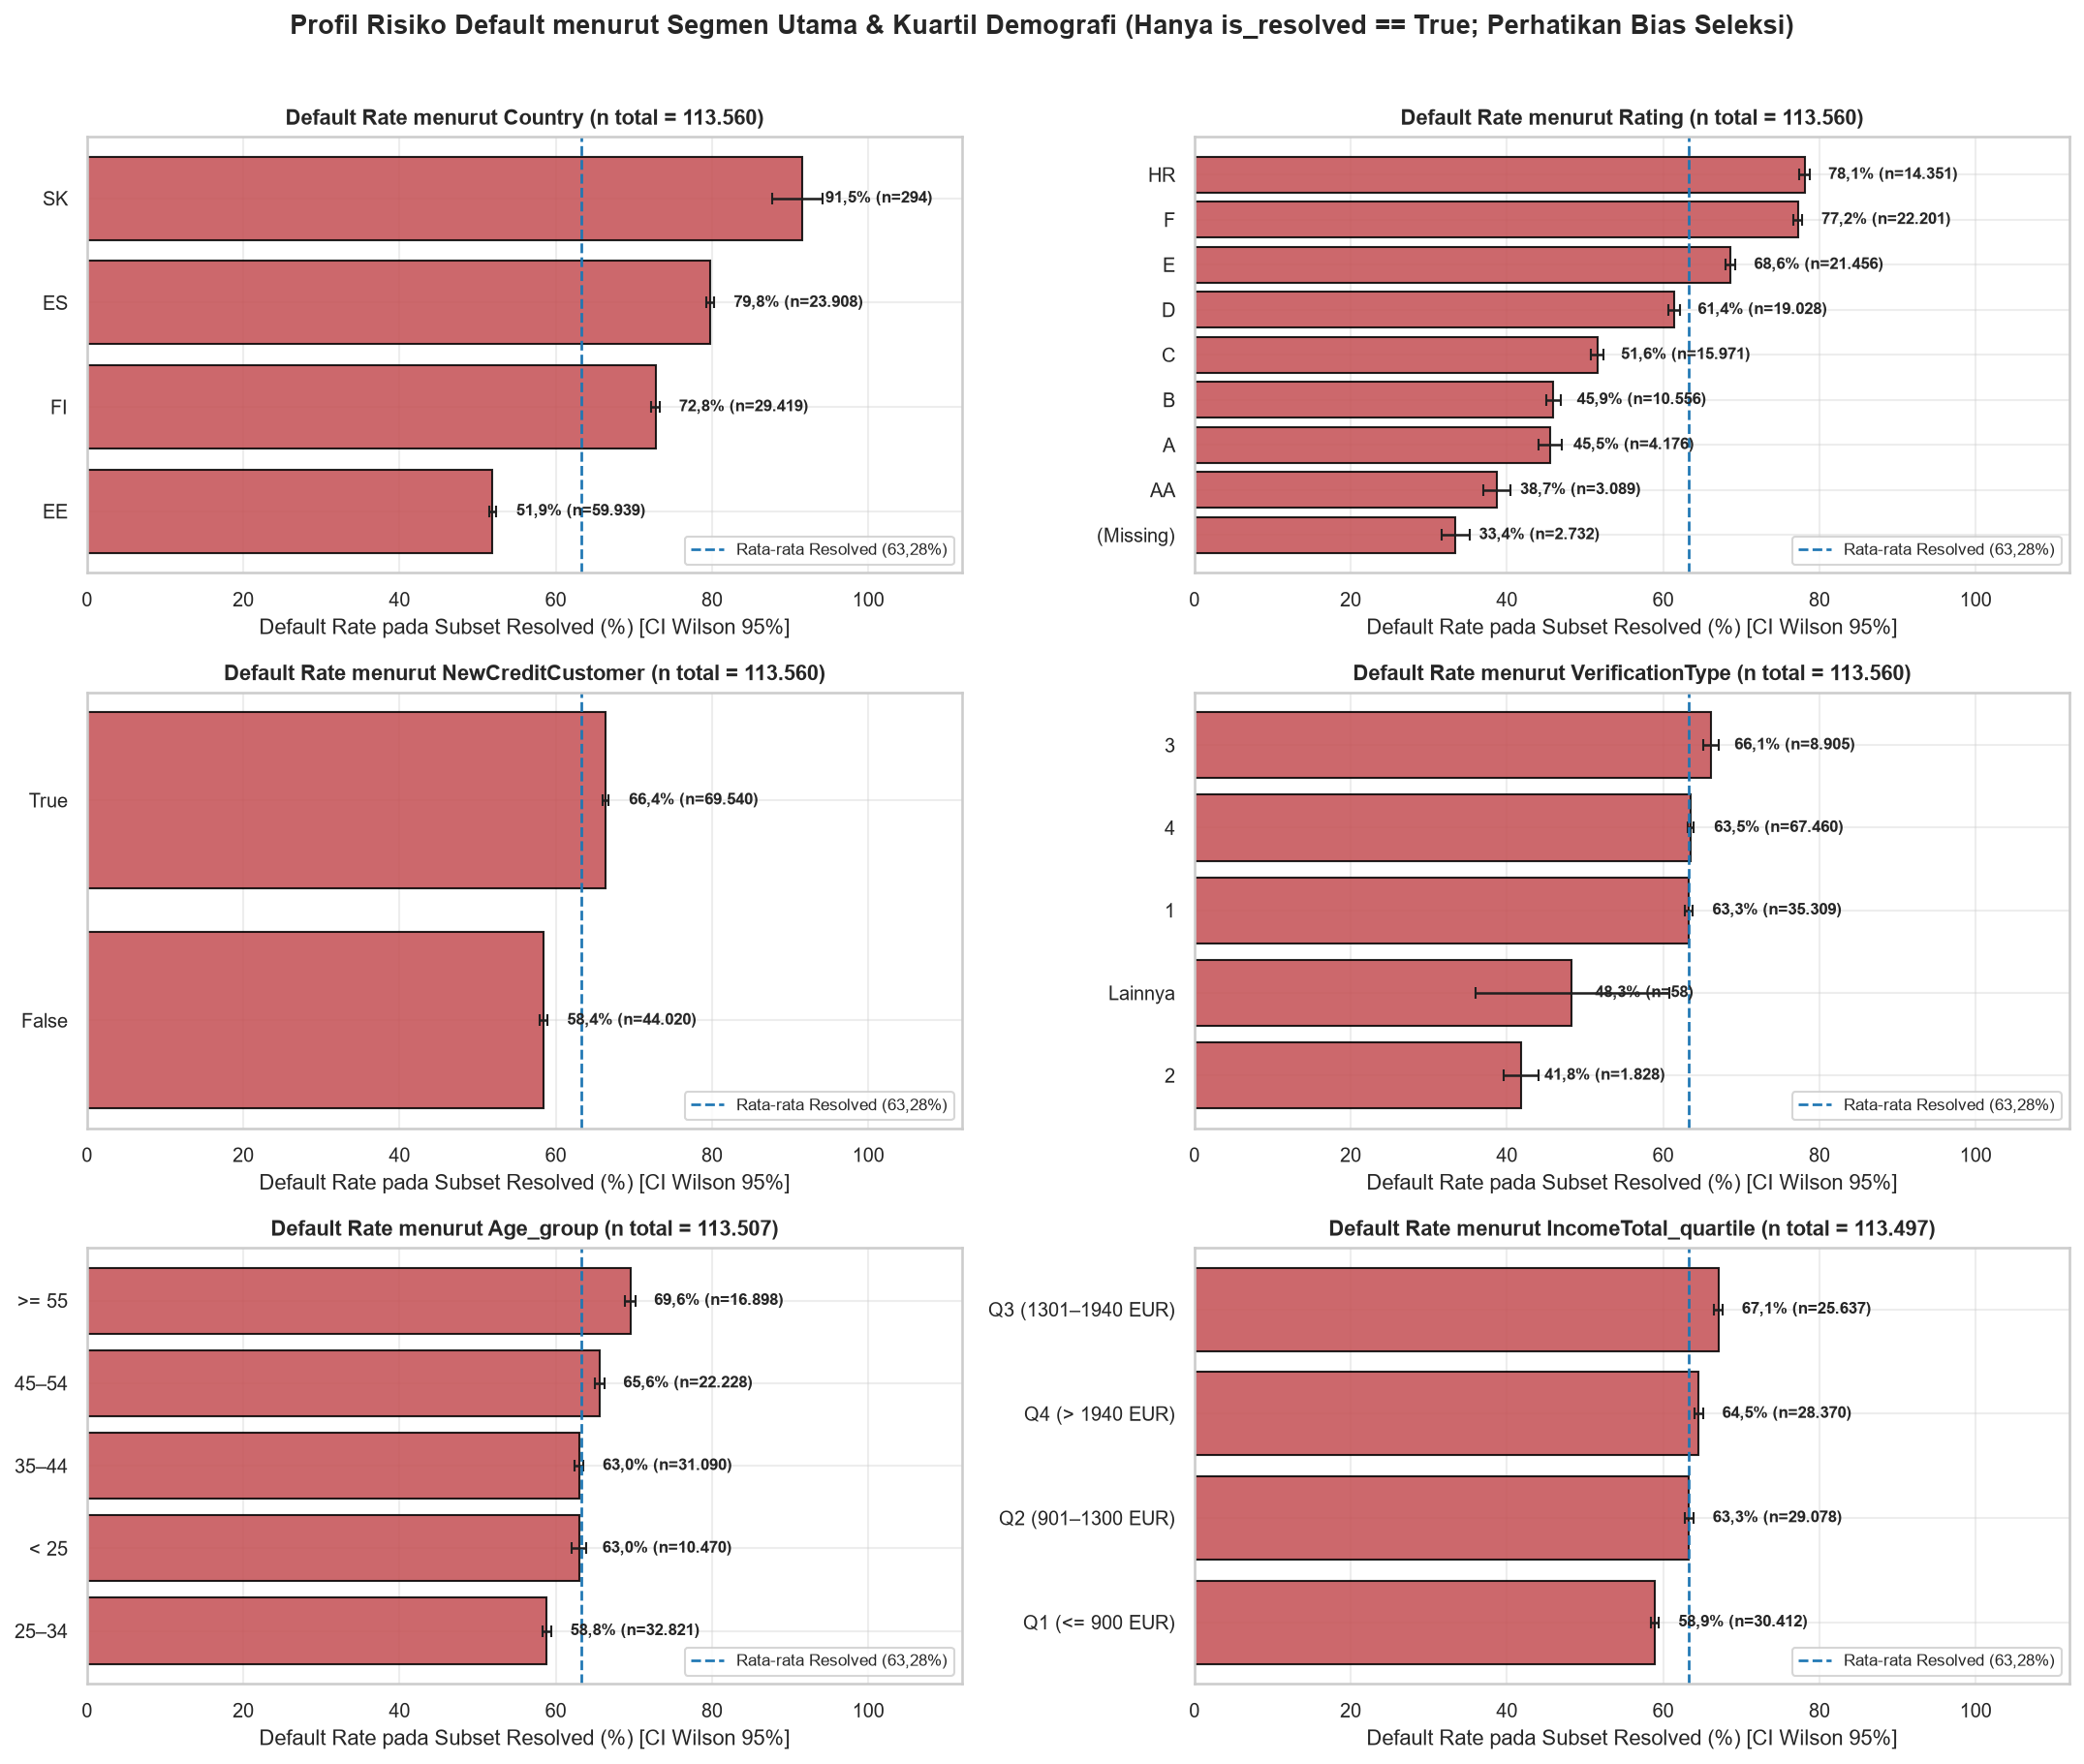

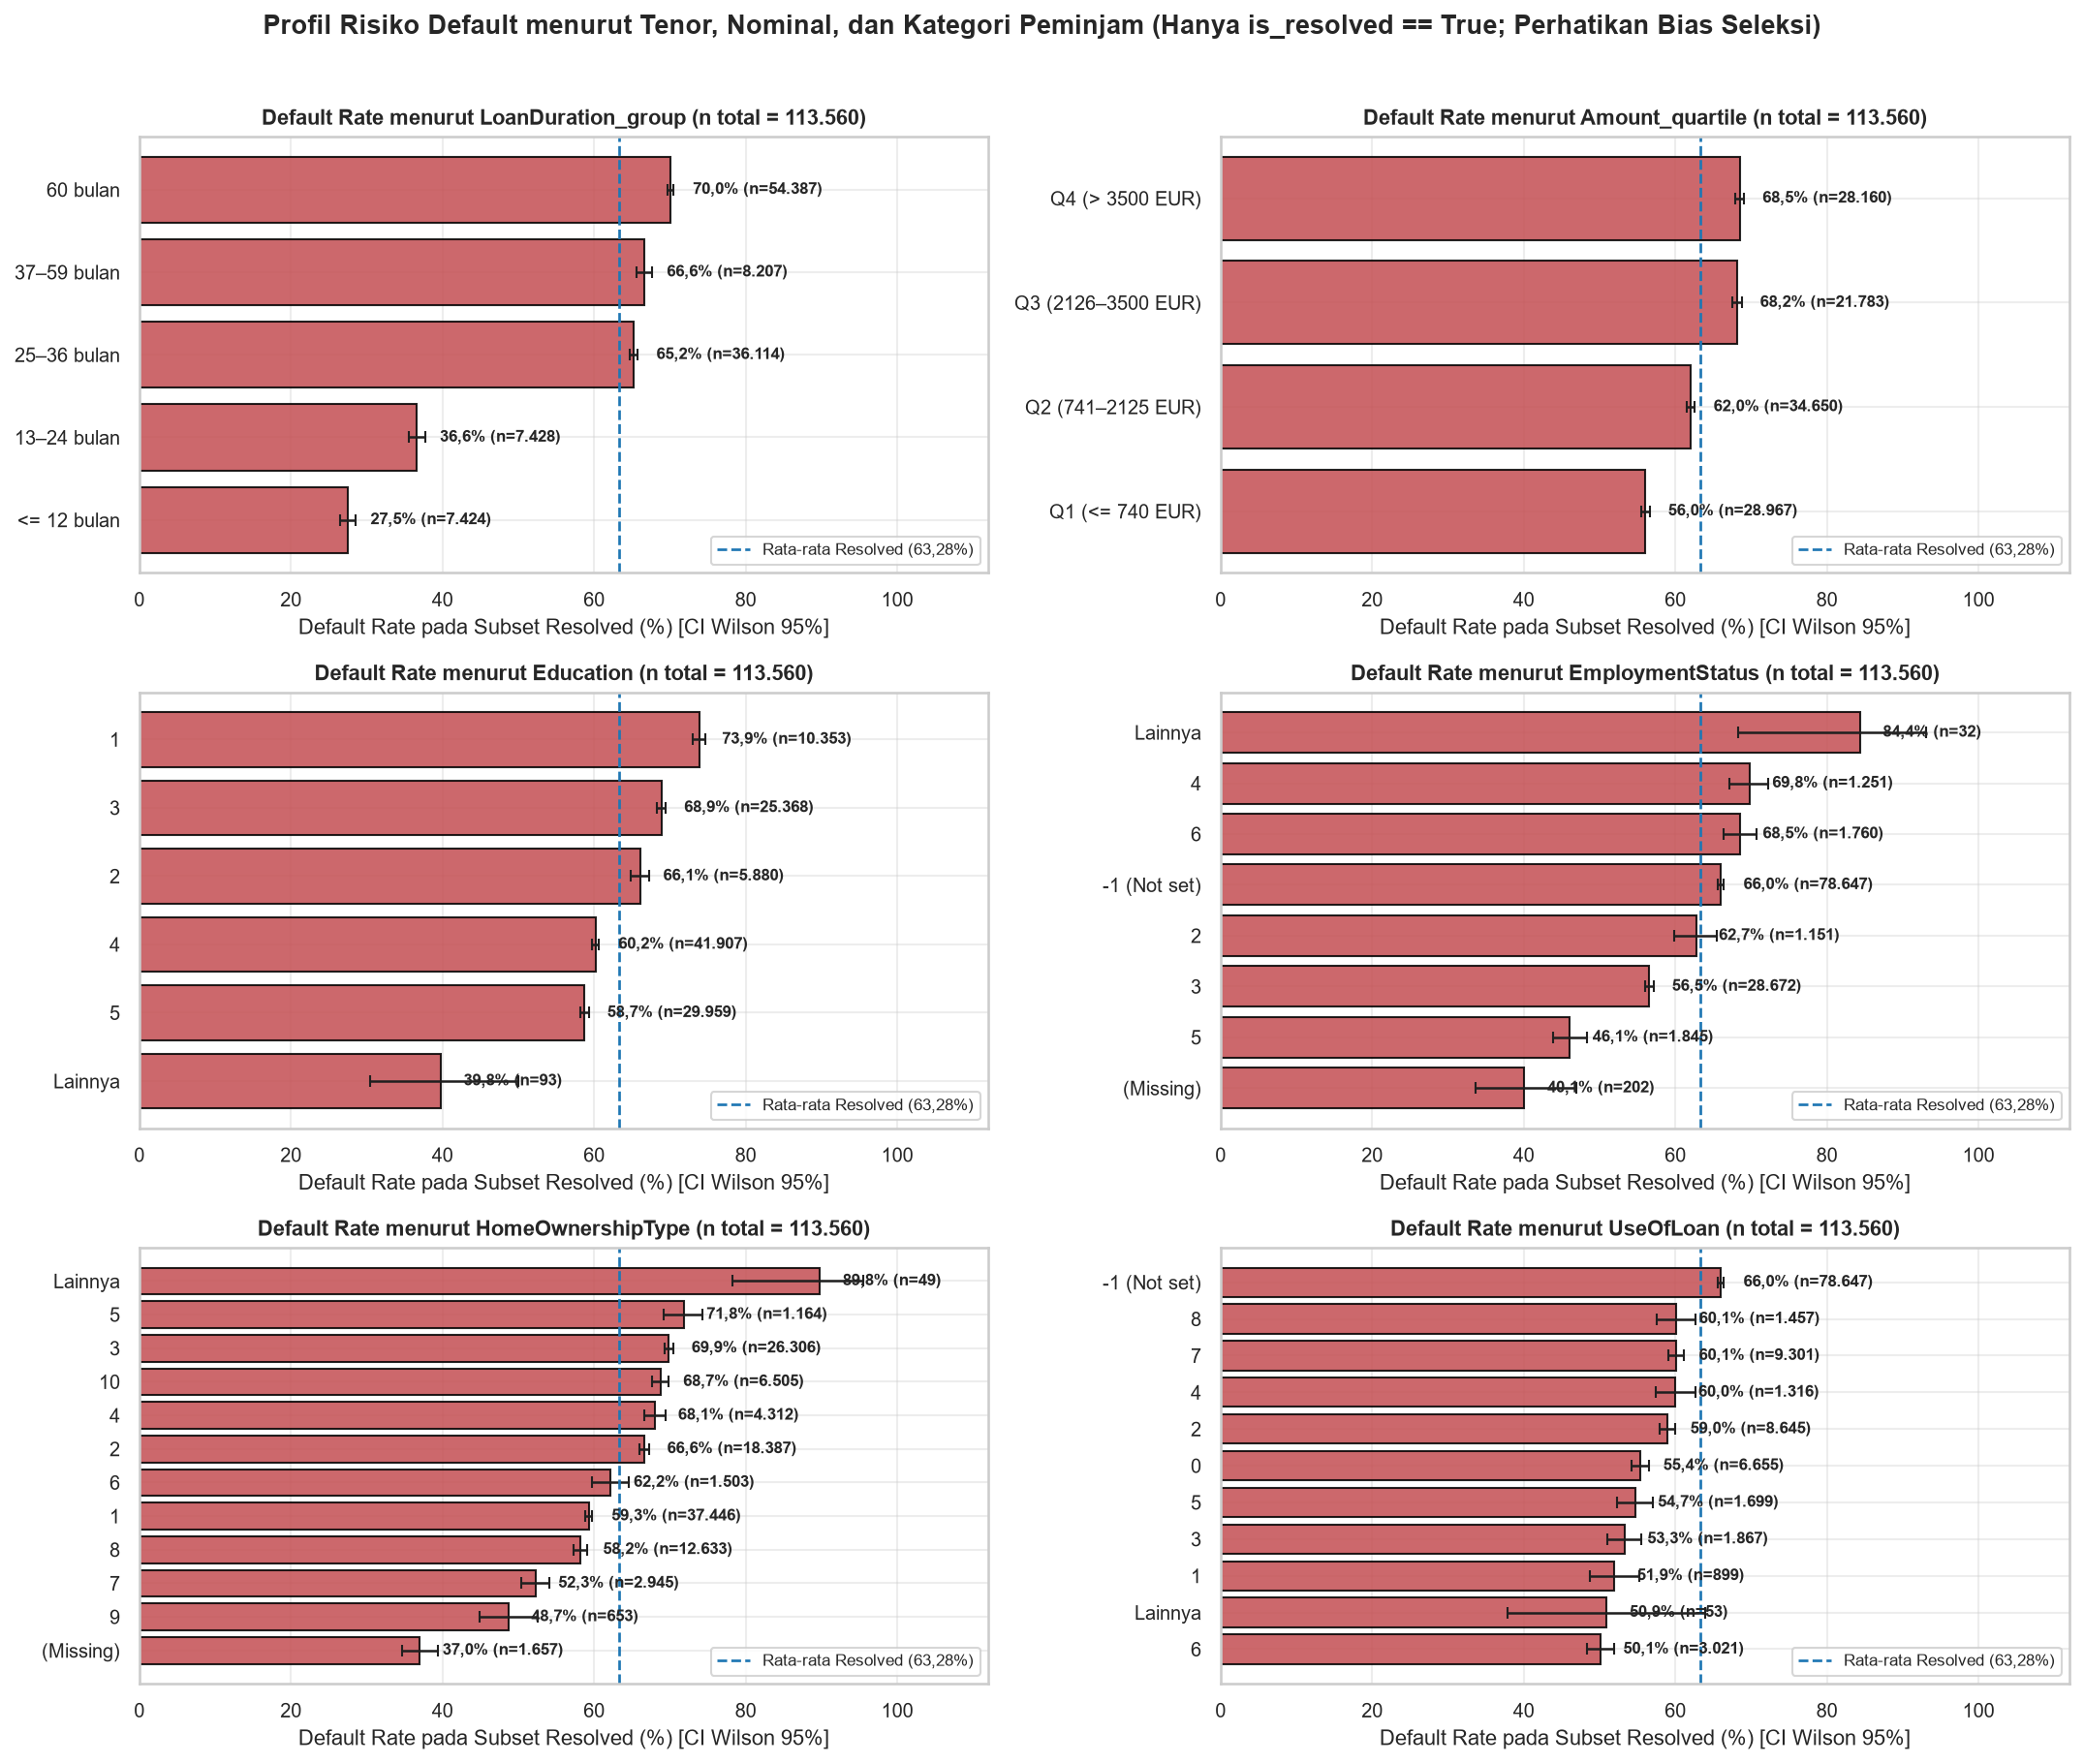

In [14]:
# Visualisasi Profil Risiko Default per Segmen dengan Interval Kepercayaan Wilson 95%
def _plot_segment_grid(var_list: list[str], fig_filename: str, suptitle: str) -> None:
    n_p = len(var_list)
    n_r = int(np.ceil(n_p / 2))
    fig, axes = plt.subplots(n_r, 2, figsize=(14.5, 4.0 * n_r))
    axes_f = axes.flatten()
    for idx_v, v_name in enumerate(var_list):
        ax = axes_f[idx_v]
        sub_s = all_seg_df.loc[all_seg_df['variabel'] == v_name].sort_values('default_rate', ascending=True).reset_index(drop=True)
        y_pos = np.arange(len(sub_s))
        rates_pct = sub_s['default_rate'].to_numpy() * 100.0
        ci_l_pct = sub_s['ci_low'].to_numpy() * 100.0
        ci_h_pct = sub_s['ci_high'].to_numpy() * 100.0
        xerr = np.vstack([rates_pct - ci_l_pct, ci_h_pct - rates_pct])

        bars = ax.barh(y_pos, rates_pct, xerr=xerr, capsize=3, color='#c44e52', edgecolor='black', alpha=0.85, error_kw={'elinewidth': 1.2, 'ecolor': '#1f1f1f'})
        ax.axvline(def_rate_res, color='#1f77b4', linestyle='--', linewidth=1.3, label=f'Rata-rata Resolved ({fmt_id(def_rate_res, 2)}%)')
        ax.set_yticks(y_pos)
        ax.set_yticklabels(sub_s['segmen'])
        ax.set_xlabel('Default Rate pada Subset Resolved (%) [CI Wilson 95%]')
        ax.set_title(f'Default Rate menurut {v_name} (n total = {fmt_id(int(sub_s["n"].sum()), is_int=True)})', fontsize=10.5)
        ax.set_xlim(0, 112)
        for bar, r_p, n_seg in zip(bars, rates_pct, sub_s['n']):
            ax.text(min(r_p + 3.0, 95.0), bar.get_y() + bar.get_height() / 2, f'{fmt_id(r_p, 1)}% (n={fmt_id(n_seg, is_int=True)})', va='center', fontsize=8.2, fontweight='bold')
        ax.legend(loc='lower right', fontsize=8)
    for j in range(len(var_list), len(axes_f)):
        axes_f[j].axis('off')
    fig.suptitle(suptitle, fontsize=13, fontweight='bold', y=1.01)
    fig.tight_layout()
    save_fig(fig, fig_filename, close=False)
    plt.show()
    plt.close(fig)

_plot_segment_grid(
    ['Country', 'Rating', 'NewCreditCustomer', 'VerificationType', 'Age_group', 'IncomeTotal_quartile'],
    '02_default_rate_utama.png',
    'Profil Risiko Default menurut Segmen Utama & Kuartil Demografi (Hanya is_resolved == True; Perhatikan Bias Seleksi)',
)
_plot_segment_grid(
    ['LoanDuration_group', 'Amount_quartile', 'Education', 'EmploymentStatus', 'HomeOwnershipType', 'UseOfLoan'],
    '02_default_rate_demografi_pinjaman.png',
    'Profil Risiko Default menurut Tenor, Nominal, dan Kategori Peminjam (Hanya is_resolved == True; Perhatikan Bias Seleksi)',
)

,Rating,n,n_default,observed_default_rate,mean_bondora_pd,median_bondora_pd,ci_low,ci_high
0,AA,3089,1195,0.386857,0.063553,0.030901,0.369832,0.404162
1,A,4176,1900,0.454981,0.090176,0.068369,0.439926,0.470119
2,B,10556,4850,0.459454,0.120920,0.101129,0.449964,0.468974
3,C,15971,8237,0.515747,0.161373,0.148520,0.507994,0.523493
4,D,19028,11686,0.614148,0.208962,0.202705,0.607208,0.621041
5,E,21456,14723,0.686195,0.268525,0.269451,0.679953,0.692370
6,F,22201,17148,0.772398,0.358483,0.354750,0.766835,0.777866
7,HR,14351,11212,0.78127,0.499398,0.464800,0.774431,0.787957


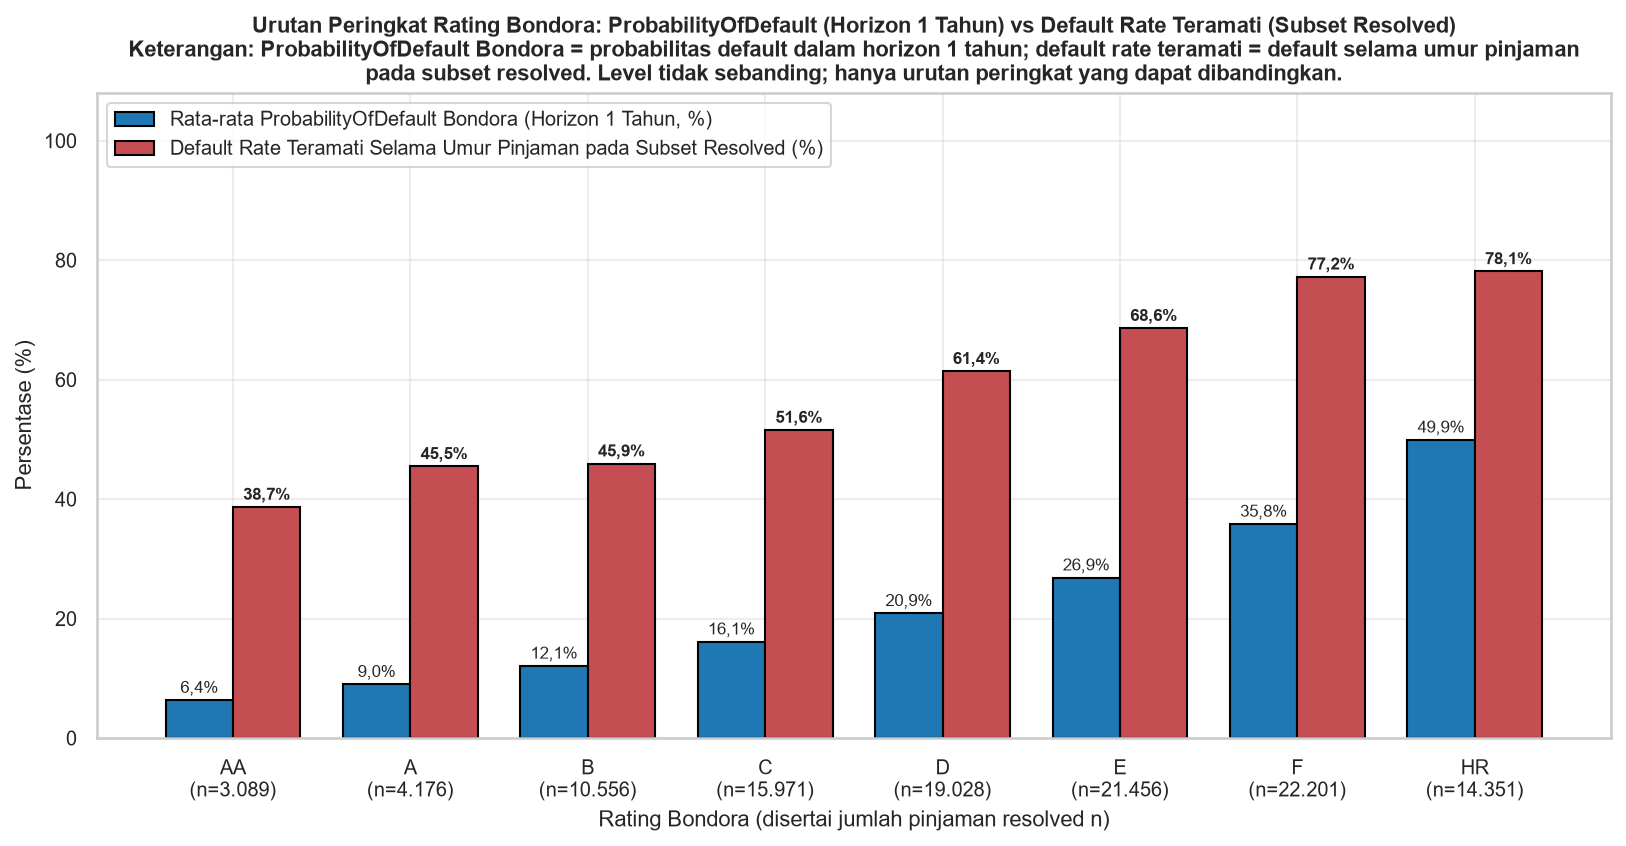

In [15]:
# Pembanding Bondora: Urutan Peringkat ProbabilityOfDefault (Horizon 1 Tahun) vs Default Rate Teramati (Umur Pinjaman pada Subset Resolved)
rating_order = ['AA', 'A', 'B', 'C', 'D', 'E', 'F', 'HR']
df_res_rat = df_resolved.loc[df_resolved['Rating'].isin(rating_order)].copy()
rat_comp = (
    df_res_rat.groupby('Rating', observed=True)
    .agg(
        n=('default', 'count'),
        n_default=('default', 'sum'),
        observed_default_rate=('default', 'mean'),
        mean_bondora_pd=('ProbabilityOfDefault', 'mean'),
        median_bondora_pd=('ProbabilityOfDefault', 'median'),
    )
    .reindex(rating_order)
    .reset_index()
)
ci_l_r, ci_h_r = wilson_ci(rat_comp['n_default'].to_numpy(), rat_comp['n'].to_numpy())
rat_comp['ci_low'] = ci_l_r
rat_comp['ci_high'] = ci_h_r
display(rat_comp)

fig, ax = plt.subplots(figsize=(11.0, 5.8))
x_idx = np.arange(len(rat_comp))
width = 0.38
obs_pct = rat_comp['observed_default_rate'].to_numpy() * 100.0
pd_pct = rat_comp['mean_bondora_pd'].to_numpy() * 100.0
b1 = ax.bar(x_idx - width / 2, pd_pct, width, label='Rata-rata ProbabilityOfDefault Bondora (Horizon 1 Tahun, %)', color='#1f77b4', edgecolor='black')
b2 = ax.bar(x_idx + width / 2, obs_pct, width, label='Default Rate Teramati Selama Umur Pinjaman pada Subset Resolved (%)', color='#c44e52', edgecolor='black')
ax.set_xticks(x_idx)
ax.set_xticklabels([f'{r}\n(n={fmt_id(n_v, is_int=True)})' for r, n_v in zip(rat_comp['Rating'], rat_comp['n'])])
ax.set_ylabel('Persentase (%)')
ax.set_xlabel('Rating Bondora (disertai jumlah pinjaman resolved n)')
ax.set_ylim(0, 108)
ax.set_title(
    'Urutan Peringkat Rating Bondora: ProbabilityOfDefault (Horizon 1 Tahun) vs Default Rate Teramati (Subset Resolved)\n'
    'Keterangan: ProbabilityOfDefault Bondora = probabilitas default dalam horizon 1 tahun; default rate teramati = default selama umur pinjaman\n'
    'pada subset resolved. Level tidak sebanding; hanya urutan peringkat yang dapat dibandingkan.',
    fontsize=10.5,
)
for bar in b1:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.2, f'{fmt_id(bar.get_height(), 1)}%', ha='center', fontsize=8)
for bar in b2:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.2, f'{fmt_id(bar.get_height(), 1)}%', ha='center', fontsize=8, fontweight='bold')
ax.legend(loc='upper left')
fig.tight_layout()
save_fig(fig, '02_rating_pd_vs_observed.png', close=False)
plt.show()
plt.close(fig)

### Ringkasan Observasi Bagian E (Profil Risiko Deskriptif)
- **Perbedaan Risiko antar Negara (`Country`, `02_default_rate_utama.png`):** Pada subset *resolved* (`n = 113.560`), proporsi default terendah tercatat di Estonia (**EE**: **51,92%**, `n = 59.939`, CI 95%: `51,52%–52,32%`, berbobot `Amount`: **56,92%**). Proporsi default lebih tinggi tercatat di Finlandia (**FI**: **72,76%**, `n = 29.419`, CI 95%: `72,25%–73,26%`) dan Spanyol (**ES**: **79,77%**, `n = 23.908`, CI 95%: `79,25%–80,27%`). Segmen Slovakia (**SK**) memiliki proporsi default tertinggi yaitu **91,50%** (`269 / 294`, CI 95%: `87,75%–94,17%`), namun ukuran sampelnya jauh lebih kecil (`n = 294`) dibandingkan tiga negara utama.
- **Urutan Peringkat Risiko Bondora (`Rating`, `02_rating_pd_vs_observed.png`):** `ProbabilityOfDefault` Bondora merupakan probabilitas default dalam **horizon 1 tahun**, sedangkan default rate teramati merupakan proporsi default **selama umur pinjaman pada subset `is_resolved == True`**. Oleh karena itu, **level keduanya tidak sebanding; hanya urutan peringkat yang dapat dibandingkan**. Secara ordinal, keduanya sama-sama meningkat secara monoton dari peringkat terbaik ke terendah: rata-rata `ProbabilityOfDefault` Bondora naik dari **6,36%** (`AA`) hingga **49,94%** (`HR`), dan default rate teramati pada subset *resolved* naik monoton dari **AA** (**38,69%**, `n = 3.089`), **A** (**45,50%**, `n = 4.176`), **B** (**45,95%**, `n = 10.556`), **C** (**51,57%**, `n = 15.971`), **D** (**61,41%**, `n = 19.028`), **E** (**68,62%**, `n = 21.456`), **F** (**77,24%**, `n = 22.201`), hingga **HR** (**78,13%**, `n = 14.351`).
- **Status Pelanggan & Kelompok Tenor 5 Kategori (`NewCreditCustomer`, `LoanDuration_group`):** Pelanggan kredit baru (`NewCreditCustomer == True`) mencatat default rate pada subset *resolved* sebesar **66,35%** (`n = 69.540`), lebih tinggi dibandingkan pelanggan lama (`NewCreditCustomer == False`) sebesar **58,44%** (`n = 44.020`). Berdasarkan 5 kelompok tenor (`LoanDuration_group`, seluruhnya memiliki `n >= 7.424 >= 200`), default rate pada subset *resolved* meningkat seiring panjangnya tenor: `<= 12 bulan` sebesar **27,49%** (`n = 7.424`, berbobot `Amount` **33,06%**), `13–24 bulan` sebesar **36,65%** (`n = 7.428`, berbobot **40,15%**), `25–36 bulan` sebesar **65,21%** (`n = 36.114`, berbobot **66,48%**), `37–59 bulan` sebesar **66,59%** (`n = 8.207`, berbobot **67,25%**), dan `60 bulan` sebesar **70,03%** (`n = 54.387`, berbobot **70,76%**). Sebagaimana dijelaskan pada **Catatan Bias Seleksi**, pinjaman lancar bertenor panjang (37–59 dan 60 bulan) atau milik pelanggan baru banyak yang masih berstatus `Current` (misalnya pada tenor 60 bulan hanya **57,08%** dari `95.287` pinjaman yang sudah *resolved*), sehingga angka pada subset *resolved* cenderung melebih-lebihkan tingkat default sebenarnya.
- **Umur, Pendapatan, dan Nominal (`Age_group`, `IncomeTotal_quartile`, `Amount_quartile`):** Kelompok umur `25–34 tahun` mencatat default rate terendah (**58,85%**, `n = 32.821`), sedangkan kelompok `>= 55 tahun` mencatat default rate tertinggi (**69,58%**, `n = 16.898`). Berdasarkan kuartil `Amount`, proporsi default meningkat dari **56,03%** pada `Q1 (<= 740 EUR)` (`n = 28.967`) menjadi **68,49%** pada `Q4 (> 3.500 EUR)` (`n = 28.160`). Catatan kehati-hatian: segmen gabungan `Lainnya` dengan `n < 200` (seperti pada `EmploymentStatus` dengan `n = 32`, `HomeOwnershipType` dengan `n = 49`, `UseOfLoan` dengan `n = 53`, `VerificationType` dengan `n = 58`, dan `Education` dengan `n = 93`) memiliki interval kepercayaan yang lebar dan kurang andal.

## Bagian F — Pengembalian dan Pemulihan (`02_return_ratio_summary.csv`)

Bagian ini menganalisis distribusi `return_ratio` serta pemulihan pokok (`PrincipalRecovery`) pada subset pinjaman selesai (`is_resolved == True`, `n = 113.560`).

> **Catatan Penting:** Untuk pinjaman default yang masih berstatus `Late` pada tanggal laporan (`2021-07-20`), nilai `return_ratio` merepresentasikan **pengembalian kumulatif sampai tanggal laporan (batas bawah / *lower bound*)**, karena proses penagihan (*collection/recovery*) masih dapat berlanjut setelah tanggal laporan.

In [16]:
def _summarize_return_ratio_by(df_in: pd.DataFrame, grp_col: str) -> pd.DataFrame:
    rows_rr = []
    for g_val, g_df in df_in.groupby(grp_col, observed=True, dropna=False):
        s_rr = pd.to_numeric(g_df['return_ratio'], errors='coerce').dropna()
        n_g = len(s_rr)
        if n_g == 0:
            continue
        q_rr = s_rr.quantile([0.05, 0.25, 0.50, 0.75, 0.95])
        pct_zero = float((s_rr == 0).mean() * 100.0)
        w_stats = weighted_return_ratio(g_df)
        rows_rr.append({
            'dimensi': grp_col,
            'segmen': str(g_val) if pd.notna(g_val) else '(Missing)',
            'n': n_g,
            'mean': round(float(s_rr.mean()), 4),
            'weighted_return_ratio': round(float(w_stats['weighted_return_ratio']), 4),
            'std': round(float(s_rr.std(ddof=1)), 4) if n_g > 1 else 0.0,
            'p05': round(float(q_rr.loc[0.05]), 4),
            'p25': round(float(q_rr.loc[0.25]), 4),
            'median': round(float(q_rr.loc[0.50]), 4),
            'p75': round(float(q_rr.loc[0.75]), 4),
            'p95': round(float(q_rr.loc[0.95]), 4),
            'pct_zero': round(pct_zero, 4),
        })
    return pd.DataFrame(rows_rr)

rr_sum_df = pd.concat([
    _summarize_return_ratio_by(df_resolved, 'outcome_group'),
    _summarize_return_ratio_by(df_resolved, 'Country'),
    _summarize_return_ratio_by(df_resolved, 'Rating'),
    _summarize_return_ratio_by(df_resolved, 'loan_year'),
], ignore_index=True)
rr_sum_df.to_csv(TABLES_DIR / '02_return_ratio_summary.csv', index=False)
display(rr_sum_df)

,dimensi,segmen,n,mean,weighted_return_ratio,std,p05,p25,median,p75,p95,pct_zero
0,outcome_group,Default,71864,0.4755,0.4437,0.4413,0.0000,0.1377,0.3498,0.7258,1.3244,6.8059
1,outcome_group,Lunas tanpa default,41696,1.2400,1.2568,0.2614,1.0069,1.0644,1.1637,1.3218,1.7591,0.0072
2,Country,EE,59939,0.8843,0.8359,0.4836,0.0718,0.4541,1.0276,1.1984,1.5861,1.6383
3,Country,ES,23908,0.5778,0.5362,0.5964,0.0000,0.0812,0.3597,1.0376,1.6490,12.0169
4,Country,FI,29419,0.6433,0.6328,0.5057,0.0136,0.1950,0.4923,1.0681,1.4739,3.3754
5,Country,SK,294,0.4554,0.4039,0.5072,0.0000,0.0392,0.2173,0.7727,1.4306,15.6463
6,Rating,A,4176,0.8701,0.8952,0.4344,0.1107,0.4735,1.0410,1.1740,1.4568,0.5268
7,Rating,AA,3089,0.8435,0.7773,0.3981,0.1175,0.4916,1.0333,1.1094,1.2406,0.3885
8,Rating,B,10556,0.8740,0.8868,0.4301,0.1096,0.4876,1.0304,1.1732,1.4346,0.8052
9,Rating,C,15971,0.8575,0.8251,0.4742,0.0672,0.4128,1.0182,1.1861,1.5310,1.7093


Total pinjaman default (n)                       : 71864
Pinjaman default dengan PrincipalRecovery > 0    : 39533 (55.01%)
Pinjaman default dengan PrincipalRecovery == 0   : 32331 (44.99%)
Rasio PrincipalRecovery / Amount (seluruh default): mean = 0.1675, median = 0.0156
Rasio PrincipalRecovery / Amount (hanya > 0)      : mean = 0.3045, median = 0.1735, p25 = 0.0514, p75 = 0.5554


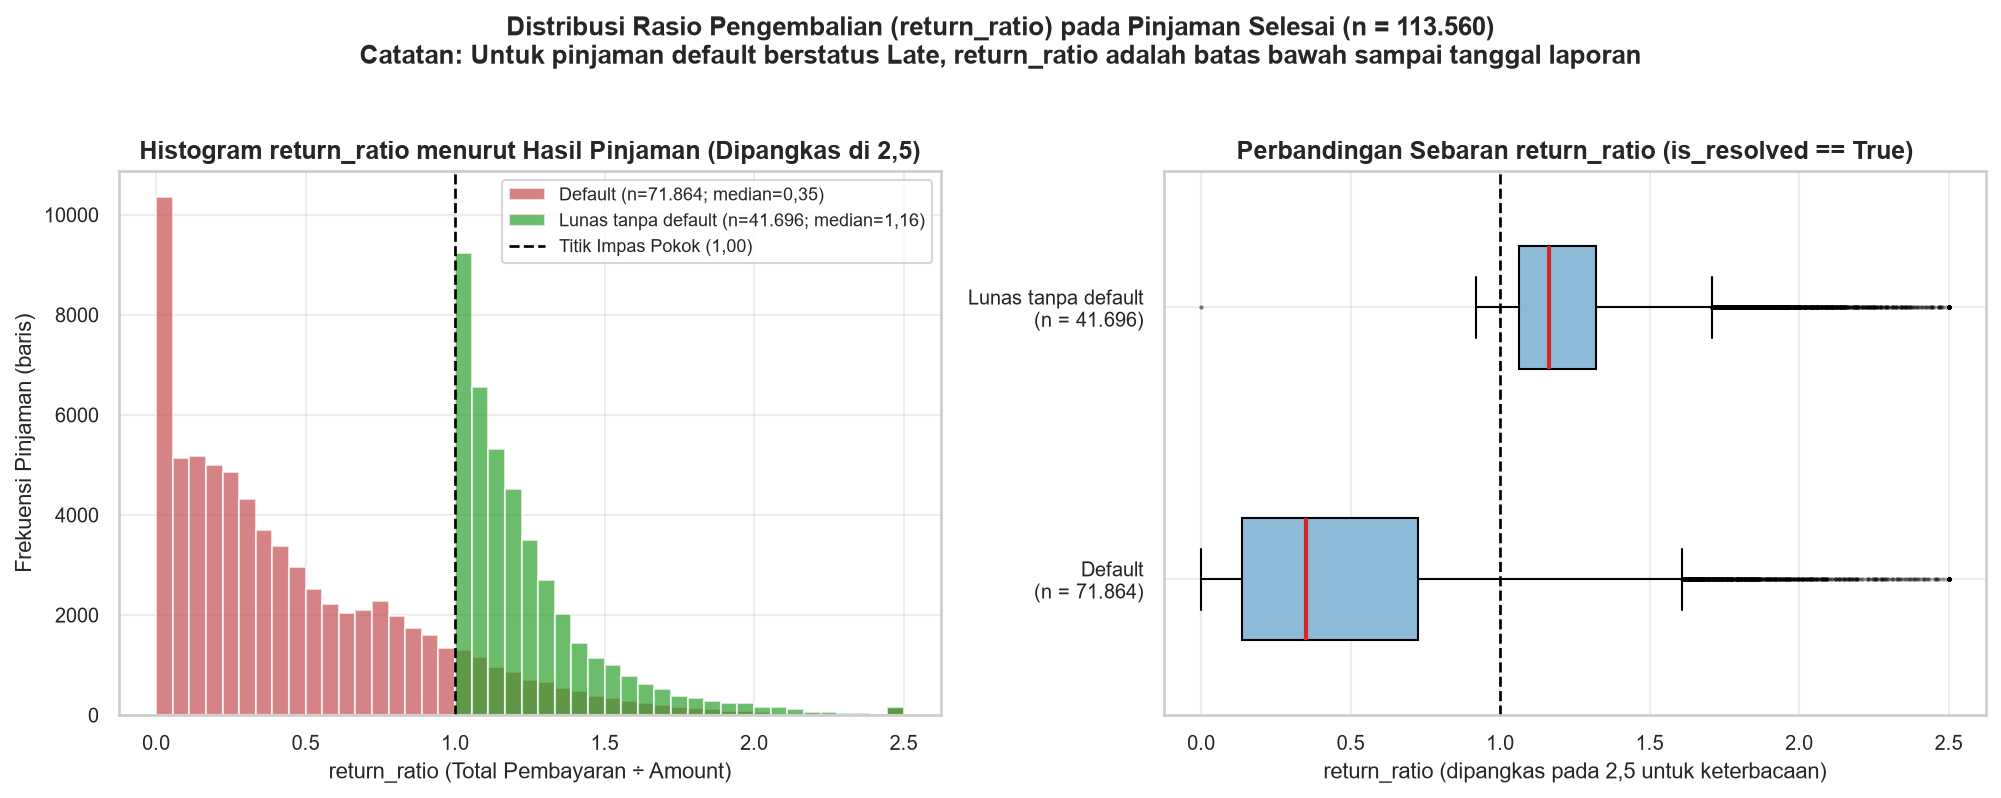

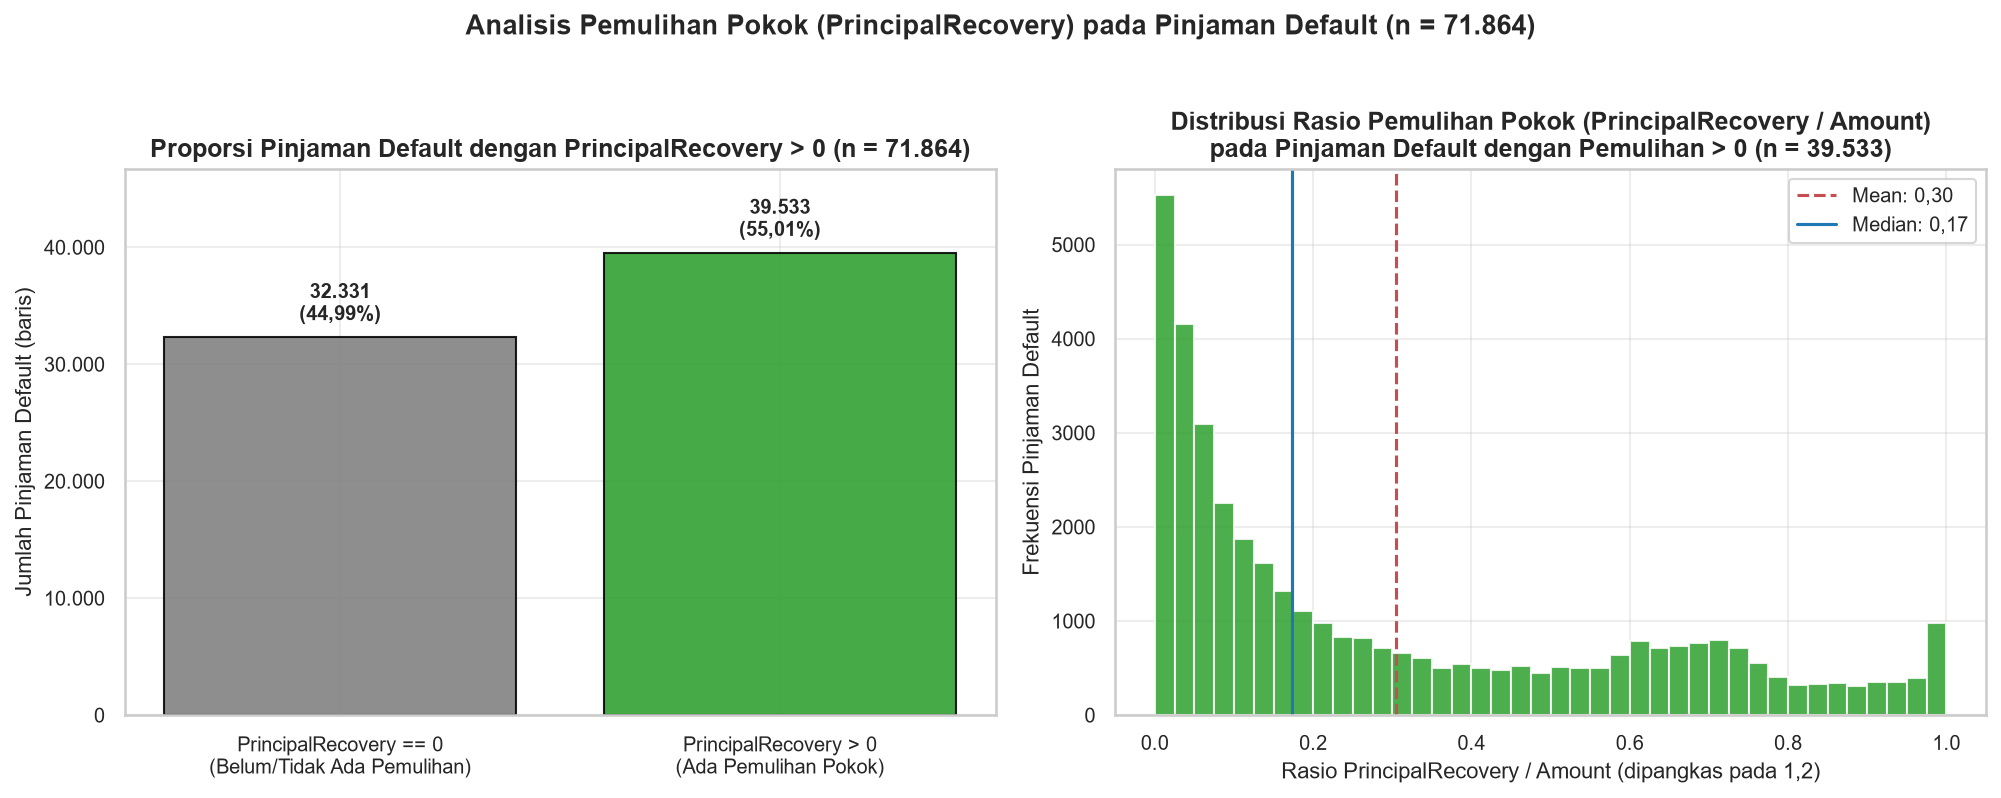

In [17]:
# 1. Distribusi return_ratio menurut Default vs Lunas tanpa default -> 02_return_ratio_by_outcome.png
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))
rr_def = df_resolved.loc[df_resolved['default'] == 1, 'return_ratio'].dropna()
rr_rep = df_resolved.loc[df_resolved['default'] == 0, 'return_ratio'].dropna()

axes[0].hist(rr_def.clip(upper=2.5), bins=45, alpha=0.70, color=OUTCOME_PALETTE['Default'], edgecolor='white', label=f'Default (n={fmt_id(len(rr_def), is_int=True)}; median={fmt_id(rr_def.median(), 2)})')
axes[0].hist(rr_rep.clip(upper=2.5), bins=45, alpha=0.70, color=OUTCOME_PALETTE['Lunas tanpa default'], edgecolor='white', label=f'Lunas tanpa default (n={fmt_id(len(rr_rep), is_int=True)}; median={fmt_id(rr_rep.median(), 2)})')
axes[0].axvline(1.0, color='black', linestyle='--', linewidth=1.3, label='Titik Impas Pokok (1,00)')
axes[0].set_title('Histogram return_ratio menurut Hasil Pinjaman (Dipangkas di 2,5)')
axes[0].set_xlabel('return_ratio (Total Pembayaran ÷ Amount)')
axes[0].set_ylabel('Frekuensi Pinjaman (baris)')
axes[0].legend(fontsize=8.5)

axes[1].boxplot(
    [rr_def.clip(upper=2.5), rr_rep.clip(upper=2.5)],
    tick_labels=['Default\n(n = 71.864)', 'Lunas tanpa default\n(n = 41.696)'],
    orientation='horizontal', widths=0.45, patch_artist=True,
    boxprops={'facecolor': '#8ebad9', 'edgecolor': 'black'},
    medianprops={'color': '#d62728', 'linewidth': 2},
    flierprops={'marker': '.', 'markersize': 2, 'alpha': 0.2},
)
axes[1].axvline(1.0, color='black', linestyle='--', linewidth=1.3)
axes[1].set_title('Perbandingan Sebaran return_ratio (is_resolved == True)')
axes[1].set_xlabel('return_ratio (dipangkas pada 2,5 untuk keterbacaan)')

fig.suptitle(
    'Distribusi Rasio Pengembalian (return_ratio) pada Pinjaman Selesai (n = 113.560)\n'
    'Catatan: Untuk pinjaman default berstatus Late, return_ratio adalah batas bawah sampai tanggal laporan',
    fontsize=12.5, fontweight='bold', y=1.02,
)
fig.tight_layout()
save_fig(fig, '02_return_ratio_by_outcome.png', close=False)
plt.show()
plt.close(fig)

# 3. Analisis Pemulihan Pokok (PrincipalRecovery) pada Pinjaman Default -> 02_principal_recovery_distribution.png
df_def_only = df_resolved.loc[df_resolved['default'] == 1].copy()
n_def_total = len(df_def_only)
prec = pd.to_numeric(df_def_only['PrincipalRecovery'], errors='coerce').fillna(0.0)
amt_d = pd.to_numeric(df_def_only['Amount'], errors='coerce')
n_has_rec = int((prec > 0).sum())
pct_has_rec = n_has_rec / n_def_total * 100.0
rec_ratio = np.where(amt_d.notna() & (amt_d > 0), prec / amt_d, np.nan)
s_rec_ratio = pd.Series(rec_ratio, index=df_def_only.index).dropna()
s_rec_pos = s_rec_ratio.loc[prec > 0]

print(f'Total pinjaman default (n)                       : {n_def_total}')
print(f'Pinjaman default dengan PrincipalRecovery > 0    : {n_has_rec} ({pct_has_rec:.2f}%)')
print(f'Pinjaman default dengan PrincipalRecovery == 0   : {n_def_total - n_has_rec} ({100 - pct_has_rec:.2f}%)')
print(f'Rasio PrincipalRecovery / Amount (seluruh default): mean = {s_rec_ratio.mean():.4f}, median = {s_rec_ratio.median():.4f}')
print(f'Rasio PrincipalRecovery / Amount (hanya > 0)      : mean = {s_rec_pos.mean():.4f}, median = {s_rec_pos.median():.4f}, p25 = {s_rec_pos.quantile(0.25):.4f}, p75 = {s_rec_pos.quantile(0.75):.4f}')

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))
axes[0].bar(
    ['PrincipalRecovery == 0\n(Belum/Tidak Ada Pemulihan)', 'PrincipalRecovery > 0\n(Ada Pemulihan Pokok)'],
    [n_def_total - n_has_rec, n_has_rec],
    color=['#7f7f7f', '#2ca02c'], edgecolor='black', alpha=0.88,
)
axes[0].set_title(f'Proporsi Pinjaman Default dengan PrincipalRecovery > 0 (n = {fmt_id(n_def_total, is_int=True)})')
axes[0].set_ylabel('Jumlah Pinjaman Default (baris)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: fmt_id(x, is_int=True)))
axes[0].set_ylim(0, max(n_def_total - n_has_rec, n_has_rec) * 1.18)
for idx_b, (cnt_b, pct_b) in enumerate([(n_def_total - n_has_rec, 100 - pct_has_rec), (n_has_rec, pct_has_rec)]):
    axes[0].text(idx_b, cnt_b + n_def_total * 0.02, f'{fmt_id(cnt_b, is_int=True)}\n({fmt_id(pct_b, 2)}%)', ha='center', fontsize=9.5, fontweight='bold')

axes[1].hist(s_rec_pos.clip(upper=1.2), bins=40, color='#2ca02c', edgecolor='white', alpha=0.85)
axes[1].axvline(s_rec_pos.mean(), color='#c44e52', linestyle='--', linewidth=1.5, label=f'Mean: {fmt_id(s_rec_pos.mean(), 2)}')
axes[1].axvline(s_rec_pos.median(), color='#1f77b4', linestyle='-', linewidth=1.5, label=f'Median: {fmt_id(s_rec_pos.median(), 2)}')
axes[1].set_title(f'Distribusi Rasio Pemulihan Pokok (PrincipalRecovery / Amount)\npada Pinjaman Default dengan Pemulihan > 0 (n = {fmt_id(len(s_rec_pos), is_int=True)})')
axes[1].set_xlabel('Rasio PrincipalRecovery / Amount (dipangkas pada 1,2)')
axes[1].set_ylabel('Frekuensi Pinjaman Default')
axes[1].legend()

fig.suptitle('Analisis Pemulihan Pokok (PrincipalRecovery) pada Pinjaman Default (n = 71.864)', fontsize=13, fontweight='bold', y=1.02)
fig.tight_layout()
save_fig(fig, '02_principal_recovery_distribution.png', close=False)
plt.show()
plt.close(fig)

### Ringkasan Observasi Bagian F (Pengembalian dan Pemulihan)
- **Kontras `return_ratio` menurut Hasil Pinjaman (`02_return_ratio_summary.csv`, `02_return_ratio_by_outcome.png`):** Pinjaman dalam kelompok `Lunas tanpa default` (`n = 41.696`) mencatat rata-rata sederhana `return_ratio` sebesar **1,2400** (berbobot `Amount`: **1,2568**, median **1,1637**, `p25 = 1,0644`, `p75 = 1,3218`). Sebaliknya, pinjaman `Default` (`n = 71.864`) mencatat rata-rata sederhana `return_ratio` sebesar **0,4755** (berbobot `Amount`: **0,4437**, median **0,3498**, `p25 = 0,1377`, `p75 = 0,7258`), dengan **6,81%** di antaranya memiliki `return_ratio == 0` (belum ada pembayaran sama sekali hingga tanggal laporan).
- **Variasi Pengembalian menurut Negara, Peringkat, dan Tahun (`02_return_ratio_summary.csv`):** Berdasarkan negara (`is_resolved == True`), `EE` mencatat rata-rata `return_ratio` tertinggi sebesar **0,8843** (berbobot `Amount`: **0,8359**, median **1,0276**), diikuti `FI` (**0,6433**, berbobot **0,6328**), `ES` (**0,5778**, berbobot **0,5362**, dengan `pct_zero = 12,02%`), dan `SK` (**0,4554**, `n = 294`). Berdasarkan tahun pencairan, kohort matang 2009–2013 yang hampir seluruhnya selesai mencatat rata-rata `return_ratio` di atas **1,16** (puncak **1,2909** pada 2013), sedangkan kohort 2018–2020 mencatat `return_ratio` lebih rendah (**0,5711–0,7517**) karena pinjaman yang sudah selesai lebih cepat di kohort baru didominasi oleh pinjaman yang sudah mengalami default dan masih dalam proses penagihan.
- **Pemulihan Pokok pada Pinjaman Default (`02_principal_recovery_distribution.png`):** Dari **71.864** pinjaman default, tercatat **39.533** pinjaman (**55,01%**) memiliki `PrincipalRecovery > 0` hingga tanggal laporan (`2021-07-20`), sedangkan **32.331** pinjaman (**44,99%**) memiliki `PrincipalRecovery == 0`. Pada seluruh pinjaman default (`n = 71.864`), rata-rata proporsi pokok yang dipulihkan (`PrincipalRecovery / Amount`) adalah **16,75%** (median **1,56%**); apabila dihitung khusus pada pinjaman default yang sudah memiliki pemulihan (`n = 39.533`), rata-ratanya mencapai **30,45%** (median **17,35%**, `p25 = 5,11%`, `p75 = 48,96%`).

## Ringkasan Temuan Descriptive

Berikut adalah **11 temuan utama** dari analisis deskriptif Tahap 2 beserta rujukan tabel dan grafik:

### 1. Profil Portofolio
1. **Skala Portofolio dan Peminjam Berulang (`02_kpi_portofolio.csv`):** Portofolio Bondora mencakup **179.235** pinjaman dari **85.087** peminjam unik (`UserName`) dengan total pencairan pokok (`Amount`) sebesar **455.879.387,31 EUR** (rata-rata **2.543,47 EUR**, median **2.125,00 EUR**). Sebanyak **52,55%** pinjaman (`94.194` baris) berasal dari peminjam yang pernah meminjam sebelumnya (`NoOfPreviousLoansBeforeLoan > 0`), sementara proporsi `NewCreditCustomer == True` tercatat **56,02%** (`100.402` baris). *(Catatan definisi: `NewCreditCustomer = True` berarti peminjam belum memiliki riwayat kredit >= 3 bulan di Bondora, berbeda dari `NoOfPreviousLoansBeforeLoan > 0`; definisi bersumber dari dokumentasi API pihak ketiga — **belum terverifikasi dengan sumber resmi**.)*
2. **Karakteristik Suku Bunga, Tenor, dan Geografi (`02_kpi_portofolio.csv`, `02_numeric_summary.csv`, `02_country_distribution.png`):** Rata-rata suku bunga (`Interest`) sederhana adalah **34,35%** (median **30,00%**, berbobot `Amount` **33,13%**), sedangkan tenor (`LoanDuration`) terkonsentrasi kuat pada **60 bulan** (`95.287` baris atau **53,16%** dari portofolio; median **60,00 bulan**, rata-rata **47,32 bulan**). Secara geografis, portofolio terkonsentrasi di Estonia (**EE**: **61,77%**, `110.714` baris), diikuti Finlandia (**FI**: **23,41%**, `41.955` baris), Spanyol (**ES**: **14,66%**, `26.270` baris), dan Slovakia (**SK**: **0,17%**, `296` baris).
3. **Komposisi 4 Kelompok Hasil dan Tingkat Resolusi (`02_kpi_portofolio.csv`, `02_outcome_composition.png`):** Dari seluruh `179.235` pinjaman, sebanyak **113.560** pinjaman (**63,36%**) telah berstatus *resolved*, terdiri atas **71.864** `Default` (**40,09%** dari total portofolio) dan **41.696** `Lunas tanpa default` (**23,26%**). Sisanya sebanyak **65.675** pinjaman (**36,64%**) belum selesai (*right-censored*), yakni **57.611** `Berjalan (Current)` (**32,14%**) dan **8.064** `Terlambat belum default` (**4,50%**).

### 2. Tren Waktu
4. **Ekspansi Volume dan Puncak Pencairan 2019 (`02_yearly_trend.csv`, `02_loan_volume_trend.png`, `02_country_mix_by_year.png`):** Volume pinjaman tumbuh dari **665** baris (**0,13 juta EUR**) pada 2009 hingga mencapai puncak pada **2019** sebesar **55.839** baris (**156,89 juta EUR**, atau **31,15%** dari seluruh data), diikuti **27.519** baris (**68,45 juta EUR**) pada 2020 dan **21.584** baris (**57,65 juta EUR**) hingga 20 Juli 2021.
5. **Bias *Right-Censoring* pada Kohort Tahun Baru (`02_outcome_by_year.csv`, `02_outcome_mix_by_year.png`):** Persentase pinjaman yang telah *resolved* (`pct_resolved`) mencapai **94,21%–100,00%** pada kohort 2009–2016, namun turun tajam menjadi **75,31%** (2018), **65,89%** (2019), **38,12%** (2020), dan **6,51%** (2021). Akibatnya, komposisi hasil pada kohort 2019–2021 didominasi pinjaman berjalan dan belum mencerminkan tingkat default akhir kohort tersebut.

### 3. Profil Risiko Deskriptif (`is_resolved == True`, `n = 113.560`)
6. **Tingkat Default Keseluruhan, Negara, dan Urutan `Rating` (`02_default_rate_by_segment.csv`, `02_default_rate_utama.png`, `02_rating_pd_vs_observed.png`):** Pada subset *resolved* (`n = 113.560`), default rate sederhana tercatat **63,28%** (`71.864 / 113.560`) dan default rate berbobot `Amount` tercatat **66,94%**. Menurut negara, default rate pada subset *resolved* tercatat paling rendah di **EE** (**51,92%**, `n = 59.939`), lebih tinggi di **FI** (**72,76%**, `n = 29.419`) dan **ES** (**79,77%**, `n = 23.908`), serta tertinggi pada sampel kecil **SK** (**91,50%**, `n = 294`). Menurut `Rating` Bondora, urutan default rate teramati meningkat secara monoton dari **AA** (**38,69%**, `n = 3.089`) hingga **F** (**77,24%**, `n = 22.201`) dan **HR** (**78,13%**, `n = 14.351**), searah dengan urutan rata-rata `ProbabilityOfDefault` 1-tahun Bondora (**6,36%** pada `AA` s.d. **49,94%** pada `HR`; level keduanya tidak sebanding karena perbedaan horizon). *(Peringatan bias seleksi: default rate pada subset resolved bukan default rate portofolio; karena pinjaman lancar yang bertenor panjang atau masih muda berstatus Current dan tidak ikut dihitung sementara pinjaman gagal terdeteksi lebih awal, default rate pada subset resolved cenderung lebih tinggi dari tingkat default sebenarnya.)*
7. **Diferensiasi Risiko menurut 5 Kelompok Tenor, Nominal, dan Status Pelanggan (`02_default_rate_by_segment.csv`, `02_default_rate_demografi_pinjaman.png`):** Berdasarkan 5 kelompok tenor (`LoanDuration_group`), default rate pada subset *resolved* tercatat: `<= 12 bulan` sebesar **27,49%** (`n = 7.424`), `13–24 bulan` sebesar **36,65%** (`n = 7.428`), `25–36 bulan` sebesar **65,21%** (`n = 36.114`), `37–59 bulan` sebesar **66,59%** (`n = 8.207`), dan `60 bulan` sebesar **70,03%** (`n = 54.387`). Pelanggan baru (`NewCreditCustomer == True`) mencatat default rate **66,35%** (`n = 69.540`) dibandingkan pelanggan lama **58,44%** (`n = 44.020`), sementara kuartil nominal tertinggi `Amount Q4 (> 3.500 EUR)` mencatat default rate **68,49%** (`n = 28.160`) dibandingkan `Q1 (<= 740 EUR)` sebesar **56,03%** (`n = 28.967`). *(Peringatan bias seleksi: pinjaman lancar bertenor panjang atau milik pelanggan baru/kohort baru banyak yang masih berstatus Current dan tidak ikut dihitung, sedangkan pinjaman gagal terdeteksi lebih awal; akibatnya default rate untuk tenor panjang, pelanggan baru, dan kohort baru pada subset resolved cenderung lebih tinggi dari yang sebenarnya. Perbandingan antarsegmen bersifat deskriptif; analisis dengan horizon sama dikerjakan di Tahap 3.)*
8. **Catatan Bias Seleksi pada Subset *Resolved* (`02_outcome_by_year.csv`, `02_default_rate_by_segment.csv`):** Default rate pada subset *resolved* (`113.560` baris) **bukan** default rate portofolio. Pinjaman lancar yang bertenor panjang atau masih muda berstatus `Current` dan tidak ikut dihitung, sedangkan pinjaman gagal biasanya terdeteksi lebih awal. Akibatnya default rate untuk tenor panjang, pelanggan baru, dan kohort baru cenderung lebih tinggi dari yang sebenarnya. Perbandingan antarsegmen bersifat deskriptif; analisis dengan horizon sama dikerjakan di Tahap 3.

### 4. Pengembalian dan Pemulihan (`is_resolved == True`, `n = 113.560`)
9. **Distribusi `return_ratio` dan Pemulihan Pokok Default (`02_return_ratio_summary.csv`, `02_return_ratio_by_outcome.png`, `02_principal_recovery_distribution.png`):** Rata-rata `return_ratio` pada seluruh pinjaman *resolved* adalah **0,7562** (median **0,7974**, berbobot `Amount` **0,7126**). Kelompok `Lunas tanpa default` (`n = 41.696`) mencatat rata-rata `return_ratio` **1,2400** (median **1,1637**), sedangkan kelompok `Default` (`n = 71.864`) mencatat rata-rata **0,4755** (median **0,3498**, batas bawah sampai tanggal laporan). Sebanyak **55,01%** pinjaman default (`39.533` dari `71.864`) memiliki `PrincipalRecovery > 0`, dengan rata-rata rasio `PrincipalRecovery / Amount` sebesar **30,45%** (median **17,35%**) di antara pinjaman yang memiliki pemulihan.

### 5. Catatan Kualitas Data & Struktur Pencatatan
10. **Pergeseran Pencatatan Kode `-1 (Not set)` dan Konsentrasi Nilai `0` (`02_categorical_frequency.csv`, `02_sentinel_and_model_version_by_year.png`, `02_numeric_summary.csv`):** Variabel `MaritalStatus`, `EmploymentStatus`, `OccupationArea`, dan `UseOfLoan` memiliki proporsi kode `-1 (Not set)` sebesar **79,59%–79,62%** yang terkonsentrasi 100% pada kohort 2018–2021. Menurut dokumentasi API pihak ketiga (*belum terverifikasi dengan sumber resmi*), kode `-1` pada `UseOfLoan` adalah nilai baku untuk lelang sejak Juni 2017. Sejalan dengan itu, `DebtToIncome` dan `FreeCash` memiliki nilai `p25 = p50 = p75 = 0,00`.
11. **Konsentrasi Temporal pada Tiga Indikator `_missing` (`02_missing_by_year.csv`, `02_missing_indicators_by_year.png`):** Ketiga indikator `_missing` yang dipertahankan dari Tahap 1 tidak tersebar merata antar-tahun: `MonthlyPayment_missing` (`6.690` baris, `3,73%`) hanya muncul pada **2009–2015** (terutama 2009–2014), `PreviousRepaymentsBeforeLoan_missing` (`7.441` baris, `4,15%`) hanya muncul pada **2018–2021** (terutama **20,23%** di tahun 2018), dan `CreditScoreEsMicroL_missing` (**`30.304` baris, `16,91%`**) terkonsentrasi pada **2009–2017** (**72,82%–100,00%** pada 2009–2016, **26,88%** pada 2017, **0,00%** pada 2018–2020, dan **3,36%** pada 2021). Ketiga indikator ini berpotensi menjadi *proxy* tahun/era pencatatan pada pemodelan prediktif.

### 6. Daftar Pilihan (15 Tabel & Grafik) untuk Deck Laporan (PPT)
- **4 Tabel:** `02_kpi_portofolio.csv`, `02_outcome_by_year.csv`, `02_default_rate_by_segment.csv`, `02_return_ratio_summary.csv`.
- **11 Grafik:** `02_outcome_composition.png`, `02_numeric_distributions_pinjaman.png`, `02_country_distribution.png`, `02_loan_volume_trend.png`, `02_country_mix_by_year.png`, `02_sentinel_and_model_version_by_year.png`, `02_outcome_mix_by_year.png`, `02_missing_indicators_by_year.png`, `02_default_rate_utama.png`, `02_default_rate_demografi_pinjaman.png`, `02_return_ratio_by_outcome.png`.